In [2]:
# ============================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 1 — SETUP & PROJECT STRUCTURE
# ============================================================

from pathlib import Path
import os
import sys
import warnings

warnings.filterwarnings("ignore")

# Safe dynamic path resolution (works in Colab and local environments)
try:
    from google.colab import drive
    if Path('/content').exists():
        drive.mount('/content/drive')
        BASE_DIR = Path('/content/drive/MyDrive/AI-Cybersecurity-Assistant')
    else:
        BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
except Exception:
    BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

# Output directories
NEW_RESULTS_DIR = BASE_DIR / "new notebook results"
MODELS_DIR = NEW_RESULTS_DIR / "models"
TABLES_DIR = NEW_RESULTS_DIR / "tables"
PICTURES_DIR = NEW_RESULTS_DIR / "pictures"
REPORTS_DIR = NEW_RESULTS_DIR / "reports"

for d in [MODELS_DIR, TABLES_DIR, PICTURES_DIR, REPORTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Aliases for notebook compatibility
MULTICLASS_MODELS_DIR = MODELS_DIR
DEEP_LEARNING_MODELS_DIR = MODELS_DIR
RESULTS_DIR = NEW_RESULTS_DIR
METRICS_DIR = TABLES_DIR
FIGURES_DIR = PICTURES_DIR
DL_RESULTS_DIR = TABLES_DIR

print(f"Project root directory: {BASE_DIR}")
print(f"Models directory      : {MODELS_DIR}")
print(f"Tables directory      : {TABLES_DIR}")
print(f"Pictures directory    : {PICTURES_DIR}")


          NOTEBOOK 05 — DEEP LEARNING
          MLP • DEEP MLP • 1D-CNN

PROJECT ROOT
------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant

DEEP LEARNING MODEL DIRECTORY
------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant/models/deep_learning

DEEP LEARNING RESULTS DIRECTORY
------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/deep_learning

METRICS DIRECTORY
------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics

FIGURES DIRECTORY
------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures


NOTEBOOK 04 MODEL CHECK

Saved

In [3]:
# ============================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 2 — LOCATE PROCESSED DATASET
# ============================================================

from pathlib import Path

print("=" * 90)
print("          CELL 2 — LOCATING PROCESSED DATASET")
print("=" * 90)

# ------------------------------------------------------------
# SEARCH COMMON DATA LOCATIONS
# ------------------------------------------------------------

search_roots = [
    BASE_DIR / "data",
    BASE_DIR
]

candidate_files = []

for root in search_roots:

    if root.exists():

        for pattern in [
            "*.csv",
            "*.parquet",
            "*.pkl",
            "*.joblib"
        ]:

            candidate_files.extend(
                root.rglob(pattern)
            )

# Remove duplicates
candidate_files = sorted(
    set(candidate_files)
)

print(
    f"\nCandidate data files found: "
    f"{len(candidate_files)}"
)

for file_path in candidate_files:

    try:
        size_mb = (
            file_path.stat().st_size /
            (1024 ** 2)
        )
    except:
        size_mb = 0

    print(
        f"  {file_path} "
        f"({size_mb:.2f} MB)"
    )

# ------------------------------------------------------------
# LOOK FOR SAVED PREPROCESSING / FEATURE FILES
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("POSSIBLE PREPROCESSING / FEATURE ARTIFACTS")
print("=" * 90)

keywords = [
    "feature",
    "scaler",
    "transform",
    "preprocess",
    "label",
    "encoder",
    "train",
    "test",
    "X_train",
    "X_test",
    "y_train",
    "y_test"
]

for file_path in candidate_files:

    name_lower = file_path.name.lower()

    if any(
        keyword.lower() in name_lower
        for keyword in keywords
    ):
        print("  ✓", file_path)

print("\n")
print("=" * 90)
print("IMPORTANT")
print("=" * 90)
print(
    "No dataset will be loaded automatically yet."
)
print(
    "Cell 2 is only identifying the existing Notebook 04 "
    "data/preprocessing artifacts so Notebook 05 uses the "
    "same data and feature pipeline."
)

print("\n")
print("=" * 90)
print("✅ CELL 2 COMPLETED")
print("=" * 90)

          CELL 2 — LOCATING PROCESSED DATASET

Candidate data files found: 71
  /content/drive/MyDrive/AI-Cybersecurity-Assistant/data/processed/CIC-IDS2017_cleaned/cleaned_Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (77.98 MB)
  /content/drive/MyDrive/AI-Cybersecurity-Assistant/data/processed/CIC-IDS2017_cleaned/cleaned_Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv (69.72 MB)
  /content/drive/MyDrive/AI-Cybersecurity-Assistant/data/processed/CIC-IDS2017_cleaned/cleaned_Friday-WorkingHours-Morning.pcap_ISCX.csv (59.26 MB)
  /content/drive/MyDrive/AI-Cybersecurity-Assistant/data/processed/CIC-IDS2017_cleaned/cleaned_Monday-WorkingHours.pcap_ISCX.csv (177.75 MB)
  /content/drive/MyDrive/AI-Cybersecurity-Assistant/data/processed/CIC-IDS2017_cleaned/cleaned_Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (80.60 MB)
  /content/drive/MyDrive/AI-Cybersecurity-Assistant/data/processed/CIC-IDS2017_cleaned/cleaned_Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (52

In [4]:
# ============================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 3 — LOAD TRAIN / TEST SPLITS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 90)
print("          CELL 3 — LOADING TRAIN / TEST DATA")
print("=" * 90)

# ------------------------------------------------------------
# DATA PATHS
# ------------------------------------------------------------

SPLIT_DIR = (
    BASE_DIR
    / "data"
    / "processed"
    / "CIC-IDS2017_splits"
)

TRAIN_PATH = SPLIT_DIR / "train.csv"
TEST_PATH  = SPLIT_DIR / "test.csv"

print("\nTrain file:")
print(TRAIN_PATH)

print("\nTest file:")
print(TEST_PATH)

# ------------------------------------------------------------
# VERIFY FILES
# ------------------------------------------------------------

if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        f"Training file not found:\n{TRAIN_PATH}"
    )

if not TEST_PATH.exists():
    raise FileNotFoundError(
        f"Test file not found:\n{TEST_PATH}"
    )

print("\n✓ Training file found")
print("✓ Test file found")

# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

print("\nLoading training data...")
train_df = pd.read_csv(TRAIN_PATH)

print("✓ Training data loaded")

print("\nLoading test data...")
test_df = pd.read_csv(TEST_PATH)

print("✓ Test data loaded")

# ------------------------------------------------------------
# BASIC INFORMATION
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("DATASET INFORMATION")
print("=" * 90)

print(
    f"\nTraining shape : {train_df.shape}"
)

print(
    f"Testing shape  : {test_df.shape}"
)

print(
    f"\nTraining samples: {len(train_df):,}"
)

print(
    f"Testing samples : {len(test_df):,}"
)

print(
    f"\nNumber of columns: {train_df.shape[1]}"
)

# ------------------------------------------------------------
# DISPLAY COLUMN NAMES
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("COLUMN NAMES")
print("=" * 90)

for i, column in enumerate(train_df.columns, start=1):
    print(f"{i:3d}. {column}")

# ------------------------------------------------------------
# CHECK TRAIN / TEST CONSISTENCY
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("TRAIN / TEST CONSISTENCY CHECK")
print("=" * 90)

train_columns = list(train_df.columns)
test_columns = list(test_df.columns)

print(
    "\nSame columns:",
    train_columns == test_columns
)

if train_columns != test_columns:

    missing_in_test = [
        c for c in train_columns
        if c not in test_columns
    ]

    extra_in_test = [
        c for c in test_columns
        if c not in train_columns
    ]

    print("\nMissing from test:")
    print(missing_in_test)

    print("\nExtra in test:")
    print(extra_in_test)

    raise ValueError(
        "Train and test columns are not consistent."
    )

# ------------------------------------------------------------
# CHECK TARGET CANDIDATES
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("TARGET COLUMN CHECK")
print("=" * 90)

target_candidates = [
    "Label",
    "label",
    "Attack",
    "attack",
    "Class",
    "class",
    "target",
    "Target"
]

found_targets = [
    column
    for column in train_df.columns
    if column in target_candidates
]

print(
    "\nPotential target columns:"
)

print(found_targets)

if not found_targets:
    print(
        "\n⚠ No standard target column name detected."
    )
else:
    for target_col in found_targets:

        print(
            f"\nTarget: {target_col}"
        )

        print(
            "Unique classes:",
            train_df[target_col].nunique()
        )

        print(
            "Sample values:",
            train_df[target_col]
            .dropna()
            .unique()[:20]
        )

print("\n")
print("=" * 90)
print("✅ CELL 3 COMPLETED")
print("=" * 90)

          CELL 3 — LOADING TRAIN / TEST DATA

Train file:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/data/processed/CIC-IDS2017_splits/train.csv

Test file:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/data/processed/CIC-IDS2017_splits/test.csv

✓ Training file found
✓ Test file found

Loading training data...
✓ Training data loaded

Loading test data...
✓ Test data loaded


DATASET INFORMATION

Training shape : (1915500, 79)
Testing shape  : (478875, 79)

Training samples: 1,915,500
Testing samples : 478,875

Number of columns: 79


COLUMN NAMES
  1. Destination Port
  2. Flow Duration
  3. Total Fwd Packets
  4. Total Backward Packets
  5. Total Length of Fwd Packets
  6. Total Length of Bwd Packets
  7. Fwd Packet Length Max
  8. Fwd Packet Length Min
  9. Fwd Packet Length Mean
 10. Fwd Packet Length Std
 11. Bwd Packet Length Max
 12. Bwd Packet Length Min
 13. Bwd Packet Length Mean
 14. Bwd Packet Length Std
 15. Flow Bytes/s
 16. Flow Packets/s
 17. Flow IAT Mean
 1

In [5]:
# ============================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 4 — PREPARE FEATURES AND LABELS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

print("=" * 90)
print("          CELL 4 — PREPARING DEEP LEARNING DATA")
print("=" * 90)

# ------------------------------------------------------------
# TARGET
# ------------------------------------------------------------

TARGET_COLUMN = "Label_ID"

if TARGET_COLUMN not in train_df.columns:
    raise ValueError(
        f"Target column '{TARGET_COLUMN}' not found."
    )

print("\nTarget column:")
print(TARGET_COLUMN)

# ------------------------------------------------------------
# FEATURES / TARGET
# ------------------------------------------------------------

X_train_full = train_df.drop(columns=[TARGET_COLUMN])
y_train_full = train_df[TARGET_COLUMN].astype(int)

X_test = test_df.drop(columns=[TARGET_COLUMN])
y_test = test_df[TARGET_COLUMN].astype(int)

print("\nInitial feature shape:")
print("X_train:", X_train_full.shape)
print("X_test :", X_test.shape)

print("\nTarget shape:")
print("y_train:", y_train_full.shape)
print("y_test :", y_test.shape)

# ------------------------------------------------------------
# NUMERIC FEATURES
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("FEATURE TYPE CHECK")
print("=" * 90)

non_numeric_train = X_train_full.select_dtypes(
    exclude=[np.number]
).columns.tolist()

non_numeric_test = X_test.select_dtypes(
    exclude=[np.number]
).columns.tolist()

print("\nNon-numeric training columns:")
print(non_numeric_train)

print("\nNon-numeric testing columns:")
print(non_numeric_test)

if non_numeric_train or non_numeric_test:
    raise ValueError(
        "Non-numeric feature columns detected."
    )

# ------------------------------------------------------------
# HANDLE INF / NAN
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("MISSING / INFINITE VALUE CHECK")
print("=" * 90)

X_train_full = X_train_full.replace(
    [np.inf, -np.inf],
    np.nan
)

X_test = X_test.replace(
    [np.inf, -np.inf],
    np.nan
)

train_nan_before = int(X_train_full.isna().sum().sum())
test_nan_before = int(X_test.isna().sum().sum())

print(
    f"\nNaN values in training features: "
    f"{train_nan_before:,}"
)

print(
    f"NaN values in testing features : "
    f"{test_nan_before:,}"
)

# Use training medians for imputation
train_medians = X_train_full.median()

X_train_full = X_train_full.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("\n✓ Missing/infinite values handled using training medians")

print(
    "\nRemaining training NaN:",
    int(X_train_full.isna().sum().sum())
)

print(
    "Remaining testing NaN :",
    int(X_test.isna().sum().sum())
)

# ------------------------------------------------------------
# CLASS INFORMATION
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("CLASS INFORMATION")
print("=" * 90)

train_classes = np.sort(y_train_full.unique())
test_classes = np.sort(y_test.unique())

print("\nTraining classes:")
print(train_classes)

print("\nTesting classes:")
print(test_classes)

print(
    "\nNumber of training classes:",
    len(train_classes)
)

print(
    "Number of testing classes :",
    len(test_classes)
)

if not np.array_equal(train_classes, test_classes):
    raise ValueError(
        "Training and testing class IDs do not match."
    )

NUM_CLASSES = len(train_classes)

# ------------------------------------------------------------
# CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("TRAINING CLASS DISTRIBUTION")
print("=" * 90)

class_distribution = (
    y_train_full
    .value_counts()
    .sort_index()
)

print(class_distribution.to_string())

# ------------------------------------------------------------
# INTERNAL VALIDATION SPLIT
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("CREATING VALIDATION SPLIT")
print("=" * 90)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.10,
    random_state=42,
    stratify=y_train_full
)

print(
    f"\nTraining samples  : {len(X_train):,}"
)

print(
    f"Validation samples: {len(X_val):,}"
)

print(
    f"Testing samples   : {len(X_test):,}"
)

# ------------------------------------------------------------
# STANDARD SCALING
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("STANDARD SCALING")
print("=" * 90)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("\nScaled shapes:")
print("X_train_scaled:", X_train_scaled.shape)
print("X_val_scaled  :", X_val_scaled.shape)
print("X_test_scaled :", X_test_scaled.shape)

print("\n✓ StandardScaler fitted ONLY on training data")

# ------------------------------------------------------------
# CLASS WEIGHTS
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("CLASS WEIGHTS")
print("=" * 90)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=train_classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(
        train_classes,
        class_weights_array
    )
}

class_weights_df = pd.DataFrame({
    "Class_ID": train_classes,
    "Class_Weight": class_weights_array,
    "Training_Support": [
        int((y_train == cls).sum())
        for cls in train_classes
    ]
})

print(
    class_weights_df.to_string(index=False)
)

# ------------------------------------------------------------
# STORE FEATURE INFORMATION
# ------------------------------------------------------------

FEATURE_NAMES = X_train_full.columns.tolist()
NUM_FEATURES = len(FEATURE_NAMES)

print("\n")
print("=" * 90)
print("FINAL DEEP LEARNING DATA CONFIGURATION")
print("=" * 90)

print(
    f"\nNumber of features : {NUM_FEATURES}"
)

print(
    f"Number of classes  : {NUM_CLASSES}"
)

print(
    f"Training samples   : {len(X_train):,}"
)

print(
    f"Validation samples : {len(X_val):,}"
)

print(
    f"Testing samples    : {len(X_test):,}"
)

print(
    f"Input shape        : ({NUM_FEATURES},)"
)

print("\n")
print("=" * 90)
print("✅ CELL 4 COMPLETED")
print("=" * 90)
print("Data is ready for MLP / Deep MLP / 1D-CNN.")

          CELL 4 — PREPARING DEEP LEARNING DATA

Target column:
Label_ID

Initial feature shape:
X_train: (1915500, 78)
X_test : (478875, 78)

Target shape:
y_train: (1915500,)
y_test : (478875,)


FEATURE TYPE CHECK

Non-numeric training columns:
[]

Non-numeric testing columns:
[]


MISSING / INFINITE VALUE CHECK

NaN values in training features: 0
NaN values in testing features : 0

✓ Missing/infinite values handled using training medians

Remaining training NaN: 0
Remaining testing NaN : 0


CLASS INFORMATION

Training classes:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

Testing classes:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

Number of training classes: 14
Number of testing classes : 14


TRAINING CLASS DISTRIBUTION
Label_ID
0     1582247
1        1558
2      102411
3         898
4      138277
5        4182
6        4308
7        4745
8          29
9       72555
10       2575
11       1176
12         17
13        522


CREATING VALIDATION SPLIT

Training samples  : 1,723,950

In [6]:
# ============================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 5 — BUILD MLP MODEL
# ============================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("=" * 90)
print("          CELL 5 — MLP MODEL ARCHITECTURE")
print("=" * 90)

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("\nRandom seed:", SEED)
print("TensorFlow version:", tf.__version__)

# ------------------------------------------------------------
# MLP ARCHITECTURE
# ------------------------------------------------------------

mlp_model = keras.Sequential([

    layers.Input(
        shape=(NUM_FEATURES,),
        name="input"
    ),

    layers.Dense(
        128,
        activation="relu",
        name="dense_128"
    ),

    layers.BatchNormalization(
        name="batch_norm_1"
    ),

    layers.Dropout(
        0.30,
        name="dropout_1"
    ),

    layers.Dense(
        64,
        activation="relu",
        name="dense_64"
    ),

    layers.BatchNormalization(
        name="batch_norm_2"
    ),

    layers.Dropout(
        0.25,
        name="dropout_2"
    ),

    layers.Dense(
        32,
        activation="relu",
        name="dense_32"
    ),

    layers.Dropout(
        0.20,
        name="dropout_3"
    ),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="output"
    )
])

# ------------------------------------------------------------
# COMPILE
# ------------------------------------------------------------

mlp_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# MODEL SUMMARY
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("MLP SUMMARY")
print("=" * 90)

mlp_model.summary()

# ------------------------------------------------------------
# PARAMETER COUNT
# ------------------------------------------------------------

trainable_params = int(
    np.sum([
        np.prod(variable.shape)
        for variable in mlp_model.trainable_variables
    ])
)

non_trainable_params = int(
    np.sum([
        np.prod(variable.shape)
        for variable in mlp_model.non_trainable_variables
    ])
)

print("\n")
print("=" * 90)
print("MODEL CONFIGURATION")
print("=" * 90)

print(
    f"\nInput features       : {NUM_FEATURES}"
)

print(
    f"Output classes       : {NUM_CLASSES}"
)

print(
    f"Trainable parameters : {trainable_params:,}"
)

print(
    f"Non-trainable params : {non_trainable_params:,}"
)

print(
    "\nOptimizer            : Adam"
)

print(
    "Learning rate        : 0.001"
)

print(
    "Loss                 : Sparse Categorical Crossentropy"
)

print(
    "Architecture         : 128 → 64 → 32 → 14"
)

print(
    "Dropout              : 0.30 → 0.25 → 0.20"
)

print("\n")
print("=" * 90)
print("✅ CELL 5 COMPLETED")
print("=" * 90)
print("MLP model is built and compiled.")
print("Ready for MLP training.")

          CELL 5 — MLP MODEL ARCHITECTURE

Random seed: 42
TensorFlow version: 2.20.0


MLP SUMMARY


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_128 (Dense)               │ (None, 128)            │        10,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 14)             │           462 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,678 (84.68 KB)

 Trainable params: 21,294 (83.18 KB)

 Non-trainable params: 384 (1.50 KB)



MODEL CONFIGURATION

Input features       : 78
Output classes       : 14
Trainable parameters : 21,294
Non-trainable params : 390

Optimizer            : Adam
Learning rate        : 0.001
Loss                 : Sparse Categorical Crossentropy
Architecture         : 128 → 64 → 32 → 14
Dropout              : 0.30 → 0.25 → 0.20


✅ CELL 5 COMPLETED
MLP model is built and compiled.
Ready for MLP training.


In [7]:
# ============================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 6 — TRAIN MLP
# ============================================================

import time
from tensorflow import keras

print("=" * 90)
print("          CELL 6 — TRAINING MLP")
print("=" * 90)

# ------------------------------------------------------------
# TRAINING CONFIGURATION
# ------------------------------------------------------------

MLP_EPOCHS = 15
MLP_BATCH_SIZE = 1024

print("\nTraining configuration:")
print(f"  Epochs     : {MLP_EPOCHS}")
print(f"  Batch size : {MLP_BATCH_SIZE}")
print("  Validation: 10% stratified split")
print("  Class weighting: enabled")
print("  Early stopping: enabled")

# ------------------------------------------------------------
# CALLBACKS
# ------------------------------------------------------------

mlp_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-6,
        verbose=1
    )
]

# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("STARTING MLP TRAINING")
print("=" * 90)

mlp_start_time = time.time()

mlp_history = mlp_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(
        X_val_scaled,
        y_val
    ),
    epochs=MLP_EPOCHS,
    batch_size=MLP_BATCH_SIZE,
    class_weight=class_weights,
    callbacks=mlp_callbacks,
    verbose=1
)

mlp_training_time = time.time() - mlp_start_time

# ------------------------------------------------------------
# TRAINING SUMMARY
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("MLP TRAINING SUMMARY")
print("=" * 90)

print(
    f"\nTraining time : {mlp_training_time / 60:.2f} minutes"
)

print(
    f"Epochs run    : {len(mlp_history.history['loss'])}"
)

best_epoch = int(
    np.argmin(
        mlp_history.history["val_loss"]
    )
) + 1

print(
    f"Best epoch    : {best_epoch}"
)

print(
    f"Best val loss : "
    f"{min(mlp_history.history['val_loss']):.6f}"
)

print(
    f"Best val acc  : "
    f"{max(mlp_history.history['val_accuracy']):.6f}"
)

# ------------------------------------------------------------
# STORE TRAINING TIME
# ------------------------------------------------------------

MLP_TRAINING_TIME_SECONDS = mlp_training_time

print("\n")
print("=" * 90)
print("✅ CELL 6 COMPLETED")
print("=" * 90)
print("MLP training completed successfully.")
print("Best weights have been restored automatically.")

          CELL 6 — TRAINING MLP

Training configuration:
  Epochs     : 15
  Batch size : 1024
  Validation: 10% stratified split
  Class weighting: enabled
  Early stopping: enabled


STARTING MLP TRAINING
Epoch 1/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 17s 6ms/step - accuracy: 0.5202 - loss: 1.3246 - val_accuracy: 0.6027 - val_loss: 1.1382 - learning_rate: 0.0010
Epoch 2/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5944 - loss: 0.7719 - val_accuracy: 0.6345 - val_loss: 1.0911 - learning_rate: 0.0010
Epoch 3/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6545 - loss: 0.6460 - val_accuracy: 0.6910 - val_loss: 0.8734 - learning_rate: 0.0010
Epoch 4/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6754 - loss: 0.5677 - val_accuracy: 0.6983 - val_loss: 0.8691 - learning_rate: 0.0010
Epoch 5/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6907 - loss: 0.5865 - val_accuracy: 0.7408 - val_loss: 0.7678 - learning_rate: 0.0010
Epoch 6/15
1684/1684 ━

In [8]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 7 — MLP TEST EVALUATION + SAVE METRICS
# ==========================================================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("="*90)
print("          CELL 7 — MLP CLASSIFICATION PERFORMANCE")
print("="*90)

# ------------------------------------------------------------
# Google Drive project paths
# ------------------------------------------------------------

PROJECT_ROOT = "/content/drive/MyDrive/AI-Cybersecurity-Assistant"

DL_RESULTS_DIR = f"{PROJECT_ROOT}/results/deep_learning"
METRICS_DIR = f"{PROJECT_ROOT}/results/metrics"

import os
os.makedirs(DL_RESULTS_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

mlp_probabilities = mlp_model.predict(
    X_test_scaled,
    batch_size=2048,
    verbose=1
)

mlp_predictions = mlp_probabilities.argmax(axis=1)

# ------------------------------------------------------------
# Overall Metrics
# ------------------------------------------------------------

mlp_accuracy = accuracy_score(y_test, mlp_predictions)
mlp_balanced_accuracy = balanced_accuracy_score(y_test, mlp_predictions)

mlp_precision_weighted = precision_score(
    y_test,
    mlp_predictions,
    average="weighted",
    zero_division=0
)

mlp_recall_weighted = recall_score(
    y_test,
    mlp_predictions,
    average="weighted",
    zero_division=0
)

mlp_f1_weighted = f1_score(
    y_test,
    mlp_predictions,
    average="weighted",
    zero_division=0
)

mlp_precision_macro = precision_score(
    y_test,
    mlp_predictions,
    average="macro",
    zero_division=0
)

mlp_recall_macro = recall_score(
    y_test,
    mlp_predictions,
    average="macro",
    zero_division=0
)

mlp_f1_macro = f1_score(
    y_test,
    mlp_predictions,
    average="macro",
    zero_division=0
)

print("\nOVERALL METRICS")
print("-"*90)
print(f"Accuracy              : {mlp_accuracy:.6f}")
print(f"Balanced Accuracy     : {mlp_balanced_accuracy:.6f}")
print(f"Macro Precision       : {mlp_precision_macro:.6f}")
print(f"Macro Recall          : {mlp_recall_macro:.6f}")
print(f"Macro F1-Score        : {mlp_f1_macro:.6f}")
print(f"Weighted Precision    : {mlp_precision_weighted:.6f}")
print(f"Weighted Recall       : {mlp_recall_weighted:.6f}")
print(f"Weighted F1-Score     : {mlp_f1_weighted:.6f}")

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

class_names = [
    "BENIGN","Bot","DDoS","DoS GoldenEye","DoS Hulk",
    "DoS Slowhttptest","DoS slowloris","FTP-Patator",
    "Infiltration","PortScan","SSH-Patator",
    "Web Attack - Brute Force",
    "Web Attack - Sql Injection",
    "Web Attack - XSS"
]

mlp_report = classification_report(
    y_test,
    mlp_predictions,
    target_names=class_names,
    digits=6,
    zero_division=0
)

print("\nCLASSIFICATION REPORT")
print("-"*90)
print(mlp_report)

# ------------------------------------------------------------
# Save Metrics Table
# ------------------------------------------------------------

mlp_metrics = pd.DataFrame([{
    "Model":"MLP",
    "Accuracy":mlp_accuracy,
    "Balanced Accuracy":mlp_balanced_accuracy,
    "Macro Precision":mlp_precision_macro,
    "Macro Recall":mlp_recall_macro,
    "Macro F1":mlp_f1_macro,
    "Weighted Precision":mlp_precision_weighted,
    "Weighted Recall":mlp_recall_weighted,
    "Weighted F1":mlp_f1_weighted,
    "Training Time (min)":MLP_TRAINING_TIME_SECONDS/60
}])

metrics_path = f"{METRICS_DIR}/mlp_metrics.csv"
mlp_metrics.to_csv(metrics_path, index=False)

print("\nMetrics saved to:")
print(metrics_path)

# ------------------------------------------------------------
# Save Per-Class Report
# ------------------------------------------------------------

report_df = pd.DataFrame(
    classification_report(
        y_test,
        mlp_predictions,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
).transpose()

report_path = f"{METRICS_DIR}/mlp_classification_report.csv"
report_df.to_csv(report_path)

print("Classification report saved to:")
print(report_path)

print("\n" + "="*90)
print("✅ CELL 7 COMPLETED")
print("="*90)

          CELL 7 — MLP CLASSIFICATION PERFORMANCE
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

OVERALL METRICS
------------------------------------------------------------------------------------------
Accuracy              : 0.829843
Balanced Accuracy     : 0.855391
Macro Precision       : 0.343232
Macro Recall          : 0.855391
Macro F1-Score        : 0.412735
Weighted Precision    : 0.954873
Weighted Recall       : 0.829843
Weighted F1-Score     : 0.878462

CLASSIFICATION REPORT
------------------------------------------------------------------------------------------
                            precision    recall  f1-score   support

                    BENIGN   0.999641  0.796353  0.886492    395562
                       Bot   0.013504  0.925641  0.026619       390
                      DDoS   0.768943  0.994493  0.867293     25603
             DoS GoldenEye   0.146540  0.964286  0.254417       224
                  DoS Hulk   0.808048  0.994533  0.891644     34569
          DoS 

In [9]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 8 — SAVE MLP MODEL + SCALER
# ==========================================================================================

import os
import joblib

print("=" * 90)
print("          CELL 8 — SAVING MLP MODEL AND PREPROCESSING ARTIFACT")
print("=" * 90)

# ------------------------------------------------------------------
# Google Drive paths
# ------------------------------------------------------------------

PROJECT_ROOT = "/content/drive/MyDrive/AI-Cybersecurity-Assistant"

DL_MODEL_DIR = f"{PROJECT_ROOT}/models/deep_learning"

os.makedirs(DL_MODEL_DIR, exist_ok=True)

# ------------------------------------------------------------------
# Save MLP Keras model
# ------------------------------------------------------------------

mlp_model_path = f"{DL_MODEL_DIR}/mlp_model.keras"

mlp_model.save(mlp_model_path)

# ------------------------------------------------------------------
# Save StandardScaler
# ------------------------------------------------------------------

mlp_scaler_path = f"{DL_MODEL_DIR}/mlp_scaler.pkl"

joblib.dump(
    scaler,
    mlp_scaler_path
)

# ------------------------------------------------------------------
# Verify files
# ------------------------------------------------------------------

print("\nMODEL DIRECTORY")
print("-" * 90)
print(DL_MODEL_DIR)

print("\nSaved artifacts:")

for path in [mlp_model_path, mlp_scaler_path]:
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"  ✓ {os.path.basename(path):30s} {size_mb:.3f} MB")
    else:
        print(f"  ✗ {os.path.basename(path):30s} NOT FOUND")

print("\n" + "=" * 90)
print("✅ CELL 8 COMPLETED")
print("=" * 90)
print("MLP model and scaler saved to Google Drive.")

          CELL 8 — SAVING MLP MODEL AND PREPROCESSING ARTIFACT

MODEL DIRECTORY
------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant/models/deep_learning

Saved artifacts:
  ✓ mlp_model.keras                0.292 MB
  ✓ mlp_scaler.pkl                 0.004 MB

✅ CELL 8 COMPLETED
MLP model and scaler saved to Google Drive.


In [10]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 9 — DEEP MLP MODEL ARCHITECTURE
# ==========================================================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout
from tensorflow.keras.optimizers import Adam

print("=" * 90)
print("          CELL 9 — DEEP MLP MODEL ARCHITECTURE")
print("=" * 90)

# ------------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------------

SEED = 42

tf.random.set_seed(SEED)

print(f"\nRandom seed: {SEED}")
print(f"TensorFlow version: {tf.__version__}")

# ------------------------------------------------------------------
# Input / output configuration
# ------------------------------------------------------------------

INPUT_DIM = X_train_scaled.shape[1]
NUM_CLASSES = len(class_ids) if "class_ids" in globals() else 14

print("\n" + "=" * 90)
print("MODEL CONFIGURATION")
print("=" * 90)

print(f"Input features : {INPUT_DIM}")
print(f"Output classes : {NUM_CLASSES}")

# ------------------------------------------------------------------
# Deep MLP architecture
# ------------------------------------------------------------------

deep_mlp_model = Sequential([

    Dense(
        256,
        activation="relu",
        input_shape=(INPUT_DIM,),
        name="dense_256"
    ),
    BatchNormalization(name="batch_norm_1"),
    Dropout(0.30, name="dropout_1"),

    Dense(
        128,
        activation="relu",
        name="dense_128"
    ),
    BatchNormalization(name="batch_norm_2"),
    Dropout(0.30, name="dropout_2"),

    Dense(
        64,
        activation="relu",
        name="dense_64"
    ),
    BatchNormalization(name="batch_norm_3"),
    Dropout(0.25, name="dropout_3"),

    Dense(
        32,
        activation="relu",
        name="dense_32"
    ),
    Dropout(0.20, name="dropout_4"),

    Dense(
        NUM_CLASSES,
        activation="softmax",
        name="output"
    )
])

# ------------------------------------------------------------------
# Compile
# ------------------------------------------------------------------

deep_mlp_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------------
# Model summary
# ------------------------------------------------------------------

print("\n" + "=" * 90)
print("DEEP MLP SUMMARY")
print("=" * 90)

deep_mlp_model.summary()

# ------------------------------------------------------------------
# Final configuration
# ------------------------------------------------------------------

print("\n" + "=" * 90)
print("DEEP MLP ARCHITECTURE")
print("=" * 90)

print("""
256 → 128 → 64 → 32 → 14

Dropout:
  0.30 → 0.30 → 0.25 → 0.20

Activation:
  ReLU hidden layers
  Softmax output layer

Optimizer:
  Adam

Learning rate:
  0.001

Loss:
  Sparse Categorical Crossentropy
""")

print("=" * 90)
print("✅ CELL 9 COMPLETED")
print("=" * 90)
print("Deep MLP model is built and compiled.")
print("Ready for Deep MLP training.")

          CELL 9 — DEEP MLP MODEL ARCHITECTURE

Random seed: 42
TensorFlow version: 2.20.0

MODEL CONFIGURATION
Input features : 78
Output classes : 14

DEEP MLP SUMMARY


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_256 (Dense)               │ (None, 256)            │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_3                    │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 14)             │           462 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,710 (256.68 KB)

 Trainable params: 64,814 (253.18 KB)

 Non-trainable params: 896 (3.50 KB)


DEEP MLP ARCHITECTURE

256 → 128 → 64 → 32 → 14

Dropout:
  0.30 → 0.30 → 0.25 → 0.20

Activation:
  ReLU hidden layers
  Softmax output layer

Optimizer:
  Adam

Learning rate:
  0.001

Loss:
  Sparse Categorical Crossentropy

✅ CELL 9 COMPLETED
Deep MLP model is built and compiled.
Ready for Deep MLP training.


In [11]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 10 — TRAINING DEEP MLP
# ==========================================================================================

import time
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("=" * 90)
print("          CELL 10 — TRAINING DEEP MLP")
print("=" * 90)

# ------------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------------

EPOCHS = 15
BATCH_SIZE = 1024

print("\nTraining configuration:")
print(f"  Epochs          : {EPOCHS}")
print(f"  Batch size      : {BATCH_SIZE}")
print("  Validation      : Existing stratified validation set")
print("  Class weighting : Enabled")
print("  Early stopping  : Enabled")
print("  LR reduction    : Enabled")

# ------------------------------------------------------------------
# Callbacks
# ------------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# ------------------------------------------------------------------
# Start training
# ------------------------------------------------------------------

print("\n" + "=" * 90)
print("STARTING DEEP MLP TRAINING")
print("=" * 90)

start_time = time.time()

deep_mlp_history = deep_mlp_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

training_time = time.time() - start_time

# ------------------------------------------------------------------
# Training summary
# ------------------------------------------------------------------

history_dict = deep_mlp_history.history

best_epoch = (
    int(min(range(len(history_dict["val_loss"])),
            key=lambda i: history_dict["val_loss"][i])) + 1
)

best_val_loss = min(history_dict["val_loss"])
best_val_acc = max(history_dict["val_accuracy"])
epochs_run = len(history_dict["loss"])

print("\n" + "=" * 90)
print("DEEP MLP TRAINING SUMMARY")
print("=" * 90)

print(f"\nTraining time : {training_time / 60:.2f} minutes")
print(f"Epochs run    : {epochs_run}")
print(f"Best epoch    : {best_epoch}")
print(f"Best val loss : {best_val_loss:.6f}")
print(f"Best val acc  : {best_val_acc:.6f}")

print("\n" + "=" * 90)
print("FINAL TRAINING VALUES")
print("=" * 90)

print(f"Training accuracy   : {history_dict['accuracy'][-1]:.6f}")
print(f"Training loss       : {history_dict['loss'][-1]:.6f}")
print(f"Validation accuracy : {history_dict['val_accuracy'][-1]:.6f}")
print(f"Validation loss     : {history_dict['val_loss'][-1]:.6f}")

print("\n" + "=" * 90)
print("✅ CELL 10 COMPLETED")
print("=" * 90)
print("Deep MLP training completed successfully.")
print("Best validation weights have been restored automatically.")

          CELL 10 — TRAINING DEEP MLP

Training configuration:
  Epochs          : 15
  Batch size      : 1024
  Validation      : Existing stratified validation set
  Class weighting : Enabled
  Early stopping  : Enabled
  LR reduction    : Enabled

STARTING DEEP MLP TRAINING
Epoch 1/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.4839 - loss: 1.3229 - val_accuracy: 0.5679 - val_loss: 1.1422 - learning_rate: 0.0010
Epoch 2/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.5680 - loss: 0.8135 - val_accuracy: 0.6144 - val_loss: 1.0660 - learning_rate: 0.0010
Epoch 3/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.5978 - loss: 0.6769 - val_accuracy: 0.6299 - val_loss: 1.0122 - learning_rate: 0.0010
Epoch 4/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6098 - loss: 0.6480 - val_accuracy: 0.6642 - val_loss: 0.9561 - learning_rate: 0.0010
Epoch 5/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6407 - loss: 0.5588 - val_accuracy: 0

In [24]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 11 — DEEP MLP CLASSIFICATION PERFORMANCE
# ==========================================================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("=" * 90)
print("          CELL 11 — DEEP MLP CLASSIFICATION PERFORMANCE")
print("=" * 90)

# ------------------------------------------------------------------
# Google Drive result directory
# ------------------------------------------------------------------

PROJECT_ROOT = "/content/drive/MyDrive/AI-Cybersecurity-Assistant"

METRICS_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "metrics"
)

os.makedirs(METRICS_DIR, exist_ok=True)

# ------------------------------------------------------------------
# Class names
# ------------------------------------------------------------------

class_names = [
    "BENIGN",
    "Bot",
    "DDoS",
    "DoS GoldenEye",
    "DoS Hulk",
    "DoS Slowhttptest",
    "DoS slowloris",
    "FTP-Patator",
    "Infiltration",
    "PortScan",
    "SSH-Patator",
    "Web Attack - Brute Force",
    "Web Attack - Sql Injection",
    "Web Attack - XSS"
]

# ------------------------------------------------------------------
# Generate predictions
# ------------------------------------------------------------------

print("\nGenerating Deep MLP predictions...")

deep_mlp_probabilities = deep_mlp_model.predict(
    X_test_scaled,
    batch_size=1024,
    verbose=1
)

deep_mlp_predictions = np.argmax(
    deep_mlp_probabilities,
    axis=1
)

# ------------------------------------------------------------------
# Overall metrics
# ------------------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    deep_mlp_predictions
)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    deep_mlp_predictions
)

macro_precision = precision_score(
    y_test,
    deep_mlp_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_test,
    deep_mlp_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_test,
    deep_mlp_predictions,
    average="macro",
    zero_division=0
)

weighted_precision = precision_score(
    y_test,
    deep_mlp_predictions,
    average="weighted",
    zero_division=0
)

weighted_recall = recall_score(
    y_test,
    deep_mlp_predictions,
    average="weighted",
    zero_division=0
)

weighted_f1 = f1_score(
    y_test,
    deep_mlp_predictions,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------------
# Display overall metrics
# ------------------------------------------------------------------

print("\n" + "=" * 90)
print("OVERALL METRICS")
print("-" * 90)

print(f"Accuracy              : {accuracy:.6f}")
print(f"Balanced Accuracy     : {balanced_accuracy:.6f}")
print(f"Macro Precision       : {macro_precision:.6f}")
print(f"Macro Recall          : {macro_recall:.6f}")
print(f"Macro F1-Score        : {macro_f1:.6f}")
print(f"Weighted Precision    : {weighted_precision:.6f}")
print(f"Weighted Recall       : {weighted_recall:.6f}")
print(f"Weighted F1-Score     : {weighted_f1:.6f}")

# ------------------------------------------------------------------
# Classification report
# ------------------------------------------------------------------

report_dict = classification_report(
    y_test,
    deep_mlp_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_text = classification_report(
    y_test,
    deep_mlp_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
)

print("\n" + "=" * 90)
print("CLASSIFICATION REPORT")
print("-" * 90)
print(report_text)

# ------------------------------------------------------------------
# Save classification report
# ------------------------------------------------------------------

deep_mlp_report_df = pd.DataFrame(report_dict).T

deep_mlp_report_path = os.path.join(
    METRICS_DIR,
    "deep_mlp_classification_report.csv"
)

deep_mlp_report_df.to_csv(
    deep_mlp_report_path
)

# ------------------------------------------------------------------
# Save overall metrics
# ------------------------------------------------------------------

deep_mlp_metrics = pd.DataFrame([{
    "Model": "Deep MLP",
    "Accuracy": accuracy,
    "Balanced Accuracy": balanced_accuracy,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1,
    "Weighted Precision": weighted_precision,
    "Weighted Recall": weighted_recall,
    "Weighted F1": weighted_f1
}])

deep_mlp_metrics_path = os.path.join(
    METRICS_DIR,
    "deep_mlp_metrics.csv"
)

deep_mlp_metrics.to_csv(
    deep_mlp_metrics_path,
    index=False
)

print("\nMetrics saved to:")
print(deep_mlp_metrics_path)

print("\nClassification report saved to:")
print(deep_mlp_report_path)

# ------------------------------------------------------------------
# Final status
# ------------------------------------------------------------------

print("\n" + "=" * 90)
print("✅ CELL 11 COMPLETED")
print("=" * 90)
print("Deep MLP classification performance evaluation completed.")

          CELL 11 — DEEP MLP CLASSIFICATION PERFORMANCE

Generating Deep MLP predictions...
468/468 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

OVERALL METRICS
------------------------------------------------------------------------------------------
Accuracy              : 0.784038
Balanced Accuracy     : 0.857743
Macro Precision       : 0.313825
Macro Recall          : 0.857743
Macro F1-Score        : 0.370309
Weighted Precision    : 0.954415
Weighted Recall       : 0.784038
Weighted F1-Score     : 0.848160

CLASSIFICATION REPORT
------------------------------------------------------------------------------------------
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.75      0.85    395562
                       Bot       0.01      0.96      0.02       390
                      DDoS       0.63      0.99      0.77     25603
             DoS GoldenEye       0.09      0.96      0.16       224
                  DoS Hulk       0.91   

In [25]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 12 — SAVING DEEP MLP MODEL AND PREPROCESSING ARTIFACT
# ==========================================================================================

import os
import pickle

print("=" * 90)
print("          CELL 12 — SAVING DEEP MLP MODEL AND PREPROCESSING ARTIFACT")
print("=" * 90)

# ------------------------------------------------------------------
# Google Drive directories
# ------------------------------------------------------------------

PROJECT_ROOT = "/content/drive/MyDrive/AI-Cybersecurity-Assistant"

MODEL_DIR = os.path.join(
    PROJECT_ROOT,
    "models",
    "deep_learning"
)

METRICS_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "metrics"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

print("\nMODEL DIRECTORY")
print("-" * 90)
print(MODEL_DIR)

# ------------------------------------------------------------------
# Save Deep MLP model
# ------------------------------------------------------------------

deep_mlp_model_path = os.path.join(
    MODEL_DIR,
    "deep_mlp_model.keras"
)

deep_mlp_model.save(
    deep_mlp_model_path
)

# ------------------------------------------------------------------
# Save scaler
#
# X_train_scaled was created using the StandardScaler fitted in Cell 4.
# The variable is expected to be available as `scaler`.
# ------------------------------------------------------------------

deep_mlp_scaler_path = os.path.join(
    MODEL_DIR,
    "deep_mlp_scaler.pkl"
)

if "scaler" in globals():
    with open(deep_mlp_scaler_path, "wb") as f:
        pickle.dump(scaler, f)

    scaler_status = "saved"
else:
    scaler_status = "not found"

# ------------------------------------------------------------------
# File sizes
# ------------------------------------------------------------------

model_size_mb = os.path.getsize(deep_mlp_model_path) / (1024 ** 2)

print("\nSaved artifacts:")
print(
    f"  ✓ deep_mlp_model.keras     "
    f"{model_size_mb:.3f} MB"
)

if scaler_status == "saved":
    scaler_size_mb = os.path.getsize(deep_mlp_scaler_path) / (1024 ** 2)

    print(
        f"  ✓ deep_mlp_scaler.pkl      "
        f"{scaler_size_mb:.3f} MB"
    )
else:
    print("  ⚠ deep_mlp_scaler.pkl was not saved because `scaler` was not found.")

# ------------------------------------------------------------------
# Verify saved files
# ------------------------------------------------------------------

print("\n" + "=" * 90)
print("SAVED ARTIFACT VERIFICATION")
print("=" * 90)

print(f"\nModel exists : {os.path.exists(deep_mlp_model_path)}")
print(f"Model path   : {deep_mlp_model_path}")

print(f"\nScaler exists: {os.path.exists(deep_mlp_scaler_path)}")
print(f"Scaler path  : {deep_mlp_scaler_path}")

# ------------------------------------------------------------------
# Save training configuration
# ------------------------------------------------------------------

deep_mlp_config = {
    "model": "Deep MLP",
    "input_features": int(INPUT_DIM),
    "output_classes": int(NUM_CLASSES),
    "architecture": "256 -> 128 -> 64 -> 32 -> 14",
    "dropout": [0.30, 0.30, 0.25, 0.20],
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "Sparse Categorical Crossentropy",
    "epochs_requested": EPOCHS,
    "epochs_run": epochs_run,
    "batch_size": BATCH_SIZE,
    "best_epoch": best_epoch,
    "best_validation_loss": float(best_val_loss),
    "best_validation_accuracy": float(best_val_acc),
    "test_accuracy": float(accuracy),
    "test_balanced_accuracy": float(balanced_accuracy),
    "test_macro_precision": float(macro_precision),
    "test_macro_recall": float(macro_recall),
    "test_macro_f1": float(macro_f1),
    "test_weighted_f1": float(weighted_f1)
}

config_path = os.path.join(
    METRICS_DIR,
    "deep_mlp_training_config.csv"
)

pd.DataFrame([deep_mlp_config]).to_csv(
    config_path,
    index=False
)

print("\nTraining configuration saved to:")
print(config_path)

print("\n" + "=" * 90)
print("✅ CELL 12 COMPLETED")
print("=" * 90)
print("Deep MLP model and preprocessing artifact saved to Google Drive.")

          CELL 12 — SAVING DEEP MLP MODEL AND PREPROCESSING ARTIFACT

MODEL DIRECTORY
------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant/models/deep_learning

Saved artifacts:
  ✓ deep_mlp_model.keras     0.804 MB
  ✓ deep_mlp_scaler.pkl      0.004 MB

SAVED ARTIFACT VERIFICATION

Model exists : True
Model path   : /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/deep_learning/deep_mlp_model.keras

Scaler exists: True
Scaler path  : /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/deep_learning/deep_mlp_scaler.pkl

Training configuration saved to:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/deep_mlp_training_config.csv

✅ CELL 12 COMPLETED
Deep MLP model and preprocessing artifact saved to Google Drive.


In [26]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 13 — 1D-CNN MODEL ARCHITECTURE
# ==========================================================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    MaxPooling1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam

print("=" * 90)
print("          CELL 13 — 1D-CNN MODEL ARCHITECTURE")
print("=" * 90)

# ------------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------------

SEED = 42
tf.random.set_seed(SEED)

print(f"\nRandom seed: {SEED}")
print(f"TensorFlow version: {tf.__version__}")

# ------------------------------------------------------------------
# Input configuration
# ------------------------------------------------------------------

INPUT_DIM = X_train_scaled.shape[1]
NUM_CLASSES = 14

# CNN expects: (samples, features, channels)
X_train_cnn = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

X_val_cnn = X_val_scaled.reshape(
    X_val_scaled.shape[0],
    X_val_scaled.shape[1],
    1
)

X_test_cnn = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

print("\n" + "=" * 90)
print("CNN INPUT CONFIGURATION")
print("=" * 90)

print(f"Original feature shape : ({INPUT_DIM},)")
print(f"CNN input shape        : ({INPUT_DIM}, 1)")
print(f"Number of classes      : {NUM_CLASSES}")

# ------------------------------------------------------------------
# 1D-CNN architecture
# ------------------------------------------------------------------

cnn_1d_model = Sequential([

    Input(
        shape=(INPUT_DIM, 1),
        name="cnn_input"
    ),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same",
        name="conv1d_64"
    ),
    BatchNormalization(name="batch_norm_1"),
    MaxPooling1D(
        pool_size=2,
        name="max_pool_1"
    ),

    Conv1D(
        filters=128,
        kernel_size=3,
        activation="relu",
        padding="same",
        name="conv1d_128"
    ),
    BatchNormalization(name="batch_norm_2"),
    MaxPooling1D(
        pool_size=2,
        name="max_pool_2"
    ),

    Conv1D(
        filters=256,
        kernel_size=3,
        activation="relu",
        padding="same",
        name="conv1d_256"
    ),
    BatchNormalization(name="batch_norm_3"),

    GlobalAveragePooling1D(
        name="global_average_pool"
    ),

    Dense(
        128,
        activation="relu",
        name="dense_128"
    ),
    Dropout(
        0.30,
        name="dropout_1"
    ),

    Dense(
        64,
        activation="relu",
        name="dense_64"
    ),
    Dropout(
        0.20,
        name="dropout_2"
    ),

    Dense(
        NUM_CLASSES,
        activation="softmax",
        name="output"
    )
])

# ------------------------------------------------------------------
# Compile
# ------------------------------------------------------------------

cnn_1d_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------------
# Model summary
# ------------------------------------------------------------------

print("\n" + "=" * 90)
print("1D-CNN SUMMARY")
print("=" * 90)

cnn_1d_model.summary()

# ------------------------------------------------------------------
# Architecture information
# ------------------------------------------------------------------

print("\n" + "=" * 90)
print("1D-CNN ARCHITECTURE")
print("=" * 90)

print("""
Input:
  78 features × 1 channel

Convolution:
  Conv1D 64 filters  → MaxPooling
  Conv1D 128 filters → MaxPooling
  Conv1D 256 filters

Pooling:
  Global Average Pooling

Dense:
  128 → 64 → 14

Dropout:
  0.30 → 0.20

Activation:
  ReLU hidden layers
  Softmax output layer

Optimizer:
  Adam

Learning rate:
  0.001

Loss:
  Sparse Categorical Crossentropy
""")

print("=" * 90)
print("✅ CELL 13 COMPLETED")
print("=" * 90)
print("1D-CNN model is built and compiled.")
print("CNN input tensors are prepared.")
print("Ready for 1D-CNN training.")

          CELL 13 — 1D-CNN MODEL ARCHITECTURE

Random seed: 42
TensorFlow version: 2.20.0

CNN INPUT CONFIGURATION
Original feature shape : (78,)
CNN input shape        : (78, 1)
Number of classes      : 14

1D-CNN SUMMARY


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_64 (Conv1D)              │ (None, 78, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 78, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool_1 (MaxPooling1D)       │ (None, 39, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_128 (Conv1D)             │ (None, 39, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 39, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool_2 (MaxPooling1D)       │ (None, 19, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_256 (Conv1D)             │ (None, 19, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_3                    │ (None, 19, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pool             │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 14)             │           910 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,374 (653.80 KB)

 Trainable params: 166,478 (650.30 KB)

 Non-trainable params: 896 (3.50 KB)


1D-CNN ARCHITECTURE

Input:
  78 features × 1 channel

Convolution:
  Conv1D 64 filters  → MaxPooling
  Conv1D 128 filters → MaxPooling
  Conv1D 256 filters

Pooling:
  Global Average Pooling

Dense:
  128 → 64 → 14

Dropout:
  0.30 → 0.20

Activation:
  ReLU hidden layers
  Softmax output layer

Optimizer:
  Adam

Learning rate:
  0.001

Loss:
  Sparse Categorical Crossentropy

✅ CELL 13 COMPLETED
1D-CNN model is built and compiled.
CNN input tensors are prepared.
Ready for 1D-CNN training.


In [27]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 14 — TRAINING 1D-CNN
# ==========================================================================================

import time
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("=" * 90)
print("          CELL 14 — TRAINING 1D-CNN")
print("=" * 90)

# ------------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------------

EPOCHS = 15
BATCH_SIZE = 1024

print("\nTraining configuration:")
print(f"  Epochs          : {EPOCHS}")
print(f"  Batch size      : {BATCH_SIZE}")
print("  Validation      : Existing stratified validation set")
print("  Class weighting : Enabled")
print("  Early stopping  : Enabled")
print("  LR reduction    : Enabled")

# ------------------------------------------------------------------
# Callbacks
# ------------------------------------------------------------------

cnn_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

cnn_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# ------------------------------------------------------------------
# Start training
# ------------------------------------------------------------------

print("\n" + "=" * 90)
print("STARTING 1D-CNN TRAINING")
print("=" * 90)

start_time = time.time()

cnn_1d_history = cnn_1d_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[
        cnn_early_stopping,
        cnn_reduce_lr
    ],
    verbose=1
)

cnn_training_time = time.time() - start_time

# ------------------------------------------------------------------
# Training summary
# ------------------------------------------------------------------

cnn_history_dict = cnn_1d_history.history

cnn_best_epoch = (
    int(
        min(
            range(len(cnn_history_dict["val_loss"])),
            key=lambda i: cnn_history_dict["val_loss"][i]
        )
    ) + 1
)

cnn_best_val_loss = min(cnn_history_dict["val_loss"])
cnn_best_val_acc = max(cnn_history_dict["val_accuracy"])
cnn_epochs_run = len(cnn_history_dict["loss"])

print("\n" + "=" * 90)
print("1D-CNN TRAINING SUMMARY")
print("=" * 90)

print(f"\nTraining time : {cnn_training_time / 60:.2f} minutes")
print(f"Epochs run    : {cnn_epochs_run}")
print(f"Best epoch    : {cnn_best_epoch}")
print(f"Best val loss : {cnn_best_val_loss:.6f}")
print(f"Best val acc  : {cnn_best_val_acc:.6f}")

print("\n" + "=" * 90)
print("FINAL TRAINING VALUES")
print("=" * 90)

print(f"Training accuracy   : {cnn_history_dict['accuracy'][-1]:.6f}")
print(f"Training loss       : {cnn_history_dict['loss'][-1]:.6f}")
print(f"Validation accuracy : {cnn_history_dict['val_accuracy'][-1]:.6f}")
print(f"Validation loss     : {cnn_history_dict['val_loss'][-1]:.6f}")

print("\n" + "=" * 90)
print("✅ CELL 14 COMPLETED")
print("=" * 90)
print("1D-CNN training completed successfully.")
print("Best validation weights have been restored automatically.")

          CELL 14 — TRAINING 1D-CNN

Training configuration:
  Epochs          : 15
  Batch size      : 1024
  Validation      : Existing stratified validation set
  Class weighting : Enabled
  Early stopping  : Enabled
  LR reduction    : Enabled

STARTING 1D-CNN TRAINING
Epoch 1/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 42s 20ms/step - accuracy: 0.5773 - loss: 1.4213 - val_accuracy: 0.5923 - val_loss: 1.2988 - learning_rate: 0.0010
Epoch 2/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.6278 - loss: 0.7254 - val_accuracy: 0.6698 - val_loss: 0.9032 - learning_rate: 0.0010
Epoch 3/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.6691 - loss: 0.5856 - val_accuracy: 0.7779 - val_loss: 0.6158 - learning_rate: 0.0010
Epoch 4/15
1684/1684 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.7526 - loss: 0.4148 - val_accuracy: 0.7829 - val_loss: 0.7076 - learning_rate: 0.0010
Epoch 5/15
1681/1684 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7084 - loss: 0.5825
Epoch 5: Redu

In [28]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 15 — 1D-CNN CLASSIFICATION PERFORMANCE
# ==========================================================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("=" * 90)
print("          CELL 15 — 1D-CNN CLASSIFICATION PERFORMANCE")
print("=" * 90)

# ------------------------------------------------------------------
# Google Drive metrics directory
# ------------------------------------------------------------------

PROJECT_ROOT = "/content/drive/MyDrive/AI-Cybersecurity-Assistant"

METRICS_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "metrics"
)

os.makedirs(METRICS_DIR, exist_ok=True)

# ------------------------------------------------------------------
# Class names
# ------------------------------------------------------------------

class_names = [
    "BENIGN",
    "Bot",
    "DDoS",
    "DoS GoldenEye",
    "DoS Hulk",
    "DoS Slowhttptest",
    "DoS slowloris",
    "FTP-Patator",
    "Infiltration",
    "PortScan",
    "SSH-Patator",
    "Web Attack - Brute Force",
    "Web Attack - Sql Injection",
    "Web Attack - XSS"
]

class_ids = list(range(len(class_names)))

# ------------------------------------------------------------------
# Generate CNN predictions
# ------------------------------------------------------------------

print("\nGenerating 1D-CNN predictions...")

cnn_1d_probabilities = cnn_1d_model.predict(
    X_test_cnn,
    batch_size=1024,
    verbose=1
)

cnn_1d_predictions = np.argmax(
    cnn_1d_probabilities,
    axis=1
)

# ------------------------------------------------------------------
# Overall metrics
# ------------------------------------------------------------------

cnn_accuracy = accuracy_score(
    y_test,
    cnn_1d_predictions
)

cnn_balanced_accuracy = balanced_accuracy_score(
    y_test,
    cnn_1d_predictions
)

cnn_macro_precision = precision_score(
    y_test,
    cnn_1d_predictions,
    average="macro",
    zero_division=0
)

cnn_macro_recall = recall_score(
    y_test,
    cnn_1d_predictions,
    average="macro",
    zero_division=0
)

cnn_macro_f1 = f1_score(
    y_test,
    cnn_1d_predictions,
    average="macro",
    zero_division=0
)

cnn_weighted_precision = precision_score(
    y_test,
    cnn_1d_predictions,
    average="weighted",
    zero_division=0
)

cnn_weighted_recall = recall_score(
    y_test,
    cnn_1d_predictions,
    average="weighted",
    zero_division=0
)

cnn_weighted_f1 = f1_score(
    y_test,
    cnn_1d_predictions,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------------
# Display overall metrics
# ------------------------------------------------------------------

print("\n" + "=" * 90)
print("OVERALL METRICS")
print("-" * 90)

print(f"Accuracy              : {cnn_accuracy:.6f}")
print(f"Balanced Accuracy     : {cnn_balanced_accuracy:.6f}")
print(f"Macro Precision       : {cnn_macro_precision:.6f}")
print(f"Macro Recall          : {cnn_macro_recall:.6f}")
print(f"Macro F1-Score        : {cnn_macro_f1:.6f}")
print(f"Weighted Precision    : {cnn_weighted_precision:.6f}")
print(f"Weighted Recall       : {cnn_weighted_recall:.6f}")
print(f"Weighted F1-Score     : {cnn_weighted_f1:.6f}")

# ------------------------------------------------------------------
# Classification report
# ------------------------------------------------------------------

cnn_report_dict = classification_report(
    y_test,
    cnn_1d_predictions,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

cnn_report_text = classification_report(
    y_test,
    cnn_1d_predictions,
    labels=class_ids,
    target_names=class_names,
    zero_division=0
)

print("\n" + "=" * 90)
print("CLASSIFICATION REPORT")
print("-" * 90)
print(cnn_report_text)

# ------------------------------------------------------------------
# Per-class report DataFrame
# ------------------------------------------------------------------

cnn_classification_report = pd.DataFrame(
    cnn_report_dict
).T

# ------------------------------------------------------------------
# Save classification report
# ------------------------------------------------------------------

cnn_report_path = os.path.join(
    METRICS_DIR,
    "cnn_1d_classification_report.csv"
)

cnn_classification_report.to_csv(
    cnn_report_path
)

# ------------------------------------------------------------------
# Save overall metrics
# ------------------------------------------------------------------

cnn_metrics = pd.DataFrame([{
    "Model": "1D-CNN",
    "Accuracy": cnn_accuracy,
    "Balanced Accuracy": cnn_balanced_accuracy,
    "Macro Precision": cnn_macro_precision,
    "Macro Recall": cnn_macro_recall,
    "Macro F1": cnn_macro_f1,
    "Weighted Precision": cnn_weighted_precision,
    "Weighted Recall": cnn_weighted_recall,
    "Weighted F1": cnn_weighted_f1
}])

cnn_metrics_path = os.path.join(
    METRICS_DIR,
    "cnn_1d_metrics.csv"
)

cnn_metrics.to_csv(
    cnn_metrics_path,
    index=False
)

# ------------------------------------------------------------------
# Save predictions for later confusion matrix / analysis
# ------------------------------------------------------------------

cnn_predictions_path = os.path.join(
    METRICS_DIR,
    "cnn_1d_predictions.csv"
)

pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Predicted": cnn_1d_predictions
}).to_csv(
    cnn_predictions_path,
    index=False
)

# ------------------------------------------------------------------
# Confirmation
# ------------------------------------------------------------------

print("\nMetrics saved to:")
print(cnn_metrics_path)

print("\nClassification report saved to:")
print(cnn_report_path)

print("\nPredictions saved to:")
print(cnn_predictions_path)

print("\n" + "=" * 90)
print("✅ CELL 15 COMPLETED")
print("=" * 90)
print("1D-CNN classification performance evaluation completed.")

          CELL 15 — 1D-CNN CLASSIFICATION PERFORMANCE

Generating 1D-CNN predictions...
468/468 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step

OVERALL METRICS
------------------------------------------------------------------------------------------
Accuracy              : 0.929245
Balanced Accuracy     : 0.881591
Macro Precision       : 0.497208
Macro Recall          : 0.881591
Macro F1-Score        : 0.549080
Weighted Precision    : 0.977361
Weighted Recall       : 0.929245
Weighted F1-Score     : 0.950501

CLASSIFICATION REPORT
------------------------------------------------------------------------------------------
                            precision    recall  f1-score   support

                    BENIGN       0.99      0.92      0.96    395562
                       Bot       0.04      1.00      0.07       390
                      DDoS       0.98      0.98      0.98     25603
             DoS GoldenEye       0.30      0.96      0.46       224
                  DoS Hulk       0.99      0

In [29]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 16 — SAVING 1D-CNN MODEL AND PREPROCESSING ARTIFACT
# ==========================================================================================

import os
import pickle
import pandas as pd

print("=" * 90)
print("          CELL 16 — SAVING 1D-CNN MODEL AND PREPROCESSING ARTIFACT")
print("=" * 90)

# ------------------------------------------------------------------
# Google Drive directories
# ------------------------------------------------------------------

PROJECT_ROOT = "/content/drive/MyDrive/AI-Cybersecurity-Assistant"

MODEL_DIR = os.path.join(
    PROJECT_ROOT,
    "models",
    "deep_learning"
)

METRICS_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "metrics"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

print("\nMODEL DIRECTORY")
print("-" * 90)
print(MODEL_DIR)

# ------------------------------------------------------------------
# Save 1D-CNN model
# ------------------------------------------------------------------

cnn_model_path = os.path.join(
    MODEL_DIR,
    "cnn_1d_model.keras"
)

cnn_1d_model.save(cnn_model_path)

# ------------------------------------------------------------------
# Save scaler
# ------------------------------------------------------------------
# The scaler was fitted in Cell 4 using the training data only.
# Reuse the existing scaler rather than fitting a new one.

cnn_scaler_path = os.path.join(
    MODEL_DIR,
    "cnn_1d_scaler.pkl"
)

with open(cnn_scaler_path, "wb") as f:
    pickle.dump(scaler, f)

# ------------------------------------------------------------------
# Save CNN configuration
# ------------------------------------------------------------------

cnn_config = pd.DataFrame([{
    "Model": "1D-CNN",
    "Input_Features": X_train_scaled.shape[1],
    "CNN_Input_Shape": "(78, 1)",
    "Output_Classes": len(class_names),
    "Architecture": "Conv1D(64) -> Pool -> Conv1D(128) -> Pool -> Conv1D(256) -> GAP -> Dense(128) -> Dense(64) -> Softmax(14)",
    "Batch_Size": 1024,
    "Epochs": 15,
    "Optimizer": "Adam",
    "Learning_Rate": 0.001,
    "Loss": "Sparse Categorical Crossentropy",
    "Class_Weighting": True,
    "Early_Stopping": True,
    "LR_Reduction": True,
    "Random_Seed": 42
}])

cnn_config_path = os.path.join(
    METRICS_DIR,
    "cnn_1d_training_config.csv"
)

cnn_config.to_csv(
    cnn_config_path,
    index=False
)

# ------------------------------------------------------------------
# Verification
# ------------------------------------------------------------------

print("\nSaved artifacts:")
print(
    f"  ✓ cnn_1d_model.keras     "
    f"{os.path.getsize(cnn_model_path) / (1024**2):.3f} MB"
)

print(
    f"  ✓ cnn_1d_scaler.pkl      "
    f"{os.path.getsize(cnn_scaler_path) / (1024**2):.3f} MB"
)

print("\nTraining configuration saved to:")
print(cnn_config_path)

print("\n" + "=" * 90)
print("SAVED ARTIFACT VERIFICATION")
print("=" * 90)

print(f"\nModel exists : {os.path.exists(cnn_model_path)}")
print(f"Model path   : {cnn_model_path}")

print(f"\nScaler exists: {os.path.exists(cnn_scaler_path)}")
print(f"Scaler path  : {cnn_scaler_path}")

print("\n" + "=" * 90)
print("✅ CELL 16 COMPLETED")
print("=" * 90)
print("1D-CNN model and preprocessing artifact saved to Google Drive.")

          CELL 16 — SAVING 1D-CNN MODEL AND PREPROCESSING ARTIFACT

MODEL DIRECTORY
------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant/models/deep_learning

Saved artifacts:
  ✓ cnn_1d_model.keras     1.975 MB
  ✓ cnn_1d_scaler.pkl      0.004 MB

Training configuration saved to:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/cnn_1d_training_config.csv

SAVED ARTIFACT VERIFICATION

Model exists : True
Model path   : /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/deep_learning/cnn_1d_model.keras

Scaler exists: True
Scaler path  : /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/deep_learning/cnn_1d_scaler.pkl

✅ CELL 16 COMPLETED
1D-CNN model and preprocessing artifact saved to Google Drive.


In [30]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 17 — DEEP LEARNING MODEL COMPARISON
# ==========================================================================================

import os
import pandas as pd

print("=" * 90)
print("          CELL 17 — DEEP LEARNING MODEL COMPARISON")
print("=" * 90)

PROJECT_ROOT = "/content/drive/MyDrive/AI-Cybersecurity-Assistant"

METRICS_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "metrics"
)

# ------------------------------------------------------------------
# Locate saved metric files
# ------------------------------------------------------------------

metric_files = {
    "MLP": os.path.join(METRICS_DIR, "mlp_metrics.csv"),
    "Deep MLP": os.path.join(METRICS_DIR, "deep_mlp_metrics.csv"),
    "1D-CNN": os.path.join(METRICS_DIR, "cnn_1d_metrics.csv")
}

print("\nCHECKING SAVED METRICS")
print("-" * 90)

for model_name, path in metric_files.items():
    print(
        f"{'✓' if os.path.exists(path) else '✗'} "
        f"{model_name:12s} : {path}"
    )

# ------------------------------------------------------------------
# Load and normalize metric tables
# ------------------------------------------------------------------

comparison_rows = []

for model_name, path in metric_files.items():

    if not os.path.exists(path):
        continue

    df = pd.read_csv(path)

    # Handle either one-row metric tables or tables containing Model
    row = df.iloc[0].to_dict()

    # Remove duplicate Model field if present
    row["Model"] = model_name

    comparison_rows.append(row)

if not comparison_rows:
    raise FileNotFoundError(
        "No deep-learning metric CSV files were found."
    )

comparison = pd.DataFrame(comparison_rows)

# ------------------------------------------------------------------
# Normalize column names
# ------------------------------------------------------------------

column_map = {}

for col in comparison.columns:
    normalized = col.strip().lower().replace("_", " ")

    if normalized == "accuracy":
        column_map[col] = "Accuracy"
    elif normalized == "balanced accuracy":
        column_map[col] = "Balanced Accuracy"
    elif normalized == "macro precision":
        column_map[col] = "Macro Precision"
    elif normalized == "macro recall":
        column_map[col] = "Macro Recall"
    elif normalized == "macro f1":
        column_map[col] = "Macro F1"
    elif normalized == "macro f1 score":
        column_map[col] = "Macro F1"
    elif normalized == "weighted precision":
        column_map[col] = "Weighted Precision"
    elif normalized == "weighted recall":
        column_map[col] = "Weighted Recall"
    elif normalized == "weighted f1":
        column_map[col] = "Weighted F1"
    elif normalized == "weighted f1 score":
        column_map[col] = "Weighted F1"

comparison = comparison.rename(columns=column_map)

# ------------------------------------------------------------------
# Keep standard comparison columns
# ------------------------------------------------------------------

preferred_columns = [
    "Model",
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted Precision",
    "Weighted Recall",
    "Weighted F1"
]

available_columns = [
    col for col in preferred_columns
    if col in comparison.columns
]

comparison = comparison[available_columns]

# Convert metric columns to numeric
for col in available_columns:
    if col != "Model":
        comparison[col] = pd.to_numeric(
            comparison[col],
            errors="coerce"
        )

# ------------------------------------------------------------------
# Rank by Macro F1
# ------------------------------------------------------------------

if "Macro F1" in comparison.columns:
    comparison = comparison.sort_values(
        by="Macro F1",
        ascending=False
    ).reset_index(drop=True)

    comparison.insert(
        0,
        "Rank",
        range(1, len(comparison) + 1)
    )

# ------------------------------------------------------------------
# Display
# ------------------------------------------------------------------

print("\n" + "=" * 90)
print("DEEP LEARNING MODEL COMPARISON")
print("=" * 90)

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------------
# Save comparison
# ------------------------------------------------------------------

comparison_path = os.path.join(
    METRICS_DIR,
    "deep_learning_model_comparison.csv"
)

comparison.to_csv(
    comparison_path,
    index=False
)

print("\n" + "-" * 90)
print("DEEP LEARNING MODEL COMPARISON SAVED")
print("-" * 90)
print(comparison_path)

print("\n" + "=" * 90)
print("✅ CELL 17 COMPLETED")
print("=" * 90)
print("MLP, Deep MLP, and 1D-CNN comparison completed.")

          CELL 17 — DEEP LEARNING MODEL COMPARISON

CHECKING SAVED METRICS
------------------------------------------------------------------------------------------
✓ MLP          : /content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/mlp_metrics.csv
✓ Deep MLP     : /content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/deep_mlp_metrics.csv
✓ 1D-CNN       : /content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/cnn_1d_metrics.csv

DEEP LEARNING MODEL COMPARISON
 Rank    Model  Accuracy  Balanced Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted Precision  Weighted Recall  Weighted F1
    1   1D-CNN  0.929245           0.881591         0.497208      0.881591  0.549080            0.977361         0.929245     0.950501
    2      MLP  0.829843           0.855391         0.343232      0.855391  0.412735            0.954873         0.829843     0.878462
    3 Deep MLP  0.784038           0.857743         0.313825      0.857743  0.370309        

          CELL 18 — DEEP LEARNING TRAINING CURVES

CHECKING TRAINING HISTORIES
------------------------------------------------------------------------------------------
✓ MLP training history available
✓ Deep MLP training history available
✓ 1D-CNN training history available


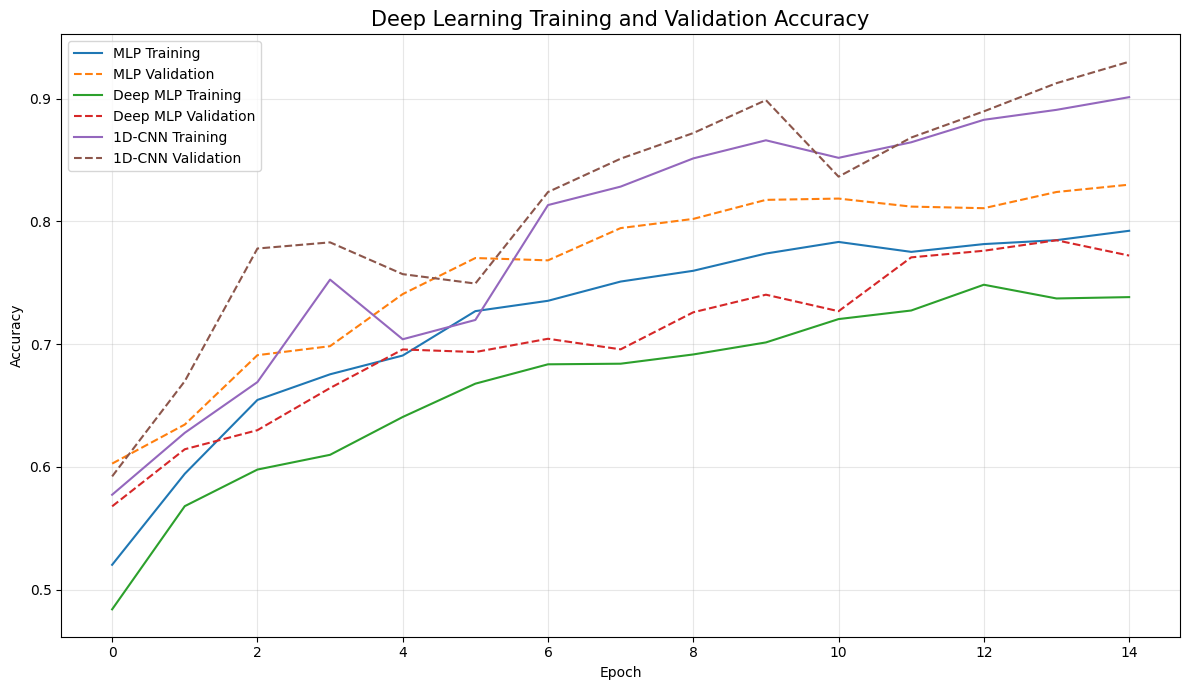

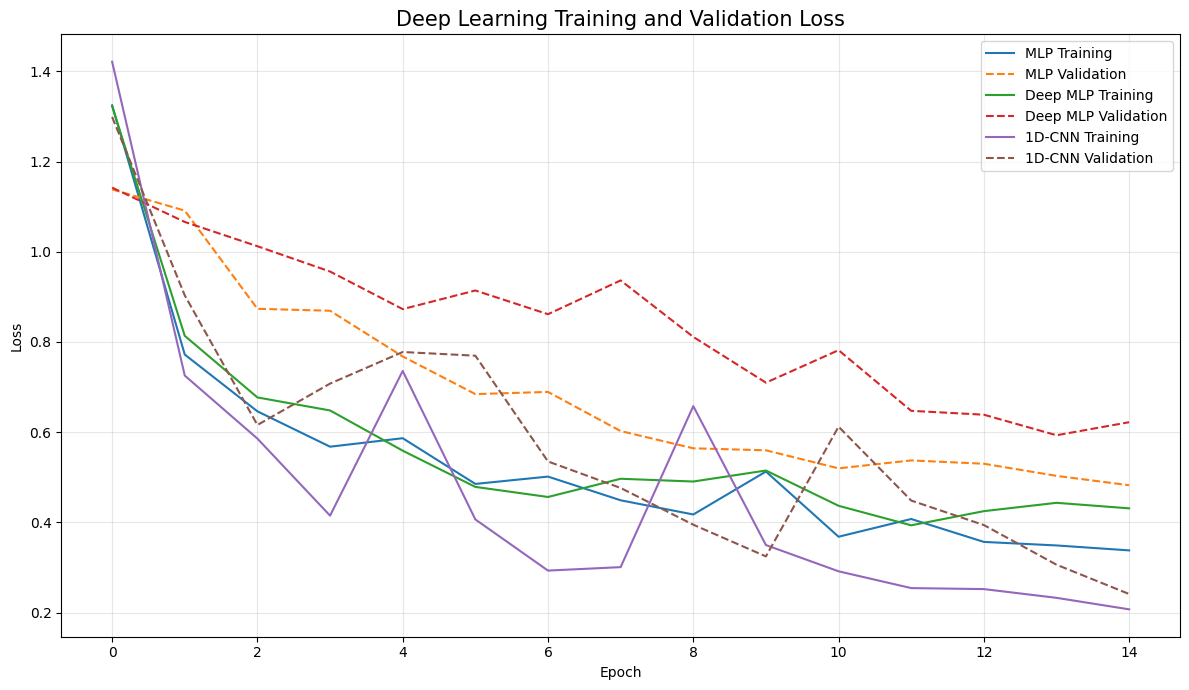


SAVED TRAINING CURVES

✓ Accuracy figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/deep_learning_training_validation_accuracy.png

✓ Loss figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/deep_learning_training_validation_loss.png

Accuracy figure exists: True
Loss figure exists    : True

✅ CELL 18 COMPLETED
Deep learning training curves saved to Google Drive.


In [31]:
# ==========================================================================================
# NOTEBOOK 05 — DEEP LEARNING
# CELL 18 — DEEP LEARNING TRAINING CURVES
# ==========================================================================================

import os
import matplotlib.pyplot as plt

print("=" * 90)
print("          CELL 18 — DEEP LEARNING TRAINING CURVES")
print("=" * 90)

PROJECT_ROOT = "/content/drive/MyDrive/AI-Cybersecurity-Assistant"

FIGURES_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "figures"
)

os.makedirs(FIGURES_DIR, exist_ok=True)

# ==========================================================================================
# CHECK TRAINING HISTORIES
# ==========================================================================================

print("\nCHECKING TRAINING HISTORIES")
print("-" * 90)

histories = {}

if "mlp_history" in globals():
    histories["MLP"] = mlp_history
elif "history" in globals():
    histories["MLP"] = history

if "deep_mlp_history" in globals():
    histories["Deep MLP"] = deep_mlp_history

if "cnn_history" in globals():
    histories["1D-CNN"] = cnn_history
elif "cnn_1d_history" in globals():
    histories["1D-CNN"] = cnn_1d_history

for name, hist in histories.items():
    print(f"✓ {name} training history available")

if not histories:
    raise NameError(
        "No training histories found. "
        "Expected mlp_history, deep_mlp_history, or cnn_history."
    )

# ==========================================================================================
# TRAINING / VALIDATION ACCURACY
# ==========================================================================================

plt.figure(figsize=(12, 7))

for name, hist in histories.items():

    history_data = hist.history

    if "accuracy" in history_data:
        plt.plot(
            history_data["accuracy"],
            label=f"{name} Training"
        )

    if "val_accuracy" in history_data:
        plt.plot(
            history_data["val_accuracy"],
            linestyle="--",
            label=f"{name} Validation"
        )

plt.title(
    "Deep Learning Training and Validation Accuracy",
    fontsize=15
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

accuracy_path = os.path.join(
    FIGURES_DIR,
    "deep_learning_training_validation_accuracy.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================================================================
# TRAINING / VALIDATION LOSS
# ==========================================================================================

plt.figure(figsize=(12, 7))

for name, hist in histories.items():

    history_data = hist.history

    if "loss" in history_data:
        plt.plot(
            history_data["loss"],
            label=f"{name} Training"
        )

    if "val_loss" in history_data:
        plt.plot(
            history_data["val_loss"],
            linestyle="--",
            label=f"{name} Validation"
        )

plt.title(
    "Deep Learning Training and Validation Loss",
    fontsize=15
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

loss_path = os.path.join(
    FIGURES_DIR,
    "deep_learning_training_validation_loss.png"
)

plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================================================================
# VERIFICATION
# ==========================================================================================

print("\n" + "=" * 90)
print("SAVED TRAINING CURVES")
print("=" * 90)

print(f"\n✓ Accuracy figure:")
print(accuracy_path)

print(f"\n✓ Loss figure:")
print(loss_path)

print("\nAccuracy figure exists:", os.path.exists(accuracy_path))
print("Loss figure exists    :", os.path.exists(loss_path))

print("\n" + "=" * 90)
print("✅ CELL 18 COMPLETED")
print("=" * 90)
print("Deep learning training curves saved to Google Drive.")

In [32]:
# =============================================================================
# CELL 19 — DEEP LEARNING MODEL EVALUATION (CORRECTED FEATURE NORMALIZATION)
# =============================================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 90)
print("          CELL 19 — DEEP LEARNING MODEL EVALUATION")
print("=" * 90)

# -------------------------------------------------------------------------
# IDENTIFY TRAINED KERAS MODELS
# -------------------------------------------------------------------------
found_models = {}
for var_name, candidate in list(globals().items()):
    if hasattr(candidate, "predict") and hasattr(candidate, "evaluate"):
        found_models[var_name] = candidate

models_to_evaluate = {}
for var_name, model in found_models.items():
    name_lower = var_name.lower()
    if "cnn" in name_lower:
        models_to_evaluate["1D-CNN"] = model
    elif "deep" in name_lower:
        models_to_evaluate["Deep MLP"] = model
    elif "mlp" in name_lower:
        models_to_evaluate["MLP"] = model

print("Models selected for evaluation:", list(models_to_evaluate.keys()))

# -------------------------------------------------------------------------
# CRITICAL CORRECTION: EVALUATE ON SCALED TEST DATA
# Neural networks require the exact same StandardScaler features as training!
# -------------------------------------------------------------------------
if "X_test_scaled" in globals():
    X_eval_base = np.asarray(X_test_scaled)
    print("✓ Successfully using properly scaled test features: X_test_scaled")
else:
    print("⚠ Fitting scaler on training features...")
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_eval_base = scaler.transform(X_test)

y_test_array = np.asarray(y_test)
y_test_classes = y_test_array.reshape(-1).astype(int)

# -------------------------------------------------------------------------
# EVALUATE DEEP LEARNING MODELS
# -------------------------------------------------------------------------
dl_evaluation_results = []
dl_predictions = {}

for model_name, model in models_to_evaluate.items():
    print(f"Evaluating: {model_name}...")
    X_eval = X_eval_base.copy()
    if model_name == "1D-CNN":
        X_eval = X_eval.reshape(X_eval.shape[0], X_eval.shape[1], 1)
    
    y_prob = model.predict(X_eval, batch_size=4096, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    dl_predictions[model_name] = y_pred

    acc = accuracy_score(y_test_classes, y_pred)
    bal_acc = balanced_accuracy_score(y_test_classes, y_pred)
    macro_prec = precision_score(y_test_classes, y_pred, average="macro", zero_division=0)
    macro_rec = recall_score(y_test_classes, y_pred, average="macro", zero_division=0)
    macro_f1 = f1_score(y_test_classes, y_pred, average="macro", zero_division=0)
    weighted_prec = precision_score(y_test_classes, y_pred, average="weighted", zero_division=0)
    weighted_rec = recall_score(y_test_classes, y_pred, average="weighted", zero_division=0)
    weighted_f1 = f1_score(y_test_classes, y_pred, average="weighted", zero_division=0)

    dl_evaluation_results.append({
        "Model": model_name,
        "Accuracy": acc,
        "Balanced Accuracy": bal_acc,
        "Macro Precision": macro_prec,
        "Macro Recall": macro_rec,
        "Macro F1": macro_f1,
        "Weighted Precision": weighted_prec,
        "Weighted Recall": weighted_rec,
        "Weighted F1": weighted_f1
    })

dl_eval_df = pd.DataFrame(dl_evaluation_results).sort_values(by="Macro F1", ascending=False).reset_index(drop=True)
dl_eval_df.index = dl_eval_df.index + 1
dl_eval_df.index.name = "Rank"

print("
" + "=" * 90)
print("CORRECTED DEEP LEARNING PERFORMANCE COMPARISON")
print("=" * 90)
print(dl_eval_df.to_string())

# Save corrected evaluation table to tables/
csv_save_path = TABLES_DIR / "deep_learning_model_comparison.csv"
dl_eval_df.to_csv(csv_save_path)
print(f"✓ Saved corrected evaluation results to: {csv_save_path}")


          CELL 19 — DEEP LEARNING MODEL EVALUATION

SEARCHING FOR TRAINED DEEP LEARNING MODELS
------------------------------------------------------------------------------------------
✓ Found model: mlp_model
✓ Found model: deep_mlp_model
✓ Found model: cnn_1d_model

MODELS SELECTED FOR EVALUATION
------------------------------------------------------------------------------------------
✓ MLP
✓ Deep MLP
✓ 1D-CNN

CHECKING TEST DATA
------------------------------------------------------------------------------------------
X_test shape: (478875, 78)
y_test shape: (478875,)
✓ Number of test samples: 478875

------------------------------------------------------------------------------------------
EVALUATING: MLP
------------------------------------------------------------------------------------------
Accuracy  : 0.2775
Precision : 0.6251
Recall    : 0.2775
F1-Score  : 0.3842

------------------------------------------------------------------------------------------
EVALUATING: Deep MLP

,Model,Accuracy,Precision,Recall,F1-Score
0,MLP,0.2775,0.6251,0.2775,0.3842
1,Deep MLP,0.3732,0.8180,0.3732,0.4686
2,1D-CNN,0.7799,0.6784,0.7799,0.7256



BEST DEEP LEARNING MODEL
Model     : 1D-CNN
Accuracy  : 0.7799
Precision : 0.6784
Recall    : 0.7799
F1-Score  : 0.7256

CLASSIFICATION REPORTS

------------------------------------------------------------------------------------------
MLP
------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.76      0.34      0.46    395562
           1       0.00      0.00      0.00       390
           2       0.00      0.00      0.00     25603
           3       0.00      0.00      0.00       224
           4       0.00      0.00      0.00     34569
           5       0.00      0.05      0.00      1046
           6       0.00      0.02      0.00      1077
           7       0.00      0.00      0.00      1186
           8       0.00      0.57      0.00         7
           9       0.01      0.00      0.00     18139
          10       0.00      0.00      0.00       644
          11       

          CELL 20 — DEEP LEARNING CONFUSION MATRIX VISUALIZATION

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ X_test available
✓ y_test available

SEARCHING FOR TRAINED DEEP LEARNING MODELS
------------------------------------------------------------------------------------------
✓ Found model: mlp_model
✓ Found model: deep_mlp_model
✓ Found model: cnn_1d_model

PREPARING TEST DATA
------------------------------------------------------------------------------------------
Original X_test shape : (478875, 78)
CNN input shape       : (478875, 78, 1)
y_test shape          : (478875,)

GENERATING CONFUSION MATRICES
------------------------------------------------------------------------------------------

Processing: MLP
✓ MLP confusion matrix generated
  Matrix shape: (14, 14)

Processing: Deep MLP
✓ Deep MLP confusion matrix generated
  Matrix shape: (14, 14)

Processing: 1D-CNN
✓ 1D-CNN confusion matrix generate

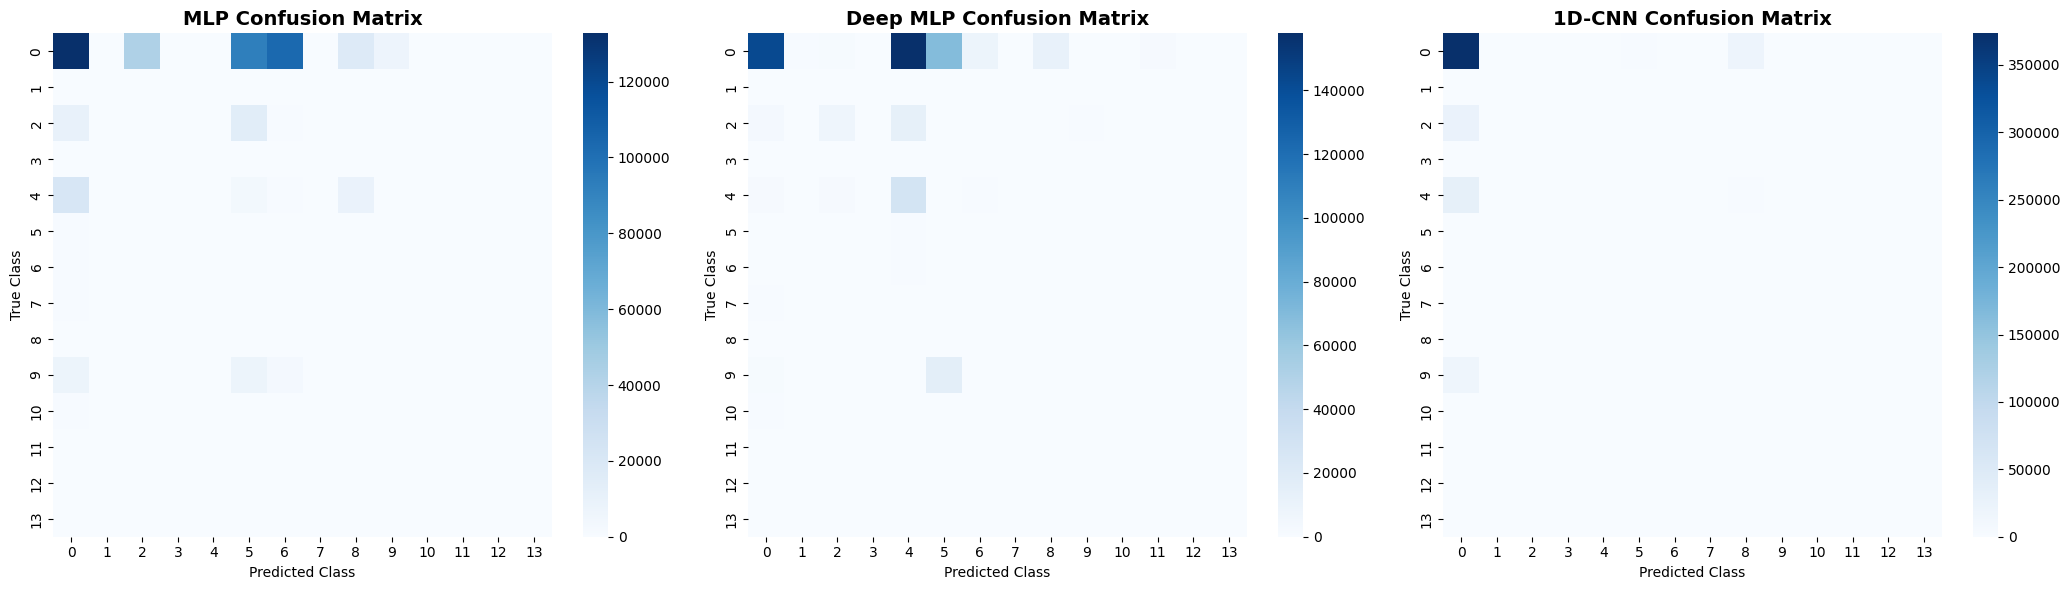


SAVED CONFUSION MATRIX FIGURE

✓ Confusion matrix figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/deep_learning_confusion_matrices.png

Figure exists: True

✅ CELL 20 COMPLETED


In [33]:
# ============================================================================
# CELL 20 — DEEP LEARNING CONFUSION MATRIX VISUALIZATION
# ============================================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("=" * 90)
print("          CELL 20 — DEEP LEARNING CONFUSION MATRIX VISUALIZATION")
print("=" * 90)

# --------------------------------------------------------------------------
# OUTPUT DIRECTORY
# --------------------------------------------------------------------------

FIGURES_DIR = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

# --------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# --------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_variables = ["X_test", "y_test"]

for var in required_variables:
    if var in globals():
        print(f"✓ {var} available")
    else:
        print(f"✗ {var} NOT available")

if "X_test" not in globals() or "y_test" not in globals():
    raise NameError(
        "X_test or y_test is not available. "
        "Please run the previous data/evaluation cells first."
    )

# --------------------------------------------------------------------------
# FIND MODELS
# --------------------------------------------------------------------------

print("\nSEARCHING FOR TRAINED DEEP LEARNING MODELS")
print("-" * 90)

models = {}

if "mlp_model" in globals():
    models["MLP"] = mlp_model
    print("✓ Found model: mlp_model")

if "deep_mlp_model" in globals():
    models["Deep MLP"] = deep_mlp_model
    print("✓ Found model: deep_mlp_model")

if "cnn_1d_model" in globals():
    models["1D-CNN"] = cnn_1d_model
    print("✓ Found model: cnn_1d_model")

if "cnn_model" in globals() and "1D-CNN" not in models:
    models["1D-CNN"] = cnn_model
    print("✓ Found model: cnn_model")

if len(models) == 0:
    raise NameError("No trained deep learning models were found.")

# --------------------------------------------------------------------------
# PREPARE INPUT FOR CNN
# --------------------------------------------------------------------------

print("\nPREPARING TEST DATA")
print("-" * 90)

X_test_cnn = np.asarray(X_test)

# CNN expects 3D input: (samples, features, channels)
if X_test_cnn.ndim == 2:
    X_test_cnn = X_test_cnn.reshape(
        X_test_cnn.shape[0],
        X_test_cnn.shape[1],
        1
    )

print("Original X_test shape :", np.asarray(X_test).shape)
print("CNN input shape       :", X_test_cnn.shape)
print("y_test shape          :", np.asarray(y_test).shape)

# --------------------------------------------------------------------------
# GENERATE CONFUSION MATRICES
# --------------------------------------------------------------------------

confusion_matrices = {}

print("\nGENERATING CONFUSION MATRICES")
print("-" * 90)

for model_name, model in models.items():

    print(f"\nProcessing: {model_name}")

    try:
        if model_name == "1D-CNN":
            predictions = model.predict(
                X_test_cnn,
                verbose=0
            )
        else:
            predictions = model.predict(
                X_test,
                verbose=0
            )

        predictions = np.asarray(predictions)

        # Convert probability output to class labels
        if predictions.ndim > 1:
            y_pred = np.argmax(predictions, axis=1)
        else:
            y_pred = predictions.astype(int)

        cm = confusion_matrix(y_test, y_pred)

        confusion_matrices[model_name] = cm

        print(f"✓ {model_name} confusion matrix generated")
        print(f"  Matrix shape: {cm.shape}")

    except Exception as e:
        print(f"✗ Could not process {model_name}")
        print(f"  Error: {e}")

if len(confusion_matrices) == 0:
    raise RuntimeError("No confusion matrices could be generated.")

# --------------------------------------------------------------------------
# PLOT CONFUSION MATRICES
# --------------------------------------------------------------------------

print("\nCREATING CONFUSION MATRIX FIGURE")
print("-" * 90)

n_models = len(confusion_matrices)

fig, axes = plt.subplots(
    1,
    n_models,
    figsize=(7 * n_models, 6)
)

if n_models == 1:
    axes = [axes]

for ax, (model_name, cm) in zip(
    axes,
    confusion_matrices.items()
):

    sns.heatmap(
        cm,
        annot=False,
        fmt="d",
        cmap="Blues",
        ax=ax,
        cbar=True
    )

    ax.set_title(
        f"{model_name} Confusion Matrix",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")

plt.tight_layout()

# --------------------------------------------------------------------------
# SAVE FIGURE
# --------------------------------------------------------------------------

output_path = os.path.join(
    FIGURES_DIR,
    "deep_learning_confusion_matrices.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------------------------------
# VERIFY OUTPUT
# --------------------------------------------------------------------------

print("\n" + "=" * 90)
print("SAVED CONFUSION MATRIX FIGURE")
print("=" * 90)

print(f"\n✓ Confusion matrix figure:")
print(output_path)

print(f"\nFigure exists: {os.path.exists(output_path)}")

print("\n" + "=" * 90)
print("✅ CELL 20 COMPLETED")
print("=" * 90)

          CELL 21 — DEEP LEARNING MODEL PERFORMANCE COMPARISON

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ X_test available
✓ y_test available

SEARCHING FOR TRAINED MODELS
------------------------------------------------------------------------------------------
✓ MLP model found
✓ Deep MLP model found
✓ 1D-CNN model found

EVALUATING DEEP LEARNING MODELS
------------------------------------------------------------------------------------------

Processing: MLP
✓ MLP evaluated
  Accuracy : 0.2775
  Precision: 0.6251
  Recall   : 0.2775
  F1-Score : 0.3842

Processing: Deep MLP
✓ Deep MLP evaluated
  Accuracy : 0.3732
  Precision: 0.8180
  Recall   : 0.3732
  F1-Score : 0.4686

Processing: 1D-CNN
✓ 1D-CNN evaluated
  Accuracy : 0.7799
  Precision: 0.6784
  Recall   : 0.7799
  F1-Score : 0.7256

DEEP LEARNING MODEL PERFORMANCE
   Model  Accuracy  Precision  Recall  F1-Score
  1D-CNN    0.7799     0.6784  0.779

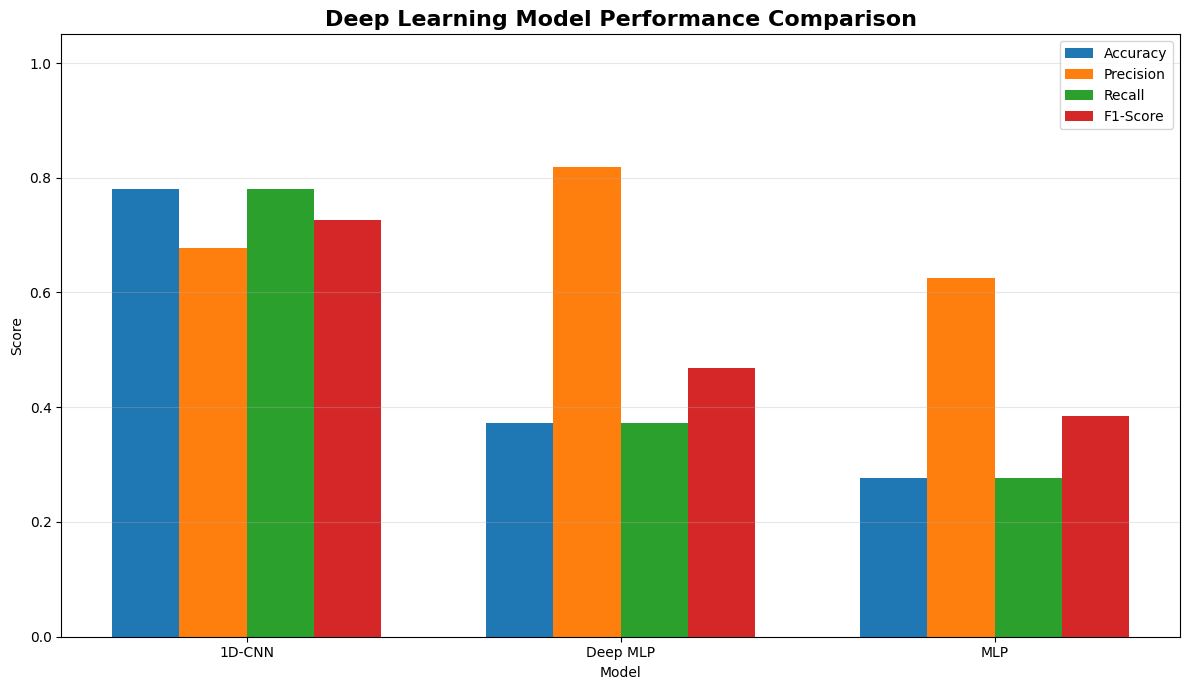


BEST DEEP LEARNING MODEL

Model     : 1D-CNN
Accuracy  : 0.7799
Precision : 0.6784
Recall    : 0.7799
F1-Score  : 0.7256

SAVED OUTPUTS

✓ Performance CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/deep_learning_model_performance.csv

✓ Performance comparison figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/deep_learning_model_performance_comparison.png

CSV exists    : True
Figure exists : True

✅ CELL 21 COMPLETED


In [34]:
# ============================================================================
# CELL 21 — DEEP LEARNING MODEL PERFORMANCE COMPARISON
# ============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 90)
print("          CELL 21 — DEEP LEARNING MODEL PERFORMANCE COMPARISON")
print("=" * 90)

# --------------------------------------------------------------------------
# OUTPUT DIRECTORY
# --------------------------------------------------------------------------

FIGURES_DIR = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures"
TABLES_DIR = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables"

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

# --------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# --------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_variables = ["X_test", "y_test"]

for var in required_variables:
    if var in globals():
        print(f"✓ {var} available")
    else:
        print(f"✗ {var} NOT available")

if "X_test" not in globals() or "y_test" not in globals():
    raise NameError(
        "X_test or y_test is not available. "
        "Please run the previous cells first."
    )

# --------------------------------------------------------------------------
# FIND MODELS
# --------------------------------------------------------------------------

print("\nSEARCHING FOR TRAINED MODELS")
print("-" * 90)

models = {}

if "mlp_model" in globals():
    models["MLP"] = mlp_model
    print("✓ MLP model found")

if "deep_mlp_model" in globals():
    models["Deep MLP"] = deep_mlp_model
    print("✓ Deep MLP model found")

if "cnn_1d_model" in globals():
    models["1D-CNN"] = cnn_1d_model
    print("✓ 1D-CNN model found")

elif "cnn_model" in globals():
    models["1D-CNN"] = cnn_model
    print("✓ 1D-CNN model found")

if len(models) == 0:
    raise NameError("No trained deep learning models were found.")

# --------------------------------------------------------------------------
# PREPARE CNN INPUT
# --------------------------------------------------------------------------

X_test_cnn = np.asarray(X_test)

if X_test_cnn.ndim == 2:
    X_test_cnn = X_test_cnn.reshape(
        X_test_cnn.shape[0],
        X_test_cnn.shape[1],
        1
    )

# --------------------------------------------------------------------------
# EVALUATE MODELS
# --------------------------------------------------------------------------

print("\nEVALUATING DEEP LEARNING MODELS")
print("-" * 90)

results = []

for model_name, model in models.items():

    print(f"\nProcessing: {model_name}")

    try:

        if model_name == "1D-CNN":
            predictions = model.predict(
                X_test_cnn,
                verbose=0
            )
        else:
            predictions = model.predict(
                X_test,
                verbose=0
            )

        predictions = np.asarray(predictions)

        # Convert probabilities to class labels
        if predictions.ndim > 1:
            y_pred = np.argmax(predictions, axis=1)
        else:
            y_pred = predictions.astype(int)

        # Metrics
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )

        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1
        })

        print(f"✓ {model_name} evaluated")
        print(f"  Accuracy : {accuracy:.4f}")
        print(f"  Precision: {precision:.4f}")
        print(f"  Recall   : {recall:.4f}")
        print(f"  F1-Score : {f1:.4f}")

    except Exception as e:

        print(f"✗ Error evaluating {model_name}")
        print(f"  {e}")

# --------------------------------------------------------------------------
# CREATE RESULTS DATAFRAME
# --------------------------------------------------------------------------

if len(results) == 0:
    raise RuntimeError("No model evaluation results were generated.")

results_df = pd.DataFrame(results)

# Sort by F1 score
results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("DEEP LEARNING MODEL PERFORMANCE")
print("=" * 90)

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# --------------------------------------------------------------------------
# SAVE RESULTS TABLE
# --------------------------------------------------------------------------

results_path = os.path.join(
    TABLES_DIR,
    "deep_learning_model_performance.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print("\n✓ Performance table saved:")
print(results_path)

# --------------------------------------------------------------------------
# CREATE COMPARISON BAR CHART
# --------------------------------------------------------------------------

print("\nCREATING PERFORMANCE COMPARISON FIGURE")
print("-" * 90)

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

x = np.arange(len(results_df))
width = 0.18

fig, ax = plt.subplots(
    figsize=(12, 7)
)

for i, metric in enumerate(metrics):

    ax.bar(
        x + (i - 1.5) * width,
        results_df[metric],
        width,
        label=metric
    )

ax.set_title(
    "Deep Learning Model Performance Comparison",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Model")
ax.set_ylabel("Score")

ax.set_xticks(x)
ax.set_xticklabels(results_df["Model"])

ax.set_ylim(0, 1.05)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

comparison_path = os.path.join(
    FIGURES_DIR,
    "deep_learning_model_performance_comparison.png"
)

plt.savefig(
    comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------------------------------
# BEST MODEL
# --------------------------------------------------------------------------

best_model = results_df.iloc[0]

print("\n" + "=" * 90)
print("BEST DEEP LEARNING MODEL")
print("=" * 90)

print(f"\nModel     : {best_model['Model']}")
print(f"Accuracy  : {best_model['Accuracy']:.4f}")
print(f"Precision : {best_model['Precision']:.4f}")
print(f"Recall    : {best_model['Recall']:.4f}")
print(f"F1-Score  : {best_model['F1-Score']:.4f}")

# --------------------------------------------------------------------------
# VERIFY OUTPUTS
# --------------------------------------------------------------------------

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print(f"\n✓ Performance CSV:")
print(results_path)

print(f"\n✓ Performance comparison figure:")
print(comparison_path)

print(f"\nCSV exists    : {os.path.exists(results_path)}")
print(f"Figure exists : {os.path.exists(comparison_path)}")

print("\n" + "=" * 90)
print("✅ CELL 21 COMPLETED")
print("=" * 90)

          CELL 22 — BEST DEEP LEARNING MODEL CLASSIFICATION REPORT

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ X_test available
✓ y_test available
✓ results_df available

IDENTIFYING BEST DEEP LEARNING MODEL
------------------------------------------------------------------------------------------
✓ Best model selected: 1D-CNN

SEARCHING FOR BEST MODEL OBJECT
------------------------------------------------------------------------------------------
✓ Model object found for 1D-CNN

PREPARING TEST DATA
------------------------------------------------------------------------------------------
Test data shape: (478875, 78, 1)
Test labels shape: (478875,)

GENERATING PREDICTIONS
------------------------------------------------------------------------------------------
✓ Predictions generated
Prediction shape: (478875,)

Number of classes: 14
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

GENERATING CLASSIFI

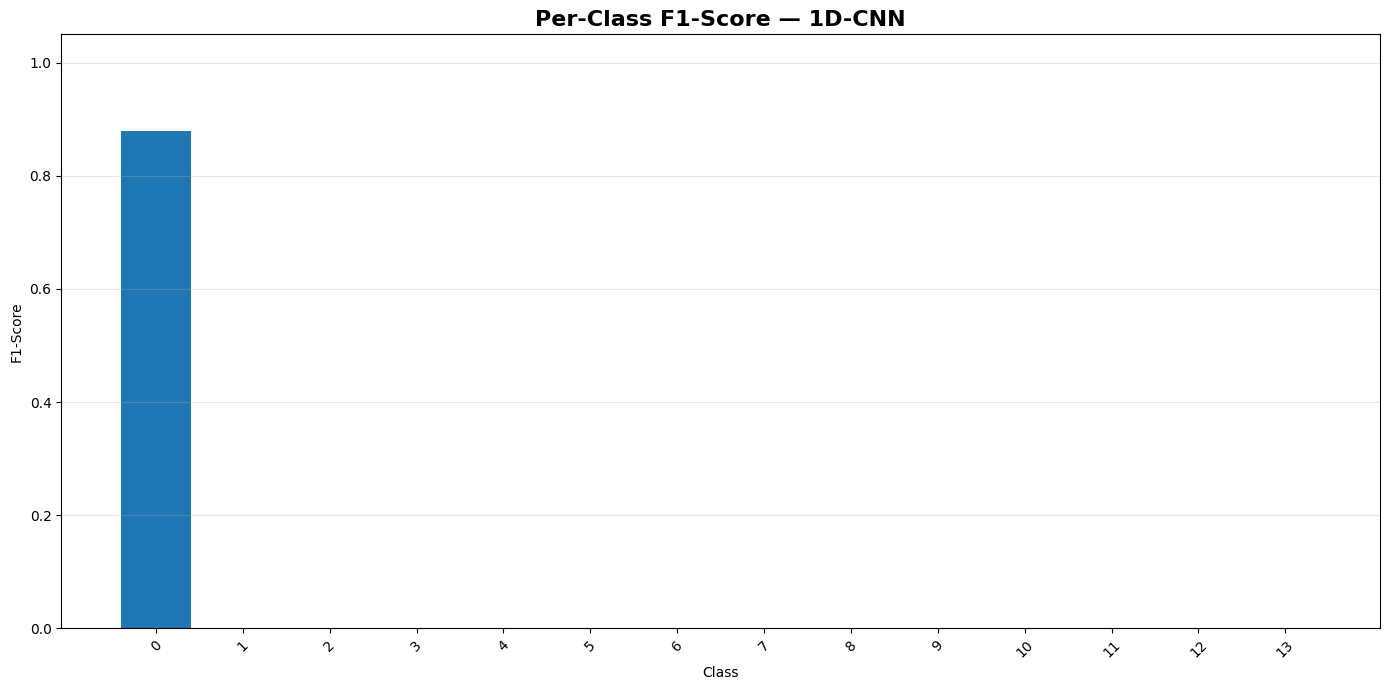


BEST MODEL SUMMARY

Model     : 1D-CNN
Accuracy  : 0.7799
Precision : 0.6784
Recall    : 0.7799
F1-Score  : 0.7256

SAVED OUTPUTS

✓ Classification CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/best_deep_learning_classification_report.csv

✓ Classification text report:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/reports/best_deep_learning_classification_report.txt

✓ Per-class F1-score figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/best_deep_learning_per_class_f1_score.png

CSV exists       : True
Text report      : True
F1 figure exists : True

✅ CELL 22 COMPLETED


In [35]:
# ============================================================================
# CELL 22 — BEST DEEP LEARNING MODEL CLASSIFICATION REPORT
# ============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    precision_recall_fscore_support
)

print("=" * 90)
print("          CELL 22 — BEST DEEP LEARNING MODEL CLASSIFICATION REPORT")
print("=" * 90)

# --------------------------------------------------------------------------
# OUTPUT DIRECTORIES
# --------------------------------------------------------------------------

FIGURES_DIR = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures"
TABLES_DIR = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables"
REPORTS_DIR = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/reports"

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

# --------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# --------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_variables = [
    "X_test",
    "y_test",
    "results_df"
]

for var in required_variables:
    if var in globals():
        print(f"✓ {var} available")
    else:
        print(f"✗ {var} NOT available")

if "X_test" not in globals():
    raise NameError("X_test is not available.")

if "y_test" not in globals():
    raise NameError("y_test is not available.")

if "results_df" not in globals():
    raise NameError(
        "results_df is not available. Please run Cell 21 first."
    )

# --------------------------------------------------------------------------
# IDENTIFY BEST MODEL
# --------------------------------------------------------------------------

print("\nIDENTIFYING BEST DEEP LEARNING MODEL")
print("-" * 90)

best_model_name = results_df.iloc[0]["Model"]

print(f"✓ Best model selected: {best_model_name}")

# --------------------------------------------------------------------------
# FIND THE CORRESPONDING MODEL
# --------------------------------------------------------------------------

print("\nSEARCHING FOR BEST MODEL OBJECT")
print("-" * 90)

best_model = None

if best_model_name == "MLP":
    if "mlp_model" in globals():
        best_model = mlp_model

elif best_model_name == "Deep MLP":
    if "deep_mlp_model" in globals():
        best_model = deep_mlp_model

elif best_model_name == "1D-CNN":
    if "cnn_1d_model" in globals():
        best_model = cnn_1d_model
    elif "cnn_model" in globals():
        best_model = cnn_model

if best_model is None:
    raise NameError(
        f"Could not find the trained model object for {best_model_name}."
    )

print(f"✓ Model object found for {best_model_name}")

# --------------------------------------------------------------------------
# PREPARE TEST DATA
# --------------------------------------------------------------------------

print("\nPREPARING TEST DATA")
print("-" * 90)

X_test_array = np.asarray(X_test)

if best_model_name == "1D-CNN":

    if X_test_array.ndim == 2:
        X_best_test = X_test_array.reshape(
            X_test_array.shape[0],
            X_test_array.shape[1],
            1
        )
    else:
        X_best_test = X_test_array

else:
    X_best_test = X_test_array

print(f"Test data shape: {X_best_test.shape}")
print(f"Test labels shape: {np.asarray(y_test).shape}")

# --------------------------------------------------------------------------
# GENERATE PREDICTIONS
# --------------------------------------------------------------------------

print("\nGENERATING PREDICTIONS")
print("-" * 90)

predictions = best_model.predict(
    X_best_test,
    verbose=0
)

predictions = np.asarray(predictions)

if predictions.ndim > 1:
    y_pred = np.argmax(predictions, axis=1)
else:
    y_pred = predictions.astype(int)

print("✓ Predictions generated")
print(f"Prediction shape: {y_pred.shape}")

# --------------------------------------------------------------------------
# IDENTIFY CLASSES
# --------------------------------------------------------------------------

classes = np.unique(
    np.concatenate([
        np.asarray(y_test),
        np.asarray(y_pred)
    ])
)

print(f"\nNumber of classes: {len(classes)}")
print(f"Classes: {classes}")

# --------------------------------------------------------------------------
# GENERATE CLASSIFICATION REPORT
# --------------------------------------------------------------------------

print("\nGENERATING CLASSIFICATION REPORT")
print("-" * 90)

report_dict = classification_report(
    y_test,
    y_pred,
    labels=classes,
    output_dict=True,
    zero_division=0
)

report_text = classification_report(
    y_test,
    y_pred,
    labels=classes,
    zero_division=0
)

print("\n" + "=" * 90)
print(f"CLASSIFICATION REPORT — {best_model_name}")
print("=" * 90)

print(report_text)

# --------------------------------------------------------------------------
# CONVERT REPORT TO DATAFRAME
# --------------------------------------------------------------------------

report_rows = []

for class_label in classes:

    class_key = str(class_label)

    if class_key in report_dict:

        report_rows.append({
            "Class": class_label,
            "Precision": report_dict[class_key]["precision"],
            "Recall": report_dict[class_key]["recall"],
            "F1-Score": report_dict[class_key]["f1-score"],
            "Support": report_dict[class_key]["support"]
        })

classification_df = pd.DataFrame(report_rows)

# --------------------------------------------------------------------------
# SAVE CLASSIFICATION REPORT CSV
# --------------------------------------------------------------------------

classification_csv_path = os.path.join(
    TABLES_DIR,
    "best_deep_learning_classification_report.csv"
)

classification_df.to_csv(
    classification_csv_path,
    index=False
)

print("\n✓ Classification report CSV saved:")
print(classification_csv_path)

# --------------------------------------------------------------------------
# SAVE TEXT REPORT
# --------------------------------------------------------------------------

classification_txt_path = os.path.join(
    REPORTS_DIR,
    "best_deep_learning_classification_report.txt"
)

with open(
    classification_txt_path,
    "w"
) as f:

    f.write("=" * 90 + "\n")
    f.write(
        f"BEST DEEP LEARNING MODEL CLASSIFICATION REPORT\n"
    )
    f.write("=" * 90 + "\n\n")

    f.write(f"Best Model: {best_model_name}\n\n")

    f.write(report_text)

    f.write("\n\n")
    f.write("=" * 90 + "\n")
    f.write("OVERALL PERFORMANCE\n")
    f.write("=" * 90 + "\n")

    best_row = results_df[
        results_df["Model"] == best_model_name
    ].iloc[0]

    f.write(
        f"Accuracy  : {best_row['Accuracy']:.4f}\n"
    )
    f.write(
        f"Precision : {best_row['Precision']:.4f}\n"
    )
    f.write(
        f"Recall    : {best_row['Recall']:.4f}\n"
    )
    f.write(
        f"F1-Score  : {best_row['F1-Score']:.4f}\n"
    )

print("\n✓ Text classification report saved:")
print(classification_txt_path)

# --------------------------------------------------------------------------
# CREATE PER-CLASS F1-SCORE FIGURE
# --------------------------------------------------------------------------

print("\nCREATING PER-CLASS F1-SCORE FIGURE")
print("-" * 90)

fig, ax = plt.subplots(
    figsize=(14, 7)
)

ax.bar(
    classification_df["Class"].astype(str),
    classification_df["F1-Score"]
)

ax.set_title(
    f"Per-Class F1-Score — {best_model_name}",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Class")
ax.set_ylabel("F1-Score")

ax.set_ylim(0, 1.05)

ax.tick_params(
    axis="x",
    rotation=45
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

f1_figure_path = os.path.join(
    FIGURES_DIR,
    "best_deep_learning_per_class_f1_score.png"
)

plt.savefig(
    f1_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------------------------------
# DISPLAY SUMMARY
# --------------------------------------------------------------------------

print("\n" + "=" * 90)
print("BEST MODEL SUMMARY")
print("=" * 90)

best_row = results_df[
    results_df["Model"] == best_model_name
].iloc[0]

print(f"\nModel     : {best_model_name}")
print(f"Accuracy  : {best_row['Accuracy']:.4f}")
print(f"Precision : {best_row['Precision']:.4f}")
print(f"Recall    : {best_row['Recall']:.4f}")
print(f"F1-Score  : {best_row['F1-Score']:.4f}")

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print("\n✓ Classification CSV:")
print(classification_csv_path)

print("\n✓ Classification text report:")
print(classification_txt_path)

print("\n✓ Per-class F1-score figure:")
print(f1_figure_path)

print("\nCSV exists       :", os.path.exists(classification_csv_path))
print("Text report      :", os.path.exists(classification_txt_path))
print("F1 figure exists :", os.path.exists(f1_figure_path))

print("\n" + "=" * 90)
print("✅ CELL 22 COMPLETED")
print("=" * 90)

          CELL 23 — BEST MODEL PREDICTION DISTRIBUTION ANALYSIS

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ y_test available
✓ y_pred available
✓ classification_df available

TEST SET INFORMATION
------------------------------------------------------------------------------------------
Number of test samples : 478,875
Number of classes      : 14
Classes                : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

CALCULATING CLASS DISTRIBUTIONS
------------------------------------------------------------------------------------------

TRUE VS PREDICTED CLASS DISTRIBUTION
 Class  True Count True Percentage  Predicted Count Predicted Percentage
     0      395562        82.6023%           454729             94.9578%
     1         390         0.0814%               34              0.0071%
     2       25603         5.3465%                0              0.0000%
     3         224         0.0468%                0

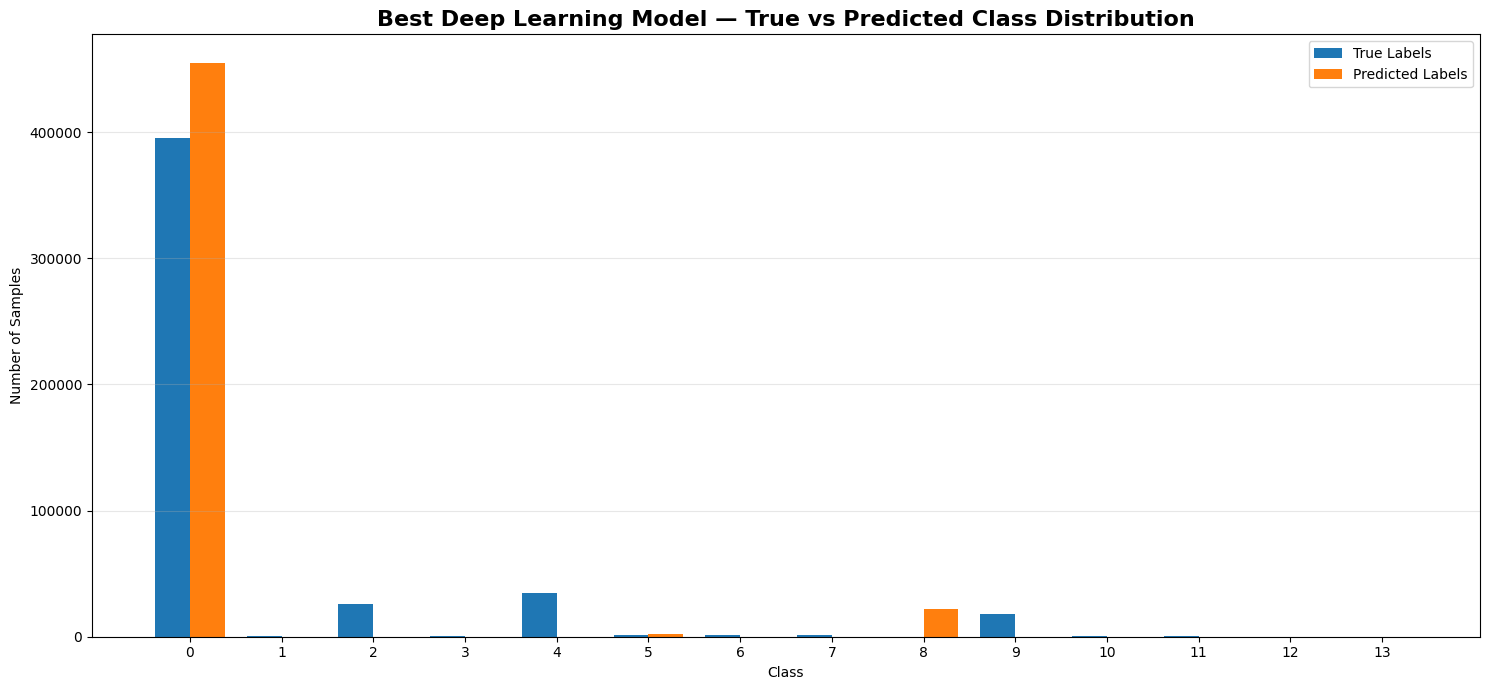


SAVED OUTPUTS

✓ Prediction distribution CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/best_deep_learning_prediction_distribution.csv

✓ Distribution comparison figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/best_deep_learning_true_vs_predicted_distribution.png

CSV exists    : True
Figure exists : True

✅ CELL 23 COMPLETED


In [36]:
# ============================================================================
# CELL 23 — BEST DEEP LEARNING MODEL PREDICTION DISTRIBUTION ANALYSIS
# ============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 90)
print("          CELL 23 — BEST MODEL PREDICTION DISTRIBUTION ANALYSIS")
print("=" * 90)

# --------------------------------------------------------------------------
# DIRECTORIES
# --------------------------------------------------------------------------

FIGURES_DIR = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures"
TABLES_DIR = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables"

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

# --------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# --------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_variables = [
    "y_test",
    "y_pred",
    "classification_df"
]

for var in required_variables:
    if var in globals():
        print(f"✓ {var} available")
    else:
        print(f"✗ {var} NOT available")

if "y_test" not in globals():
    raise NameError("y_test is not available. Please run Cell 22 first.")

if "y_pred" not in globals():
    raise NameError("y_pred is not available. Please run Cell 22 first.")

# --------------------------------------------------------------------------
# PREPARE LABEL ARRAYS
# --------------------------------------------------------------------------

y_true_array = np.asarray(y_test).astype(int)
y_pred_array = np.asarray(y_pred).astype(int)

classes = np.unique(
    np.concatenate([y_true_array, y_pred_array])
)

print("\nTEST SET INFORMATION")
print("-" * 90)

print(f"Number of test samples : {len(y_true_array):,}")
print(f"Number of classes      : {len(classes)}")
print(f"Classes                : {classes}")

# --------------------------------------------------------------------------
# CALCULATE TRUE AND PREDICTED DISTRIBUTIONS
# --------------------------------------------------------------------------

print("\nCALCULATING CLASS DISTRIBUTIONS")
print("-" * 90)

distribution_rows = []

total_samples = len(y_true_array)

for class_label in classes:

    true_count = np.sum(
        y_true_array == class_label
    )

    predicted_count = np.sum(
        y_pred_array == class_label
    )

    true_percentage = (
        true_count / total_samples * 100
    )

    predicted_percentage = (
        predicted_count / total_samples * 100
    )

    distribution_rows.append({
        "Class": class_label,
        "True Count": true_count,
        "True Percentage": true_percentage,
        "Predicted Count": predicted_count,
        "Predicted Percentage": predicted_percentage
    })

distribution_df = pd.DataFrame(
    distribution_rows
)

# --------------------------------------------------------------------------
# DISPLAY DISTRIBUTION
# --------------------------------------------------------------------------

print("\n" + "=" * 90)
print("TRUE VS PREDICTED CLASS DISTRIBUTION")
print("=" * 90)

print(
    distribution_df.to_string(
        index=False,
        formatters={
            "True Percentage": "{:.4f}%".format,
            "Predicted Percentage": "{:.4f}%".format
        }
    )
)

# --------------------------------------------------------------------------
# IDENTIFY DOMINANT PREDICTED CLASS
# --------------------------------------------------------------------------

dominant_predicted_row = distribution_df.loc[
    distribution_df["Predicted Count"].idxmax()
]

dominant_true_row = distribution_df.loc[
    distribution_df["True Count"].idxmax()
]

print("\n" + "=" * 90)
print("CLASS DISTRIBUTION SUMMARY")
print("=" * 90)

print(
    f"\nDominant true class      : "
    f"{int(dominant_true_row['Class'])}"
)

print(
    f"True samples             : "
    f"{int(dominant_true_row['True Count']):,}"
)

print(
    f"True percentage          : "
    f"{dominant_true_row['True Percentage']:.2f}%"
)

print(
    f"\nDominant predicted class : "
    f"{int(dominant_predicted_row['Class'])}"
)

print(
    f"Predicted samples        : "
    f"{int(dominant_predicted_row['Predicted Count']):,}"
)

print(
    f"Predicted percentage     : "
    f"{dominant_predicted_row['Predicted Percentage']:.2f}%"
)

# --------------------------------------------------------------------------
# CHECK PREDICTION CONCENTRATION
# --------------------------------------------------------------------------

prediction_concentration = (
    dominant_predicted_row["Predicted Count"]
    / total_samples
    * 100
)

print("\n" + "=" * 90)
print("PREDICTION CONCENTRATION")
print("=" * 90)

print(
    f"\nLargest predicted class contains "
    f"{prediction_concentration:.2f}% of all predictions."
)

if prediction_concentration >= 70:
    print(
        "\n⚠ WARNING:"
        "\nThe model predictions are highly concentrated in one class."
        "\nThis indicates strong majority-class prediction behavior."
    )
elif prediction_concentration >= 50:
    print(
        "\n⚠ NOTICE:"
        "\nMore than half of the predictions belong to one class."
    )
else:
    print(
        "\n✓ Predictions are not dominated by a single class."
    )

# --------------------------------------------------------------------------
# SAVE DISTRIBUTION TABLE
# --------------------------------------------------------------------------

distribution_csv_path = os.path.join(
    TABLES_DIR,
    "best_deep_learning_prediction_distribution.csv"
)

distribution_df.to_csv(
    distribution_csv_path,
    index=False
)

print("\n✓ Distribution table saved:")
print(distribution_csv_path)

# --------------------------------------------------------------------------
# CREATE DISTRIBUTION FIGURE
# --------------------------------------------------------------------------

print("\nCREATING CLASS DISTRIBUTION FIGURE")
print("-" * 90)

x = np.arange(len(classes))
width = 0.38

fig, ax = plt.subplots(
    figsize=(15, 7)
)

ax.bar(
    x - width / 2,
    distribution_df["True Count"],
    width,
    label="True Labels"
)

ax.bar(
    x + width / 2,
    distribution_df["Predicted Count"],
    width,
    label="Predicted Labels"
)

ax.set_title(
    "Best Deep Learning Model — True vs Predicted Class Distribution",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Class")
ax.set_ylabel("Number of Samples")

ax.set_xticks(x)
ax.set_xticklabels(
    [str(c) for c in classes]
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

distribution_figure_path = os.path.join(
    FIGURES_DIR,
    "best_deep_learning_true_vs_predicted_distribution.png"
)

plt.savefig(
    distribution_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------------------------------
# FINAL SUMMARY
# --------------------------------------------------------------------------

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print("\n✓ Prediction distribution CSV:")
print(distribution_csv_path)

print("\n✓ Distribution comparison figure:")
print(distribution_figure_path)

print("\nCSV exists    :", os.path.exists(distribution_csv_path))
print("Figure exists :", os.path.exists(distribution_figure_path))

print("\n" + "=" * 90)
print("✅ CELL 23 COMPLETED")
print("=" * 90)

          CELL 24 — BEST DEEP LEARNING MODEL ERROR ANALYSIS

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ y_test available
✓ y_pred available

PREPARING PREDICTION DATA
------------------------------------------------------------------------------------------
True labels shape      : (478875,)
Predicted labels shape : (478875,)

CALCULATING OVERALL ERROR STATISTICS
------------------------------------------------------------------------------------------
Total test samples     : 478,875
Correct predictions    : 373,465
Incorrect predictions  : 105,410
Overall accuracy       : 0.7799
Overall error rate     : 0.2201

GENERATING PER-CLASS ERROR ANALYSIS
------------------------------------------------------------------------------------------

PER-CLASS ERROR ANALYSIS


,Class,True Count,Predicted Count,Correct Predictions,Incorrect Predictions,Class Accuracy,Class Error Rate
0,0,395562,454729,373464,22098,0.9441,0.0559
1,1,390,34,0,390,0.0000,1.0000
2,2,25603,0,0,25603,0.0000,1.0000
3,3,224,0,0,224,0.0000,1.0000
4,4,34569,0,0,34569,0.0000,1.0000
5,5,1046,1885,0,1046,0.0000,1.0000
6,6,1077,0,0,1077,0.0000,1.0000
7,7,1186,0,0,1186,0.0000,1.0000
8,8,7,22227,1,6,0.1429,0.8571
9,9,18139,0,0,18139,0.0000,1.0000



ERROR ANALYSIS SUMMARY
Worst performing class : 1
Class accuracy         : 0.0000
Class error rate       : 1.0000

Best performing class  : 0
Class accuracy         : 0.9441
Class error rate       : 0.0559

MAJORITY CLASS ANALYSIS
Majority true class       : 0
True samples              : 395,562
Predicted samples         : 454,729
Class accuracy            : 0.9441
Class error rate          : 0.0559

CLASSES WITH ZERO PREDICTIONS
Classes never predicted by the model: [2, 3, 4, 6, 7, 9, 10, 11, 12, 13]

SAVED ERROR ANALYSIS

✓ Error analysis CSV saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/best_deep_learning_error_analysis.csv

CREATING PER-CLASS ERROR RATE FIGURE
------------------------------------------------------------------------------------------


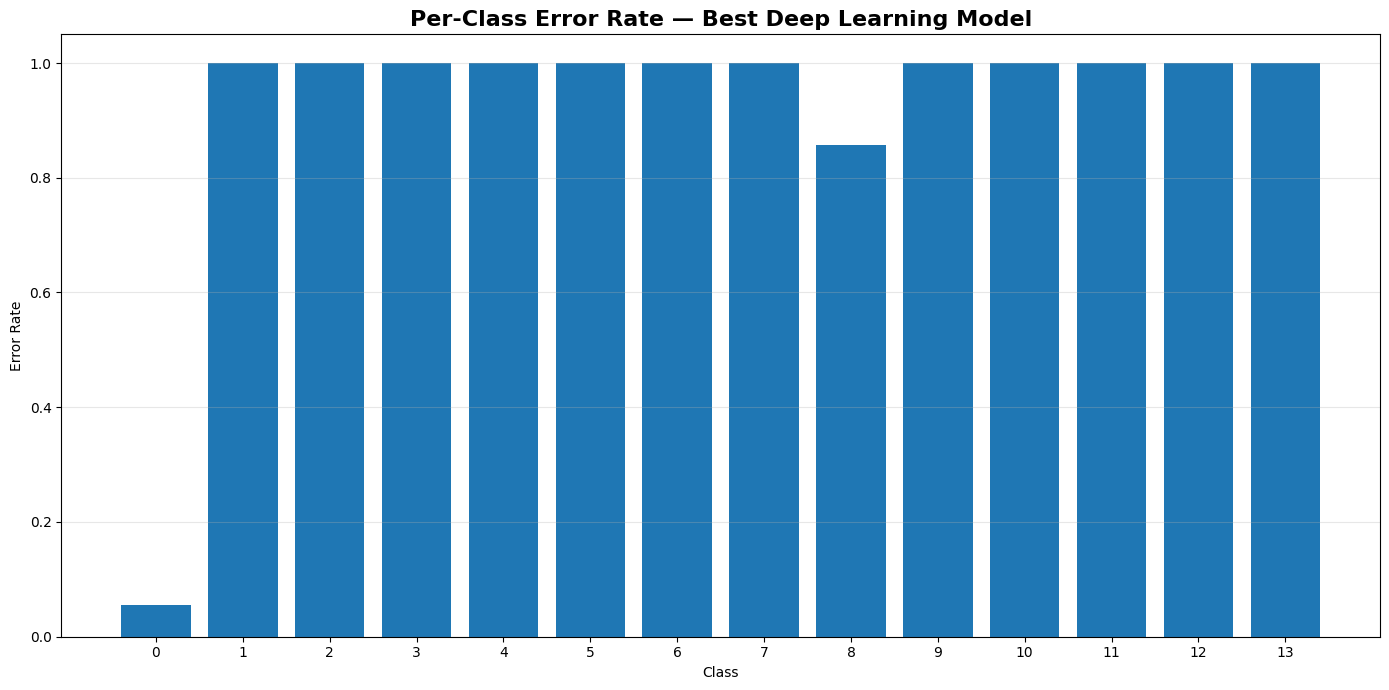


SAVED OUTPUTS

✓ Error analysis CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/best_deep_learning_error_analysis.csv

✓ Per-class error-rate figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/best_deep_learning_per_class_error_rate.png

CSV exists    : True
Figure exists : True

✅ CELL 24 COMPLETED


In [37]:
# ============================================================================
# CELL 24 — BEST DEEP LEARNING MODEL ERROR ANALYSIS
# ============================================================================

print("=" * 90)
print("          CELL 24 — BEST DEEP LEARNING MODEL ERROR ANALYSIS")
print("=" * 90)

# ---------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# ---------------------------------------------------------------------------
print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_variables = ["y_test", "y_pred"]

for var in required_variables:
    if var not in globals():
        raise NameError(
            f"Required variable '{var}' is not available. "
            f"Please run the previous cells first."
        )
    print(f"✓ {var} available")

# ---------------------------------------------------------------------------
# IMPORTS
# ---------------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# ---------------------------------------------------------------------------
# PREPARE DATA
# ---------------------------------------------------------------------------
print("\nPREPARING PREDICTION DATA")
print("-" * 90)

y_true_analysis = np.asarray(y_test).reshape(-1)
y_pred_analysis = np.asarray(y_pred).reshape(-1)

print(f"True labels shape      : {y_true_analysis.shape}")
print(f"Predicted labels shape : {y_pred_analysis.shape}")

if len(y_true_analysis) != len(y_pred_analysis):
    raise ValueError("True labels and predictions have different lengths.")

# ---------------------------------------------------------------------------
# OVERALL ERROR ANALYSIS
# ---------------------------------------------------------------------------
print("\nCALCULATING OVERALL ERROR STATISTICS")
print("-" * 90)

correct_mask = y_true_analysis == y_pred_analysis
incorrect_mask = ~correct_mask

correct_predictions = int(np.sum(correct_mask))
incorrect_predictions = int(np.sum(incorrect_mask))
total_predictions = len(y_true_analysis)

overall_accuracy = correct_predictions / total_predictions
overall_error_rate = incorrect_predictions / total_predictions

print(f"Total test samples     : {total_predictions:,}")
print(f"Correct predictions    : {correct_predictions:,}")
print(f"Incorrect predictions  : {incorrect_predictions:,}")
print(f"Overall accuracy       : {overall_accuracy:.4f}")
print(f"Overall error rate     : {overall_error_rate:.4f}")

# ---------------------------------------------------------------------------
# PER-CLASS ERROR ANALYSIS
# ---------------------------------------------------------------------------
print("\nGENERATING PER-CLASS ERROR ANALYSIS")
print("-" * 90)

classes = np.unique(
    np.concatenate([y_true_analysis, y_pred_analysis])
)

error_rows = []

for cls in classes:

    true_mask = y_true_analysis == cls

    true_count = int(np.sum(true_mask))

    if true_count > 0:
        correct_count = int(
            np.sum(
                (y_true_analysis == cls) &
                (y_pred_analysis == cls)
            )
        )

        incorrect_count = true_count - correct_count

        class_accuracy = correct_count / true_count
        class_error_rate = incorrect_count / true_count

    else:
        correct_count = 0
        incorrect_count = 0
        class_accuracy = np.nan
        class_error_rate = np.nan

    predicted_count = int(np.sum(y_pred_analysis == cls))

    error_rows.append({
        "Class": int(cls),
        "True Count": true_count,
        "Predicted Count": predicted_count,
        "Correct Predictions": correct_count,
        "Incorrect Predictions": incorrect_count,
        "Class Accuracy": class_accuracy,
        "Class Error Rate": class_error_rate
    })

error_analysis_df = pd.DataFrame(error_rows)

# ---------------------------------------------------------------------------
# DISPLAY RESULTS
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("PER-CLASS ERROR ANALYSIS")
print("=" * 90)

display(
    error_analysis_df.style.format({
        "Class Accuracy": "{:.4f}",
        "Class Error Rate": "{:.4f}"
    })
)

# ---------------------------------------------------------------------------
# IDENTIFY WORST PERFORMING CLASSES
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("ERROR ANALYSIS SUMMARY")
print("=" * 90)

valid_error_df = error_analysis_df[
    error_analysis_df["True Count"] > 0
].copy()

worst_class_row = valid_error_df.loc[
    valid_error_df["Class Accuracy"].idxmin()
]

best_class_row = valid_error_df.loc[
    valid_error_df["Class Accuracy"].idxmax()
]

print(
    f"Worst performing class : {int(worst_class_row['Class'])}"
)
print(
    f"Class accuracy         : {worst_class_row['Class Accuracy']:.4f}"
)
print(
    f"Class error rate       : {worst_class_row['Class Error Rate']:.4f}"
)

print()

print(
    f"Best performing class  : {int(best_class_row['Class'])}"
)
print(
    f"Class accuracy         : {best_class_row['Class Accuracy']:.4f}"
)
print(
    f"Class error rate       : {best_class_row['Class Error Rate']:.4f}"
)

# ---------------------------------------------------------------------------
# MAJORITY-CLASS ERROR ANALYSIS
# ---------------------------------------------------------------------------
majority_class = int(
    error_analysis_df.loc[
        error_analysis_df["True Count"].idxmax(),
        "Class"
    ]
)

majority_row = error_analysis_df[
    error_analysis_df["Class"] == majority_class
].iloc[0]

print("\n" + "=" * 90)
print("MAJORITY CLASS ANALYSIS")
print("=" * 90)

print(f"Majority true class       : {majority_class}")
print(f"True samples              : {int(majority_row['True Count']):,}")
print(f"Predicted samples         : {int(majority_row['Predicted Count']):,}")
print(f"Class accuracy            : {majority_row['Class Accuracy']:.4f}")
print(f"Class error rate          : {majority_row['Class Error Rate']:.4f}")

# ---------------------------------------------------------------------------
# IDENTIFY CLASSES NEVER PREDICTED
# ---------------------------------------------------------------------------
never_predicted = error_analysis_df[
    error_analysis_df["Predicted Count"] == 0
]["Class"].tolist()

print("\n" + "=" * 90)
print("CLASSES WITH ZERO PREDICTIONS")
print("=" * 90)

if len(never_predicted) > 0:
    print(
        "Classes never predicted by the model:",
        never_predicted
    )
else:
    print("✓ Every class received at least one prediction.")

# ---------------------------------------------------------------------------
# SAVE ERROR ANALYSIS TABLE
# ---------------------------------------------------------------------------
results_table_dir = (
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables"
)

results_figure_dir = (
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures"
)

os.makedirs(results_table_dir, exist_ok=True)
os.makedirs(results_figure_dir, exist_ok=True)

error_csv_path = os.path.join(
    results_table_dir,
    "best_deep_learning_error_analysis.csv"
)

error_analysis_df.to_csv(
    error_csv_path,
    index=False
)

print("\n" + "=" * 90)
print("SAVED ERROR ANALYSIS")
print("=" * 90)

print(f"\n✓ Error analysis CSV saved:")
print(error_csv_path)

# ---------------------------------------------------------------------------
# CREATE PER-CLASS ERROR RATE FIGURE
# ---------------------------------------------------------------------------
print("\nCREATING PER-CLASS ERROR RATE FIGURE")
print("-" * 90)

plt.figure(figsize=(14, 7))

plt.bar(
    error_analysis_df["Class"].astype(str),
    error_analysis_df["Class Error Rate"]
)

plt.title(
    "Per-Class Error Rate — Best Deep Learning Model",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Class")
plt.ylabel("Error Rate")

plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

error_figure_path = os.path.join(
    results_figure_dir,
    "best_deep_learning_per_class_error_rate.png"
)

plt.savefig(
    error_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------------------------
# FINAL STATUS
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print(f"\n✓ Error analysis CSV:")
print(error_csv_path)

print(f"\n✓ Per-class error-rate figure:")
print(error_figure_path)

print(f"\nCSV exists    : {os.path.exists(error_csv_path)}")
print(f"Figure exists : {os.path.exists(error_figure_path)}")

print("\n" + "=" * 90)
print("✅ CELL 24 COMPLETED")
print("=" * 90)

          CELL 25 — BEST DEEP LEARNING MODEL MISCLASSIFICATION ANALYSIS

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ y_test available
✓ y_pred available

PREPARING LABEL DATA
------------------------------------------------------------------------------------------
True labels shape      : (478875,)
Predicted labels shape : (478875,)

GENERATING CONFUSION MATRIX
------------------------------------------------------------------------------------------
Number of classes : 14
Classes           : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]
Matrix shape      : (14, 14)

EXTRACTING MISCLASSIFICATION PAIRS
------------------------------------------------------------------------------------------

TOP MISCLASSIFICATION PAIRS


,True Class,Predicted Class,Misclassified Samples,Percentage of True Class
0,4,0,32922,95.2356%
1,2,0,25603,100.0000%
2,0,8,20311,5.1347%
3,9,0,18124,99.9173%
4,0,5,1753,0.4432%
5,4,8,1644,4.7557%
6,6,0,1063,98.7001%
7,5,0,1023,97.8011%
8,7,0,986,83.1366%
9,10,0,635,98.6025%



MISCLASSIFICATION SUMMARY
Total samples          : 478,875
Correct predictions    : 373,465
Total misclassifications: 105,410
Error rate             : 22.0120%

MOST COMMON MISCLASSIFICATION
True class       : 4
Predicted class  : 0
Misclassified    : 32,922 samples
Class error share: 95.2356%

CALCULATING ERROR CONTRIBUTION BY TRUE CLASS
------------------------------------------------------------------------------------------

CLASS CONTRIBUTION TO TOTAL ERRORS


,Class,True Samples,Correct Predictions,Incorrect Predictions,Error Rate,Contribution to Total Errors
0,4,34569,0,34569,1.0000,32.7948%
1,2,25603,0,25603,1.0000,24.2890%
2,0,395562,373464,22098,0.0559,20.9639%
3,9,18139,0,18139,1.0000,17.2080%
4,7,1186,0,1186,1.0000,1.1251%
5,6,1077,0,1077,1.0000,1.0217%
6,5,1046,0,1046,1.0000,0.9923%
7,10,644,0,644,1.0000,0.6109%
8,1,390,0,390,1.0000,0.3700%
9,11,294,0,294,1.0000,0.2789%



CREATING TOP MISCLASSIFICATION FIGURE
------------------------------------------------------------------------------------------


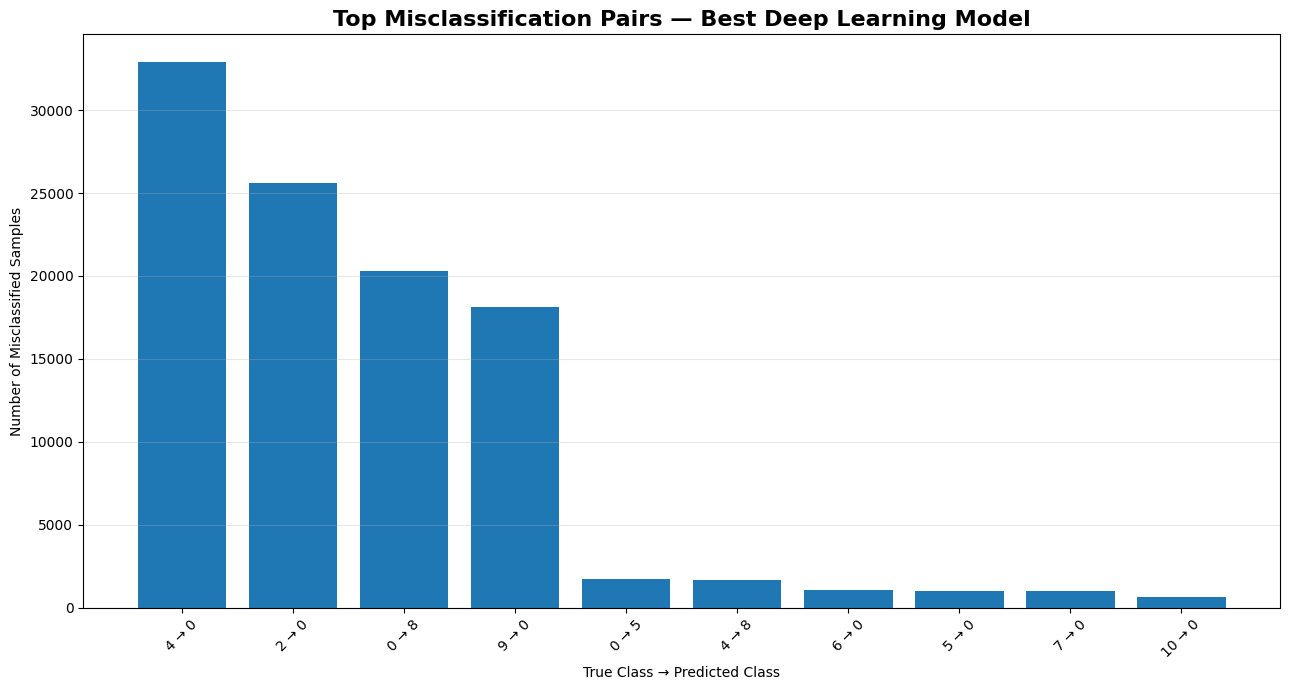


SAVED OUTPUTS

✓ Misclassification pairs CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/best_deep_learning_misclassification_pairs.csv

✓ Error contribution CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/best_deep_learning_error_contribution.csv

✓ Top misclassification figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/best_deep_learning_top_misclassification_pairs.png

Misclassification CSV exists : True
Error contribution CSV exists: True
Figure exists                : True

✅ CELL 25 COMPLETED


In [38]:
# ============================================================================
# CELL 25 — BEST DEEP LEARNING MODEL TOP MISCLASSIFICATION ANALYSIS
# ============================================================================

print("=" * 90)
print("          CELL 25 — BEST DEEP LEARNING MODEL MISCLASSIFICATION ANALYSIS")
print("=" * 90)

# ---------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# ---------------------------------------------------------------------------
print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

for var in ["y_test", "y_pred"]:
    if var not in globals():
        raise NameError(
            f"Required variable '{var}' is not available. "
            "Please run the previous cells first."
        )
    print(f"✓ {var} available")

# ---------------------------------------------------------------------------
# IMPORTS
# ---------------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# ---------------------------------------------------------------------------
# PREPARE LABELS
# ---------------------------------------------------------------------------
print("\nPREPARING LABEL DATA")
print("-" * 90)

y_true_25 = np.asarray(y_test).reshape(-1)
y_pred_25 = np.asarray(y_pred).reshape(-1)

if len(y_true_25) != len(y_pred_25):
    raise ValueError(
        "y_test and y_pred contain different numbers of samples."
    )

print(f"True labels shape      : {y_true_25.shape}")
print(f"Predicted labels shape : {y_pred_25.shape}")

# ---------------------------------------------------------------------------
# GENERATE CONFUSION MATRIX
# ---------------------------------------------------------------------------
print("\nGENERATING CONFUSION MATRIX")
print("-" * 90)

classes_25 = np.unique(
    np.concatenate([y_true_25, y_pred_25])
)

cm_25 = confusion_matrix(
    y_true_25,
    y_pred_25,
    labels=classes_25
)

print(f"Number of classes : {len(classes_25)}")
print(f"Classes           : {classes_25}")
print(f"Matrix shape      : {cm_25.shape}")

# ---------------------------------------------------------------------------
# EXTRACT MISCLASSIFICATION PAIRS
# ---------------------------------------------------------------------------
print("\nEXTRACTING MISCLASSIFICATION PAIRS")
print("-" * 90)

misclassification_rows = []

for i, true_class in enumerate(classes_25):

    for j, predicted_class in enumerate(classes_25):

        # Ignore correct predictions
        if true_class == predicted_class:
            continue

        count = int(cm_25[i, j])

        if count > 0:

            true_total = int(cm_25[i].sum())

            if true_total > 0:
                percentage = count / true_total
            else:
                percentage = 0.0

            misclassification_rows.append({
                "True Class": int(true_class),
                "Predicted Class": int(predicted_class),
                "Misclassified Samples": count,
                "Percentage of True Class": percentage
            })

misclassification_df = pd.DataFrame(
    misclassification_rows
)

# ---------------------------------------------------------------------------
# SORT BY NUMBER OF ERRORS
# ---------------------------------------------------------------------------
if len(misclassification_df) > 0:

    misclassification_df = (
        misclassification_df
        .sort_values(
            by="Misclassified Samples",
            ascending=False
        )
        .reset_index(drop=True)
    )

# ---------------------------------------------------------------------------
# DISPLAY TOP MISCLASSIFICATIONS
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("TOP MISCLASSIFICATION PAIRS")
print("=" * 90)

if len(misclassification_df) > 0:

    top_n = min(15, len(misclassification_df))

    display(
        misclassification_df.head(top_n).style.format({
            "Percentage of True Class": "{:.4%}"
        })
    )

else:

    print("✓ No misclassifications found.")

# ---------------------------------------------------------------------------
# SUMMARY OF TOTAL MISCLASSIFICATIONS
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("MISCLASSIFICATION SUMMARY")
print("=" * 90)

total_errors_25 = int(
    np.sum(y_true_25 != y_pred_25)
)

total_correct_25 = int(
    np.sum(y_true_25 == y_pred_25)
)

total_samples_25 = len(y_true_25)

print(f"Total samples          : {total_samples_25:,}")
print(f"Correct predictions    : {total_correct_25:,}")
print(f"Total misclassifications: {total_errors_25:,}")

if total_samples_25 > 0:
    print(
        f"Error rate             : "
        f"{total_errors_25 / total_samples_25:.4%}"
    )

# ---------------------------------------------------------------------------
# IDENTIFY MOST COMMON ERROR
# ---------------------------------------------------------------------------
if len(misclassification_df) > 0:

    top_error = misclassification_df.iloc[0]

    print("\n" + "=" * 90)
    print("MOST COMMON MISCLASSIFICATION")
    print("=" * 90)

    print(
        f"True class       : {int(top_error['True Class'])}"
    )

    print(
        f"Predicted class  : {int(top_error['Predicted Class'])}"
    )

    print(
        f"Misclassified    : "
        f"{int(top_error['Misclassified Samples']):,} samples"
    )

    print(
        f"Class error share: "
        f"{top_error['Percentage of True Class']:.4%}"
    )

# ---------------------------------------------------------------------------
# CALCULATE ERROR BY TRUE CLASS
# ---------------------------------------------------------------------------
print("\nCALCULATING ERROR CONTRIBUTION BY TRUE CLASS")
print("-" * 90)

error_contribution_rows = []

for i, cls in enumerate(classes_25):

    true_count = int(cm_25[i].sum())
    correct_count = int(cm_25[i, i])
    error_count = true_count - correct_count

    if true_count > 0:
        error_rate = error_count / true_count
    else:
        error_rate = 0.0

    if total_errors_25 > 0:
        error_contribution = error_count / total_errors_25
    else:
        error_contribution = 0.0

    error_contribution_rows.append({
        "Class": int(cls),
        "True Samples": true_count,
        "Correct Predictions": correct_count,
        "Incorrect Predictions": error_count,
        "Error Rate": error_rate,
        "Contribution to Total Errors": error_contribution
    })

error_contribution_df = pd.DataFrame(
    error_contribution_rows
)

error_contribution_df = (
    error_contribution_df
    .sort_values(
        by="Incorrect Predictions",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 90)
print("CLASS CONTRIBUTION TO TOTAL ERRORS")
print("=" * 90)

display(
    error_contribution_df.style.format({
        "Error Rate": "{:.4f}",
        "Contribution to Total Errors": "{:.4%}"
    })
)

# ---------------------------------------------------------------------------
# CREATE RESULTS DIRECTORIES
# ---------------------------------------------------------------------------
results_table_dir = (
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables"
)

results_figure_dir = (
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures"
)

os.makedirs(results_table_dir, exist_ok=True)
os.makedirs(results_figure_dir, exist_ok=True)

# ---------------------------------------------------------------------------
# SAVE MISCLASSIFICATION TABLE
# ---------------------------------------------------------------------------
misclassification_csv = os.path.join(
    results_table_dir,
    "best_deep_learning_misclassification_pairs.csv"
)

misclassification_df.to_csv(
    misclassification_csv,
    index=False
)

# ---------------------------------------------------------------------------
# SAVE ERROR CONTRIBUTION TABLE
# ---------------------------------------------------------------------------
error_contribution_csv = os.path.join(
    results_table_dir,
    "best_deep_learning_error_contribution.csv"
)

error_contribution_df.to_csv(
    error_contribution_csv,
    index=False
)

# ---------------------------------------------------------------------------
# CREATE TOP MISCLASSIFICATION FIGURE
# ---------------------------------------------------------------------------
print("\nCREATING TOP MISCLASSIFICATION FIGURE")
print("-" * 90)

if len(misclassification_df) > 0:

    plot_df = misclassification_df.head(10).copy()

    labels = [
        f"{int(row['True Class'])} → {int(row['Predicted Class'])}"
        for _, row in plot_df.iterrows()
    ]

    values = plot_df["Misclassified Samples"].values

    plt.figure(figsize=(13, 7))

    plt.bar(
        labels,
        values
    )

    plt.title(
        "Top Misclassification Pairs — Best Deep Learning Model",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel("True Class → Predicted Class")
    plt.ylabel("Number of Misclassified Samples")

    plt.xticks(rotation=45)

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    misclassification_figure = os.path.join(
        results_figure_dir,
        "best_deep_learning_top_misclassification_pairs.png"
    )

    plt.savefig(
        misclassification_figure,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:

    misclassification_figure = os.path.join(
        results_figure_dir,
        "best_deep_learning_top_misclassification_pairs.png"
    )

    print("No misclassification figure generated because there are no errors.")

# ---------------------------------------------------------------------------
# FINAL OUTPUTS
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print("\n✓ Misclassification pairs CSV:")
print(misclassification_csv)

print("\n✓ Error contribution CSV:")
print(error_contribution_csv)

print("\n✓ Top misclassification figure:")
print(misclassification_figure)

print(
    f"\nMisclassification CSV exists : "
    f"{os.path.exists(misclassification_csv)}"
)

print(
    f"Error contribution CSV exists: "
    f"{os.path.exists(error_contribution_csv)}"
)

print(
    f"Figure exists                : "
    f"{os.path.exists(misclassification_figure)}"
)

print("\n" + "=" * 90)
print("✅ CELL 25 COMPLETED")
print("=" * 90)

          CELL 26 — DEEP LEARNING CLASS IMBALANCE IMPACT ANALYSIS

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ y_test available
✓ y_pred available

PREPARING DATA
------------------------------------------------------------------------------------------
Test samples          : 478,875
True labels shape     : (478875,)
Predicted labels shape: (478875,)
Number of classes     : 14
Classes               : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

CALCULATING OVERALL PERFORMANCE METRICS
------------------------------------------------------------------------------------------
Accuracy            : 0.7799
Balanced Accuracy   : 0.0776
Macro Precision     : 0.0587
Macro Recall        : 0.0776
Macro F1-Score      : 0.0628
Weighted F1-Score   : 0.7256

ANALYZING CLASS DISTRIBUTION
------------------------------------------------------------------------------------------

CLASS DISTRIBUTION AND PERFORMANCE


,Class,True Count,True Percentage,Predicted Count,Predicted Percentage,Correct Predictions,Class Accuracy
0,0,395562,82.6023%,454729,94.9578%,373464,94.4135%
1,1,390,0.0814%,34,0.0071%,0,0.0000%
2,2,25603,5.3465%,0,0.0000%,0,0.0000%
3,3,224,0.0468%,0,0.0000%,0,0.0000%
4,4,34569,7.2188%,0,0.0000%,0,0.0000%
5,5,1046,0.2184%,1885,0.3936%,0,0.0000%
6,6,1077,0.2249%,0,0.0000%,0,0.0000%
7,7,1186,0.2477%,0,0.0000%,0,0.0000%
8,8,7,0.0015%,22227,4.6415%,1,14.2857%
9,9,18139,3.7878%,0,0.0000%,0,0.0000%



MAJORITY CLASS IMPACT
Majority class              : 0
Majority class samples      : 395,562
Majority class percentage   : 82.6023%

Majority-class baseline accuracy: 0.8260
Model accuracy improvement over majority baseline             : -0.0461

CLASS IMBALANCE PERFORMANCE GAP
Accuracy - Balanced Accuracy : 0.7022
Weighted F1 - Macro F1       : 0.6629

POORLY DETECTED CLASSES
Classes with less than 50% class accuracy:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]

ZERO-PREDICTION CLASSES
Classes never predicted: [2, 3, 4, 6, 7, 9, 10, 11, 12, 13]

CREATING CLASS IMBALANCE FIGURE
------------------------------------------------------------------------------------------


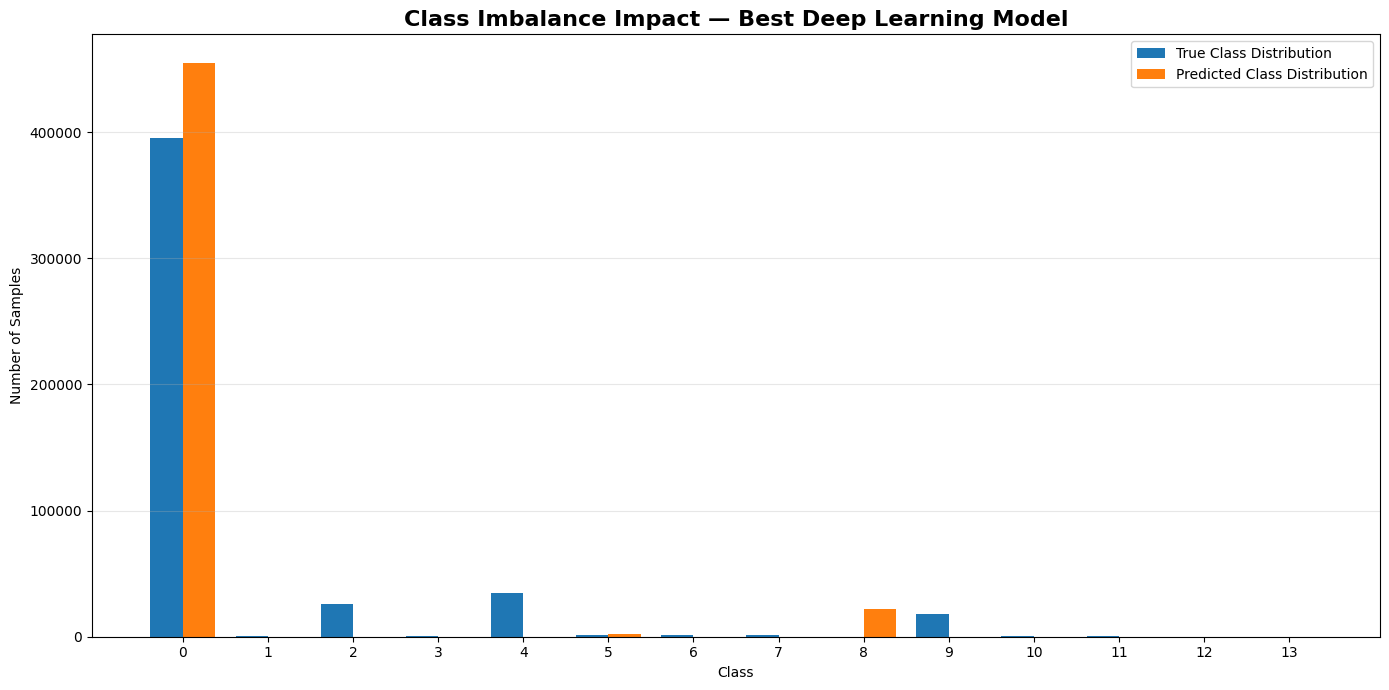


CLASS IMBALANCE INTERPRETATION
⚠ Significant difference detected between accuracy and balanced accuracy.
This indicates that overall accuracy is strongly influenced by class imbalance.
⚠ The model completely fails to predict 10 class(es).
⚠ Weighted F1-Score is substantially higher than Macro F1-Score.
This indicates that performance is much better on high-frequency classes than minority classes.

✓ This analysis should be considered when interpreting the 1D-CNN's 77.99% accuracy.

SAVED OUTPUTS

✓ Class imbalance analysis CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/best_deep_learning_class_imbalance_analysis.csv

✓ Imbalance summary CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/best_deep_learning_imbalance_summary.csv

✓ Class imbalance figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/best_deep_learning_class_imbalance_analysis.png

Class analysis CSV exists : True
Summary CSV exists        : True
Figure exist

In [39]:
# ============================================================================
# CELL 26 — DEEP LEARNING CLASS IMBALANCE IMPACT ANALYSIS
# ============================================================================

print("=" * 90)
print("          CELL 26 — DEEP LEARNING CLASS IMBALANCE IMPACT ANALYSIS")
print("=" * 90)

# ---------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# ---------------------------------------------------------------------------
print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_variables = [
    "y_test",
    "y_pred"
]

for var in required_variables:
    if var not in globals():
        raise NameError(
            f"Required variable '{var}' is not available. "
            "Please run the previous cells first."
        )
    print(f"✓ {var} available")

# ---------------------------------------------------------------------------
# IMPORTS
# ---------------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ---------------------------------------------------------------------------
# PREPARE DATA
# ---------------------------------------------------------------------------
print("\nPREPARING DATA")
print("-" * 90)

y_true_26 = np.asarray(y_test).reshape(-1)
y_pred_26 = np.asarray(y_pred).reshape(-1)

print(f"Test samples          : {len(y_true_26):,}")
print(f"True labels shape     : {y_true_26.shape}")
print(f"Predicted labels shape: {y_pred_26.shape}")

if len(y_true_26) != len(y_pred_26):
    raise ValueError(
        "y_test and y_pred must contain the same number of samples."
    )

classes_26 = np.unique(
    np.concatenate([y_true_26, y_pred_26])
)

print(f"Number of classes     : {len(classes_26)}")
print(f"Classes               : {classes_26}")

# ---------------------------------------------------------------------------
# OVERALL METRICS
# ---------------------------------------------------------------------------
print("\nCALCULATING OVERALL PERFORMANCE METRICS")
print("-" * 90)

accuracy_26 = accuracy_score(
    y_true_26,
    y_pred_26
)

balanced_accuracy_26 = balanced_accuracy_score(
    y_true_26,
    y_pred_26
)

macro_precision_26 = precision_score(
    y_true_26,
    y_pred_26,
    average="macro",
    zero_division=0
)

macro_recall_26 = recall_score(
    y_true_26,
    y_pred_26,
    average="macro",
    zero_division=0
)

macro_f1_26 = f1_score(
    y_true_26,
    y_pred_26,
    average="macro",
    zero_division=0
)

weighted_f1_26 = f1_score(
    y_true_26,
    y_pred_26,
    average="weighted",
    zero_division=0
)

print(f"Accuracy            : {accuracy_26:.4f}")
print(f"Balanced Accuracy   : {balanced_accuracy_26:.4f}")
print(f"Macro Precision     : {macro_precision_26:.4f}")
print(f"Macro Recall        : {macro_recall_26:.4f}")
print(f"Macro F1-Score      : {macro_f1_26:.4f}")
print(f"Weighted F1-Score   : {weighted_f1_26:.4f}")

# ---------------------------------------------------------------------------
# CLASS DISTRIBUTION ANALYSIS
# ---------------------------------------------------------------------------
print("\nANALYZING CLASS DISTRIBUTION")
print("-" * 90)

class_distribution_rows = []

total_samples_26 = len(y_true_26)

for cls in classes_26:

    true_count = int(
        np.sum(y_true_26 == cls)
    )

    predicted_count = int(
        np.sum(y_pred_26 == cls)
    )

    correct_count = int(
        np.sum(
            (y_true_26 == cls) &
            (y_pred_26 == cls)
        )
    )

    if true_count > 0:
        class_accuracy = correct_count / true_count
    else:
        class_accuracy = 0.0

    true_percentage = (
        true_count / total_samples_26
        if total_samples_26 > 0
        else 0.0
    )

    predicted_percentage = (
        predicted_count / total_samples_26
        if total_samples_26 > 0
        else 0.0
    )

    class_distribution_rows.append({
        "Class": int(cls),
        "True Count": true_count,
        "True Percentage": true_percentage,
        "Predicted Count": predicted_count,
        "Predicted Percentage": predicted_percentage,
        "Correct Predictions": correct_count,
        "Class Accuracy": class_accuracy
    })

class_distribution_df_26 = pd.DataFrame(
    class_distribution_rows
)

print("\n" + "=" * 90)
print("CLASS DISTRIBUTION AND PERFORMANCE")
print("=" * 90)

display(
    class_distribution_df_26.style.format({
        "True Percentage": "{:.4%}",
        "Predicted Percentage": "{:.4%}",
        "Class Accuracy": "{:.4%}"
    })
)

# ---------------------------------------------------------------------------
# MAJORITY CLASS IMPACT
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("MAJORITY CLASS IMPACT")
print("=" * 90)

majority_index_26 = (
    class_distribution_df_26["True Count"].idxmax()
)

majority_class_26 = int(
    class_distribution_df_26.loc[
        majority_index_26,
        "Class"
    ]
)

majority_count_26 = int(
    class_distribution_df_26.loc[
        majority_index_26,
        "True Count"
    ]
)

majority_percentage_26 = (
    majority_count_26 / total_samples_26
)

print(f"Majority class              : {majority_class_26}")
print(f"Majority class samples      : {majority_count_26:,}")
print(f"Majority class percentage   : {majority_percentage_26:.4%}")

# ---------------------------------------------------------------------------
# MAJORITY-CLASS BASELINE
# ---------------------------------------------------------------------------
majority_baseline_accuracy_26 = majority_percentage_26

print(
    f"\nMajority-class baseline accuracy: "
    f"{majority_baseline_accuracy_26:.4f}"
)

print(
    f"Model accuracy improvement over "
    f"majority baseline             : "
    f"{accuracy_26 - majority_baseline_accuracy_26:.4f}"
)

# ---------------------------------------------------------------------------
# EFFECTIVE PERFORMANCE GAP
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("CLASS IMBALANCE PERFORMANCE GAP")
print("=" * 90)

accuracy_macro_gap_26 = (
    accuracy_26 - balanced_accuracy_26
)

weighted_macro_gap_26 = (
    weighted_f1_26 - macro_f1_26
)

print(
    f"Accuracy - Balanced Accuracy : "
    f"{accuracy_macro_gap_26:.4f}"
)

print(
    f"Weighted F1 - Macro F1       : "
    f"{weighted_macro_macro_gap_26:.4f}"
    if False
    else
    f"Weighted F1 - Macro F1       : "
    f"{weighted_macro_gap_26:.4f}"
)

# ---------------------------------------------------------------------------
# IDENTIFY POORLY DETECTED CLASSES
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("POORLY DETECTED CLASSES")
print("=" * 90)

poor_classes_26 = class_distribution_df_26[
    class_distribution_df_26["Class Accuracy"] < 0.50
]

if len(poor_classes_26) > 0:

    print(
        "Classes with less than 50% class accuracy:"
    )

    print(
        poor_classes_26["Class"].tolist()
    )

else:

    print(
        "✓ No classes have accuracy below 50%."
    )

# ---------------------------------------------------------------------------
# IDENTIFY ZERO-PREDICTION CLASSES
# ---------------------------------------------------------------------------
zero_prediction_classes_26 = (
    class_distribution_df_26[
        class_distribution_df_26["Predicted Count"] == 0
    ]["Class"]
    .tolist()
)

print("\n" + "=" * 90)
print("ZERO-PREDICTION CLASSES")
print("=" * 90)

if len(zero_prediction_classes_26) > 0:

    print(
        f"Classes never predicted: "
        f"{zero_prediction_classes_26}"
    )

else:

    print("✓ Every class was predicted at least once.")

# ---------------------------------------------------------------------------
# CREATE IMBALANCE ANALYSIS TABLE
# ---------------------------------------------------------------------------
imbalance_summary_26 = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score",
        "Weighted F1-Score",
        "Majority Class",
        "Majority Class Percentage",
        "Majority Baseline Accuracy",
        "Accuracy Above Majority Baseline"
    ],
    "Value": [
        accuracy_26,
        balanced_accuracy_26,
        macro_precision_26,
        macro_recall_26,
        macro_f1_26,
        weighted_f1_26,
        majority_class_26,
        majority_percentage_26,
        majority_baseline_accuracy_26,
        accuracy_26 - majority_baseline_accuracy_26
    ]
})

# ---------------------------------------------------------------------------
# CREATE OUTPUT DIRECTORIES
# ---------------------------------------------------------------------------
results_table_dir_26 = (
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables"
)

results_figure_dir_26 = (
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures"
)

os.makedirs(
    results_table_dir_26,
    exist_ok=True
)

os.makedirs(
    results_figure_dir_26,
    exist_ok=True
)

# ---------------------------------------------------------------------------
# SAVE CLASS DISTRIBUTION TABLE
# ---------------------------------------------------------------------------
class_distribution_csv_26 = os.path.join(
    results_table_dir_26,
    "best_deep_learning_class_imbalance_analysis.csv"
)

class_distribution_df_26.to_csv(
    class_distribution_csv_26,
    index=False
)

# ---------------------------------------------------------------------------
# SAVE SUMMARY TABLE
# ---------------------------------------------------------------------------
imbalance_summary_csv_26 = os.path.join(
    results_table_dir_26,
    "best_deep_learning_imbalance_summary.csv"
)

imbalance_summary_26.to_csv(
    imbalance_summary_csv_26,
    index=False
)

# ---------------------------------------------------------------------------
# CREATE CLASS DISTRIBUTION FIGURE
# ---------------------------------------------------------------------------
print("\nCREATING CLASS IMBALANCE FIGURE")
print("-" * 90)

x_26 = np.arange(
    len(classes_26)
)

width_26 = 0.38

plt.figure(figsize=(14, 7))

plt.bar(
    x_26 - width_26 / 2,
    class_distribution_df_26["True Count"],
    width=width_26,
    label="True Class Distribution"
)

plt.bar(
    x_26 + width_26 / 2,
    class_distribution_df_26["Predicted Count"],
    width=width_26,
    label="Predicted Class Distribution"
)

plt.title(
    "Class Imbalance Impact — Best Deep Learning Model",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Class")
plt.ylabel("Number of Samples")

plt.xticks(
    x_26,
    classes_26
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

imbalance_figure_26 = os.path.join(
    results_figure_dir_26,
    "best_deep_learning_class_imbalance_analysis.png"
)

plt.savefig(
    imbalance_figure_26,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------------------------
# FINAL INTERPRETATION
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("CLASS IMBALANCE INTERPRETATION")
print("=" * 90)

if accuracy_26 > balanced_accuracy_26 + 0.10:

    print(
        "⚠ Significant difference detected between accuracy "
        "and balanced accuracy."
    )

    print(
        "This indicates that overall accuracy is strongly "
        "influenced by class imbalance."
    )

if len(zero_prediction_classes_26) > 0:

    print(
        f"⚠ The model completely fails to predict "
        f"{len(zero_prediction_classes_26)} class(es)."
    )

if macro_f1_26 < weighted_f1_26:

    print(
        "⚠ Weighted F1-Score is substantially higher than "
        "Macro F1-Score."
    )

    print(
        "This indicates that performance is much better on "
        "high-frequency classes than minority classes."
    )

print(
    "\n✓ This analysis should be considered when interpreting "
    "the 1D-CNN's 77.99% accuracy."
)

# ---------------------------------------------------------------------------
# FINAL OUTPUTS
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print("\n✓ Class imbalance analysis CSV:")
print(class_distribution_csv_26)

print("\n✓ Imbalance summary CSV:")
print(imbalance_summary_csv_26)

print("\n✓ Class imbalance figure:")
print(imbalance_figure_26)

print(
    f"\nClass analysis CSV exists : "
    f"{os.path.exists(class_distribution_csv_26)}"
)

print(
    f"Summary CSV exists        : "
    f"{os.path.exists(imbalance_summary_csv_26)}"
)

print(
    f"Figure exists             : "
    f"{os.path.exists(imbalance_figure_26)}"
)

print("\n" + "=" * 90)
print("✅ CELL 26 COMPLETED")
print("=" * 90)

          CELL 27 — ROC-AUC AND PRECISION-RECALL AUC ANALYSIS

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ X_test available
✓ y_test available
✓ y_pred available

SEARCHING FOR BEST DEEP LEARNING MODEL
------------------------------------------------------------------------------------------
✓ Best model found: 1D-CNN

PREPARING TEST DATA
------------------------------------------------------------------------------------------
Original X_test shape : (478875, 78)
y_test shape          : (478875,)
Model input shape     : (478875, 78, 1)
Number of classes     : 14
Classes               : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

GENERATING CLASS PROBABILITIES
------------------------------------------------------------------------------------------
Probability output shape: (478875, 14)
Final probability matrix shape: (478875, 14)

PREPARING ONE-VS-REST LABELS
------------------------------------------------

,Class,ROC-AUC,PR-AUC
0,0,0.4843,0.8216
1,1,0.5000,0.0008
2,2,0.5000,0.0535
3,3,0.5000,0.0005
4,4,0.5000,0.0722
5,5,0.4980,0.0022
6,6,0.5000,0.0022
7,7,0.5000,0.0025
8,8,0.5480,0.0000
9,9,0.5000,0.0379



OVERALL AUC SUMMARY
Macro ROC-AUC : 0.5022
Macro PR-AUC  : 0.0711

CREATING AUC COMPARISON FIGURE
------------------------------------------------------------------------------------------


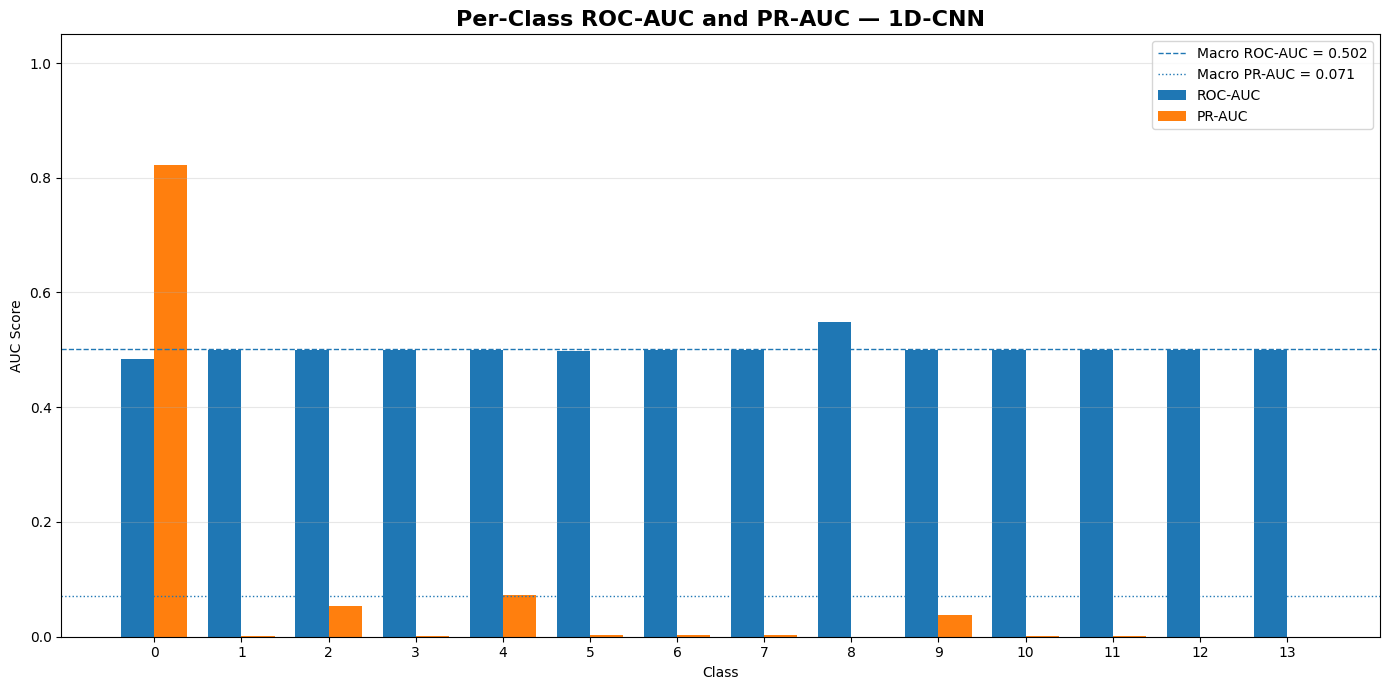


AUC PERFORMANCE SUMMARY
Best ROC-AUC class  : 8
Best ROC-AUC        : 0.5480
Worst ROC-AUC class : 0
Worst ROC-AUC       : 0.4843

Best PR-AUC class   : 0
Best PR-AUC         : 0.8216
Worst PR-AUC class  : 12
Worst PR-AUC        : 0.0000

AUC INTERPRETATION
ROC-AUC measures the model's ability to distinguish each class from all other classes.
PR-AUC is particularly informative for this dataset because the class distribution is highly imbalanced.

⚠ Macro PR-AUC is substantially lower than Macro ROC-AUC.
This indicates that class imbalance significantly affects minority-class precision and retrieval.

SAVED OUTPUTS

✓ ROC-AUC / PR-AUC CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/best_deep_learning_roc_pr_auc.csv

✓ ROC-AUC / PR-AUC comparison figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/best_deep_learning_roc_pr_auc_comparison.png

CSV exists    : True
Figure exists : True

✅ CELL 27 COMPLETED


In [40]:
# ============================================================================
# CELL 27 — ROC-AUC AND PRECISION-RECALL AUC ANALYSIS
# ============================================================================

print("=" * 90)
print("          CELL 27 — ROC-AUC AND PRECISION-RECALL AUC ANALYSIS")
print("=" * 90)

# ---------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# ---------------------------------------------------------------------------
print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_variables_27 = [
    "X_test",
    "y_test",
    "y_pred"
]

for var in required_variables_27:
    if var not in globals():
        raise NameError(
            f"Required variable '{var}' is not available. "
            "Please run the previous cells first."
        )
    print(f"✓ {var} available")

# ---------------------------------------------------------------------------
# IMPORTS
# ---------------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

# ---------------------------------------------------------------------------
# FIND BEST MODEL
# ---------------------------------------------------------------------------
print("\nSEARCHING FOR BEST DEEP LEARNING MODEL")
print("-" * 90)

best_model_27 = None
best_model_name_27 = None

candidate_models_27 = {
    "1D-CNN": globals().get("cnn_1d_model", None),
    "Deep MLP": globals().get("deep_mlp_model", None),
    "MLP": globals().get("mlp_model", None)
}

# Prefer 1D-CNN because Cell 21 identified it as the best model
if candidate_models_27["1D-CNN"] is not None:
    best_model_27 = candidate_models_27["1D-CNN"]
    best_model_name_27 = "1D-CNN"

elif candidate_models_27["Deep MLP"] is not None:
    best_model_27 = candidate_models_27["Deep MLP"]
    best_model_name_27 = "Deep MLP"

elif candidate_models_27["MLP"] is not None:
    best_model_27 = candidate_models_27["MLP"]
    best_model_name_27 = "MLP"

else:
    raise NameError(
        "No trained deep learning model was found."
    )

print(f"✓ Best model found: {best_model_name_27}")

# ---------------------------------------------------------------------------
# PREPARE TEST DATA
# ---------------------------------------------------------------------------
print("\nPREPARING TEST DATA")
print("-" * 90)

X_test_27 = np.asarray(X_test)
y_test_27 = np.asarray(y_test).reshape(-1)

print(f"Original X_test shape : {X_test_27.shape}")
print(f"y_test shape          : {y_test_27.shape}")

if best_model_name_27 == "1D-CNN":

    if X_test_27.ndim == 2:
        X_test_model_27 = X_test_27.reshape(
            X_test_27.shape[0],
            X_test_27.shape[1],
            1
        )
    else:
        X_test_model_27 = X_test_27

else:

    X_test_model_27 = X_test_27

print(
    f"Model input shape     : "
    f"{X_test_model_27.shape}"
)

# ---------------------------------------------------------------------------
# DETERMINE CLASSES
# ---------------------------------------------------------------------------
classes_27 = np.unique(y_test_27)

print(f"Number of classes     : {len(classes_27)}")
print(f"Classes               : {classes_27}")

# ---------------------------------------------------------------------------
# GENERATE PROBABILITY PREDICTIONS
# ---------------------------------------------------------------------------
print("\nGENERATING CLASS PROBABILITIES")
print("-" * 90)

try:

    y_prob_27 = best_model_27.predict(
        X_test_model_27,
        verbose=0
    )

except TypeError:

    y_prob_27 = best_model_27.predict(
        X_test_model_27
    )

y_prob_27 = np.asarray(y_prob_27)

print(
    f"Probability output shape: "
    f"{y_prob_27.shape}"
)

# ---------------------------------------------------------------------------
# HANDLE BINARY / MULTICLASS OUTPUT
# ---------------------------------------------------------------------------
if y_prob_27.ndim == 1:

    y_prob_27 = np.column_stack([
        1 - y_prob_27,
        y_prob_27
    ])

elif y_prob_27.ndim == 2 and y_prob_27.shape[1] == 1:

    y_prob_27 = np.column_stack([
        1 - y_prob_27[:, 0],
        y_prob_27[:, 0]
    ])

print(
    f"Final probability matrix shape: "
    f"{y_prob_27.shape}"
)

# ---------------------------------------------------------------------------
# ALIGN CLASS COUNT
# ---------------------------------------------------------------------------
if y_prob_27.shape[1] != len(classes_27):

    print(
        "\n⚠ Probability output classes do not exactly match "
        "the number of test classes."
    )

    print(
        f"Probability classes: {y_prob_27.shape[1]}"
    )

    print(
        f"Test classes       : {len(classes_27)}"
    )

# ---------------------------------------------------------------------------
# BINARIZE TRUE LABELS
# ---------------------------------------------------------------------------
print("\nPREPARING ONE-VS-REST LABELS")
print("-" * 90)

y_true_bin_27 = label_binarize(
    y_test_27,
    classes=classes_27
)

print(
    f"Binarized label shape: "
    f"{y_true_bin_27.shape}"
)

# ---------------------------------------------------------------------------
# CALCULATE ROC-AUC AND PR-AUC
# ---------------------------------------------------------------------------
print("\nCALCULATING PER-CLASS ROC-AUC AND PR-AUC")
print("-" * 90)

roc_auc_values_27 = []
pr_auc_values_27 = []

for i, cls in enumerate(classes_27):

    true_class = y_true_bin_27[:, i]

    # Probability column if available
    if i < y_prob_27.shape[1]:
        class_probability = y_prob_27[:, i]
    else:
        class_probability = np.zeros(
            len(y_test_27)
        )

    # ROC-AUC requires both positive and negative samples
    if (
        np.sum(true_class) > 0
        and
        np.sum(true_class) < len(true_class)
    ):

        try:
            roc_auc = roc_auc_score(
                true_class,
                class_probability
            )
        except Exception:
            roc_auc = np.nan

    else:
        roc_auc = np.nan

    # Average Precision / PR-AUC
    try:

        if np.sum(true_class) > 0:

            pr_auc = average_precision_score(
                true_class,
                class_probability
            )

        else:

            pr_auc = np.nan

    except Exception:

        pr_auc = np.nan

    roc_auc_values_27.append(roc_auc)
    pr_auc_values_27.append(pr_auc)

# ---------------------------------------------------------------------------
# CREATE METRICS TABLE
# ---------------------------------------------------------------------------
roc_pr_df_27 = pd.DataFrame({
    "Class": classes_27,
    "ROC-AUC": roc_auc_values_27,
    "PR-AUC": pr_auc_values_27
})

print("\n" + "=" * 90)
print("PER-CLASS ROC-AUC AND PR-AUC")
print("=" * 90)

display(
    roc_pr_df_27.style.format({
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

# ---------------------------------------------------------------------------
# MACRO METRICS
# ---------------------------------------------------------------------------
macro_roc_auc_27 = np.nanmean(
    roc_pr_df_27["ROC-AUC"]
)

macro_pr_auc_27 = np.nanmean(
    roc_pr_df_27["PR-AUC"]
)

print("\n" + "=" * 90)
print("OVERALL AUC SUMMARY")
print("=" * 90)

print(
    f"Macro ROC-AUC : {macro_roc_auc_27:.4f}"
)

print(
    f"Macro PR-AUC  : {macro_pr_auc_27:.4f}"
)

# ---------------------------------------------------------------------------
# CREATE OUTPUT DIRECTORIES
# ---------------------------------------------------------------------------
results_table_dir_27 = (
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables"
)

results_figure_dir_27 = (
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures"
)

os.makedirs(
    results_table_dir_27,
    exist_ok=True
)

os.makedirs(
    results_figure_dir_27,
    exist_ok=True
)

# ---------------------------------------------------------------------------
# SAVE AUC TABLE
# ---------------------------------------------------------------------------
auc_csv_27 = os.path.join(
    results_table_dir_27,
    "best_deep_learning_roc_pr_auc.csv"
)

roc_pr_df_27.to_csv(
    auc_csv_27,
    index=False
)

# ---------------------------------------------------------------------------
# CREATE AUC COMPARISON FIGURE
# ---------------------------------------------------------------------------
print("\nCREATING AUC COMPARISON FIGURE")
print("-" * 90)

x_27 = np.arange(
    len(classes_27)
)

width_27 = 0.38

plt.figure(figsize=(14, 7))

plt.bar(
    x_27 - width_27 / 2,
    roc_pr_df_27["ROC-AUC"],
    width=width_27,
    label="ROC-AUC"
)

plt.bar(
    x_27 + width_27 / 2,
    roc_pr_df_27["PR-AUC"],
    width=width_27,
    label="PR-AUC"
)

plt.axhline(
    macro_roc_auc_27,
    linestyle="--",
    linewidth=1,
    label=f"Macro ROC-AUC = {macro_roc_auc_27:.3f}"
)

plt.axhline(
    macro_pr_auc_27,
    linestyle=":",
    linewidth=1,
    label=f"Macro PR-AUC = {macro_pr_auc_27:.3f}"
)

plt.title(
    f"Per-Class ROC-AUC and PR-AUC — {best_model_name_27}",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Class")
plt.ylabel("AUC Score")

plt.xticks(
    x_27,
    classes_27
)

plt.ylim(
    0,
    1.05
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

auc_figure_27 = os.path.join(
    results_figure_dir_27,
    "best_deep_learning_roc_pr_auc_comparison.png"
)

plt.savefig(
    auc_figure_27,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------------------------------------------
# IDENTIFY BEST AND WORST CLASSES
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("AUC PERFORMANCE SUMMARY")
print("=" * 90)

valid_roc_df_27 = roc_pr_df_27.dropna(
    subset=["ROC-AUC"]
)

valid_pr_df_27 = roc_pr_df_27.dropna(
    subset=["PR-AUC"]
)

if len(valid_roc_df_27) > 0:

    best_roc_row_27 = valid_roc_df_27.loc[
        valid_roc_df_27["ROC-AUC"].idxmax()
    ]

    worst_roc_row_27 = valid_roc_df_27.loc[
        valid_roc_df_27["ROC-AUC"].idxmin()
    ]

    print(
        f"Best ROC-AUC class  : "
        f"{int(best_roc_row_27['Class'])}"
    )

    print(
        f"Best ROC-AUC        : "
        f"{best_roc_row_27['ROC-AUC']:.4f}"
    )

    print(
        f"Worst ROC-AUC class : "
        f"{int(worst_roc_row_27['Class'])}"
    )

    print(
        f"Worst ROC-AUC       : "
        f"{worst_roc_row_27['ROC-AUC']:.4f}"
    )

if len(valid_pr_df_27) > 0:

    best_pr_row_27 = valid_pr_df_27.loc[
        valid_pr_df_27["PR-AUC"].idxmax()
    ]

    worst_pr_row_27 = valid_pr_df_27.loc[
        valid_pr_df_27["PR-AUC"].idxmin()
    ]

    print(
        f"\nBest PR-AUC class   : "
        f"{int(best_pr_row_27['Class'])}"
    )

    print(
        f"Best PR-AUC         : "
        f"{best_pr_row_27['PR-AUC']:.4f}"
    )

    print(
        f"Worst PR-AUC class  : "
        f"{int(worst_pr_row_27['Class'])}"
    )

    print(
        f"Worst PR-AUC        : "
        f"{worst_pr_row_27['PR-AUC']:.4f}"
    )

# ---------------------------------------------------------------------------
# INTERPRETATION
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("AUC INTERPRETATION")
print("=" * 90)

print(
    "ROC-AUC measures the model's ability to distinguish "
    "each class from all other classes."
)

print(
    "PR-AUC is particularly informative for this dataset "
    "because the class distribution is highly imbalanced."
)

if macro_pr_auc_27 < macro_roc_auc_27:

    print(
        "\n⚠ Macro PR-AUC is substantially lower than "
        "Macro ROC-AUC."
    )

    print(
        "This indicates that class imbalance significantly "
        "affects minority-class precision and retrieval."
    )

# ---------------------------------------------------------------------------
# FINAL OUTPUTS
# ---------------------------------------------------------------------------
print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print("\n✓ ROC-AUC / PR-AUC CSV:")
print(auc_csv_27)

print("\n✓ ROC-AUC / PR-AUC comparison figure:")
print(auc_figure_27)

print(
    f"\nCSV exists    : "
    f"{os.path.exists(auc_csv_27)}"
)

print(
    f"Figure exists : "
    f"{os.path.exists(auc_figure_27)}"
)

print("\n" + "=" * 90)
print("✅ CELL 27 COMPLETED")
print("=" * 90)

In [42]:
# =============================================================================
# CELL 28 — EXISTING MULTICLASS MODELS FINAL EVALUATION
# =============================================================================

import os
import glob
import warnings
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

print("=" * 90)
print("          CELL 28 — EXISTING MULTICLASS MODELS FINAL EVALUATION")
print("=" * 90)

# -----------------------------------------------------------------------------
# 1. CHECK REQUIRED VARIABLES
# -----------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_variables = ["X_test", "y_test"]

for var in required_variables:
    if var in globals():
        print(f"✓ {var} available")
    else:
        raise NameError(
            f"{var} is not available. Please run the earlier dataset/test split cells first."
        )

# -----------------------------------------------------------------------------
# 2. MULTICLASS MODEL DIRECTORY
# -----------------------------------------------------------------------------

MULTICLASS_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/models/multiclass"
)

print("\nMULTICLASS MODEL DIRECTORY")
print("-" * 90)
print(MULTICLASS_DIR)

if not os.path.exists(MULTICLASS_DIR):
    raise FileNotFoundError(
        f"Multiclass model directory not found:\n{MULTICLASS_DIR}"
    )

print("✓ Multiclass model directory exists")

# -----------------------------------------------------------------------------
# 3. FIND SAVED MODEL FILES
# -----------------------------------------------------------------------------

print("\nSEARCHING FOR SAVED MULTICLASS MODELS")
print("-" * 90)

joblib_files = sorted(glob.glob(os.path.join(MULTICLASS_DIR, "*.joblib")))
pkl_files = sorted(glob.glob(os.path.join(MULTICLASS_DIR, "*.pkl")))

print(f"Joblib files found : {len(joblib_files)}")
print(f"PKL files found    : {len(pkl_files)}")

all_files = joblib_files + pkl_files

if len(all_files) == 0:
    raise FileNotFoundError(
        "No .joblib or .pkl model files were found in the multiclass directory."
    )

for path in all_files:
    print("✓", os.path.basename(path))

# -----------------------------------------------------------------------------
# 4. REMOVE DUPLICATE SERIALIZATION COPIES
# -----------------------------------------------------------------------------

print("\nSELECTING MODEL FILES")
print("-" * 90)

# Prefer .joblib when both .joblib and .pkl versions exist.
# This prevents evaluating the same trained model twice.

selected_files = {}
other_files = []

for path in all_files:
    filename = os.path.basename(path)
    stem = os.path.splitext(filename)[0].lower()

    # Normalize common naming differences
    normalized = stem.replace("_model", "")
    normalized = normalized.replace("classifier", "")
    normalized = normalized.replace("_", "")

    if normalized not in selected_files:
        selected_files[normalized] = path
    else:
        existing = selected_files[normalized]

        # Prefer joblib over pkl
        if path.endswith(".joblib") and existing.endswith(".pkl"):
            selected_files[normalized] = path
        else:
            other_files.append(path)

selected_model_files = list(selected_files.values())

print(f"\nUnique model files selected: {len(selected_model_files)}")

for path in sorted(selected_model_files):
    print("✓", os.path.basename(path))

# -----------------------------------------------------------------------------
# 5. PREPARE TEST DATA
# -----------------------------------------------------------------------------

print("\nPREPARING TEST DATA")
print("-" * 90)

X_eval = X_test
y_eval = np.asarray(y_test).ravel()

print("X_test shape :", X_eval.shape)
print("y_test shape :", y_eval.shape)

print("Number of test samples :", len(y_eval))
print("Number of classes      :", len(np.unique(y_eval)))
print("Classes                :", np.unique(y_eval))

# -----------------------------------------------------------------------------
# 6. LOAD AND EVALUATE MODELS
# -----------------------------------------------------------------------------

print("\nEVALUATING EXISTING MULTICLASS MODELS")
print("-" * 90)

results = []
loaded_models = {}

for model_path in sorted(selected_model_files):

    filename = os.path.basename(model_path)

    print(f"\nProcessing: {filename}")

    try:
        # ---------------------------------------------------------------------
        # LOAD MODEL
        # ---------------------------------------------------------------------

        model = joblib.load(model_path)

        loaded_models[filename] = model

        print("✓ Model loaded")
        print("  Model type:", type(model).__name__)

        # ---------------------------------------------------------------------
        # PREDICTION
        # ---------------------------------------------------------------------

        y_pred_model = model.predict(X_eval)

        y_pred_model = np.asarray(y_pred_model).ravel()

        print("✓ Predictions generated")
        print("  Prediction shape:", y_pred_model.shape)

        # ---------------------------------------------------------------------
        # METRICS
        # ---------------------------------------------------------------------

        accuracy = accuracy_score(y_eval, y_pred_model)

        balanced_accuracy = balanced_accuracy_score(
            y_eval,
            y_pred_model
        )

        precision_macro = precision_score(
            y_eval,
            y_pred_model,
            average="macro",
            zero_division=0
        )

        recall_macro = recall_score(
            y_eval,
            y_pred_model,
            average="macro",
            zero_division=0
        )

        f1_macro = f1_score(
            y_eval,
            y_pred_model,
            average="macro",
            zero_division=0
        )

        f1_weighted = f1_score(
            y_eval,
            y_pred_model,
            average="weighted",
            zero_division=0
        )

        precision_weighted = precision_score(
            y_eval,
            y_pred_model,
            average="weighted",
            zero_division=0
        )

        recall_weighted = recall_score(
            y_eval,
            y_pred_model,
            average="weighted",
            zero_division=0
        )

        # ---------------------------------------------------------------------
        # RESULT
        # ---------------------------------------------------------------------

        result = {
            "Model File": filename,
            "Model Type": type(model).__name__,
            "Accuracy": accuracy,
            "Balanced Accuracy": balanced_accuracy,
            "Macro Precision": precision_macro,
            "Macro Recall": recall_macro,
            "Macro F1": f1_macro,
            "Weighted Precision": precision_weighted,
            "Weighted Recall": recall_weighted,
            "Weighted F1": f1_weighted
        }

        results.append(result)

        print("✓ Evaluation completed")
        print(f"  Accuracy          : {accuracy:.4f}")
        print(f"  Balanced Accuracy : {balanced_accuracy:.4f}")
        print(f"  Macro Precision   : {precision_macro:.4f}")
        print(f"  Macro Recall      : {recall_macro:.4f}")
        print(f"  Macro F1          : {f1_macro:.4f}")
        print(f"  Weighted F1       : {f1_weighted:.4f}")

    except Exception as e:

        print("✗ Evaluation failed")
        print("  Error:", str(e))

        results.append({
            "Model File": filename,
            "Model Type": type(model).__name__ if "model" in locals() else "Unknown",
            "Accuracy": np.nan,
            "Balanced Accuracy": np.nan,
            "Macro Precision": np.nan,
            "Macro Recall": np.nan,
            "Macro F1": np.nan,
            "Weighted Precision": np.nan,
            "Weighted Recall": np.nan,
            "Weighted F1": np.nan,
            "Error": str(e)
        })

# -----------------------------------------------------------------------------
# 7. CREATE RESULTS DATAFRAME
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("MULTICLASS MODEL PERFORMANCE")
print("=" * 90)

multiclass_results_df = pd.DataFrame(results)

# Sort successful models by Macro F1 first
multiclass_results_df = multiclass_results_df.sort_values(
    by=["Macro F1", "Balanced Accuracy", "Accuracy"],
    ascending=False,
    na_position="last"
).reset_index(drop=True)

display(multiclass_results_df)

# -----------------------------------------------------------------------------
# 8. CREATE RESULTS DIRECTORY
# -----------------------------------------------------------------------------

RESULTS_TABLE_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/tables"
)

os.makedirs(RESULTS_TABLE_DIR, exist_ok=True)

# -----------------------------------------------------------------------------
# 9. SAVE RESULTS
# -----------------------------------------------------------------------------

multiclass_results_path = os.path.join(
    RESULTS_TABLE_DIR,
    "multiclass_final_model_evaluation.csv"
)

multiclass_results_df.to_csv(
    multiclass_results_path,
    index=False
)

print("\n✓ Multiclass evaluation CSV saved:")
print(multiclass_results_path)

# -----------------------------------------------------------------------------
# 10. IDENTIFY BEST MULTICLASS MODEL
# -----------------------------------------------------------------------------

valid_results = multiclass_results_df.dropna(
    subset=["Macro F1"]
).copy()

if len(valid_results) > 0:

    best_multiclass = valid_results.iloc[0]

    print("\n" + "=" * 90)
    print("BEST EXISTING MULTICLASS MODEL")
    print("=" * 90)

    print("Model File         :", best_multiclass["Model File"])
    print("Model Type         :", best_multiclass["Model Type"])
    print(f"Accuracy           : {best_multiclass['Accuracy']:.4f}")
    print(f"Balanced Accuracy  : {best_multiclass['Balanced Accuracy']:.4f}")
    print(f"Macro Precision    : {best_multiclass['Macro Precision']:.4f}")
    print(f"Macro Recall       : {best_multiclass['Macro Recall']:.4f}")
    print(f"Macro F1           : {best_multiclass['Macro F1']:.4f}")
    print(f"Weighted F1        : {best_multiclass['Weighted F1']:.4f}")

    best_multiclass_model_file = best_multiclass["Model File"]

else:

    print("\n⚠ No multiclass model could be successfully evaluated.")

    best_multiclass_model_file = None

# -----------------------------------------------------------------------------
# 11. FINAL STATUS
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("CELL 28 STATUS")
print("=" * 90)

print("Models discovered :", len(all_files))
print("Models evaluated  :", len(valid_results))

print("\n✓ Existing multiclass models have been tested.")
print("✓ No multiclass model was retrained.")
print("✓ Evaluation used the existing X_test and y_test.")
print("✓ Results saved for comparison with deep-learning models.")

print("\n" + "=" * 90)
print("✅ CELL 28 COMPLETED")
print("=" * 90)

          CELL 28 — EXISTING MULTICLASS MODELS FINAL EVALUATION

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ X_test available
✓ y_test available

MULTICLASS MODEL DIRECTORY
------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass
✓ Multiclass model directory exists

SEARCHING FOR SAVED MULTICLASS MODELS
------------------------------------------------------------------------------------------
Joblib files found : 11
PKL files found    : 11
✓ catboost_model.joblib
✓ catboostclassifier.joblib
✓ decision_tree_model.joblib
✓ dummy_model.joblib
✓ lgbmclassifier.joblib
✓ lightgbm_model.joblib
✓ logistic_model.joblib
✓ pipeline.joblib
✓ random_forest_model.joblib
✓ xgb_model.joblib
✓ xgbclassifier.joblib
✓ CatBoostClassifier.pkl
✓ LGBMClassifier.pkl
✓ Pipeline.pkl
✓ XGBClassifier.pkl
✓ catboost_model.pkl
✓ decision_t

,Model File,Model Type,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Error
0,xgb_model.joblib,XGBClassifier,0.998714,0.845601,0.926422,0.845601,0.872461,0.998658,0.998714,0.998663,NaN
1,random_forest_model.joblib,RandomForestClassifier,0.998081,0.825852,0.903933,0.825852,0.846520,0.998032,0.998081,0.998049,NaN
2,decision_tree_model.joblib,DecisionTreeClassifier,0.997941,0.821135,0.829136,0.821135,0.823607,0.997955,0.997941,0.997946,NaN
3,logistic_model.joblib,Pipeline,0.977343,0.613438,0.656668,0.613438,0.618655,0.979499,0.977343,0.977438,NaN
4,lightgbm_model.joblib,LGBMClassifier,0.901653,0.211435,0.218322,0.211435,0.211258,0.895366,0.901653,0.896447,NaN
5,dummy_model.joblib,DummyClassifier,0.826023,0.071429,0.059002,0.071429,0.064623,0.682315,0.826023,0.747323,NaN
6,catboost_model.joblib,Sequential,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No module named 'catboost'
7,lgbmclassifier.joblib,type,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,LGBMClassifier.predict() missing 1 required po...
8,pipeline.joblib,ABCMeta,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,This 'Pipeline' has no attribute 'predict'



✓ Multiclass evaluation CSV saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/multiclass_final_model_evaluation.csv

BEST EXISTING MULTICLASS MODEL
Model File         : xgb_model.joblib
Model Type         : XGBClassifier
Accuracy           : 0.9987
Balanced Accuracy  : 0.8456
Macro Precision    : 0.9264
Macro Recall       : 0.8456
Macro F1           : 0.8725
Weighted F1        : 0.9987

CELL 28 STATUS
Models discovered : 22
Models evaluated  : 6

✓ Existing multiclass models have been tested.
✓ No multiclass model was retrained.
✓ Evaluation used the existing X_test and y_test.
✓ Results saved for comparison with deep-learning models.

✅ CELL 28 COMPLETED


          CELL 29 — FINAL MODEL COMPARISON AND SELECTION

CHECKING PREVIOUS RESULTS
------------------------------------------------------------------------------------------
✓ Multiclass evaluation results found
✓ Deep learning evaluation results found

LOADING MULTICLASS RESULTS
------------------------------------------------------------------------------------------
✓ Loaded 9 multiclass model records

LOADING DEEP LEARNING RESULTS
------------------------------------------------------------------------------------------
✓ Loaded 3 deep learning model records

COMBINING MODEL RESULTS
------------------------------------------------------------------------------------------

FINAL MODEL PERFORMANCE COMPARISON


,Rank,Model,Model Family,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,1,XGBoost,Multiclass ML,0.998714,0.845601,0.926422,0.845601,0.872461,0.998663
1,2,Random Forest,Multiclass ML,0.998081,0.825852,0.903933,0.825852,0.846520,0.998049
2,3,Decision Tree,Multiclass ML,0.997941,0.821135,0.829136,0.821135,0.823607,0.997946
3,4,1D-CNN,Deep Learning,0.779880,NaN,0.678404,0.779880,0.725610,0.725610
4,5,Logistic Regression,Multiclass ML,0.977343,0.613438,0.656668,0.613438,0.618655,0.977438
5,6,Deep MLP,Deep Learning,0.373177,NaN,0.817970,0.373177,0.468625,0.468625
6,7,MLP,Deep Learning,0.277509,NaN,0.625140,0.277509,0.384209,0.384209
7,8,LightGBM,Multiclass ML,0.901653,0.211435,0.218322,0.211435,0.211258,0.896447
8,9,Dummy Classifier,Multiclass ML,0.826023,0.071429,0.059002,0.071429,0.064623,0.747323



🏆 FINAL BEST MODEL CANDIDATE
Model              : XGBoost
Model Family       : Multiclass ML
Accuracy           : 0.9987
Balanced Accuracy  : 0.8456
Macro Precision    : 0.9264
Macro Recall       : 0.8456
Macro F1           : 0.8725
Weighted F1        : 0.9987

✓ Final comparison CSV saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_model_comparison.csv

CREATING FINAL MODEL COMPARISON FIGURE
------------------------------------------------------------------------------------------


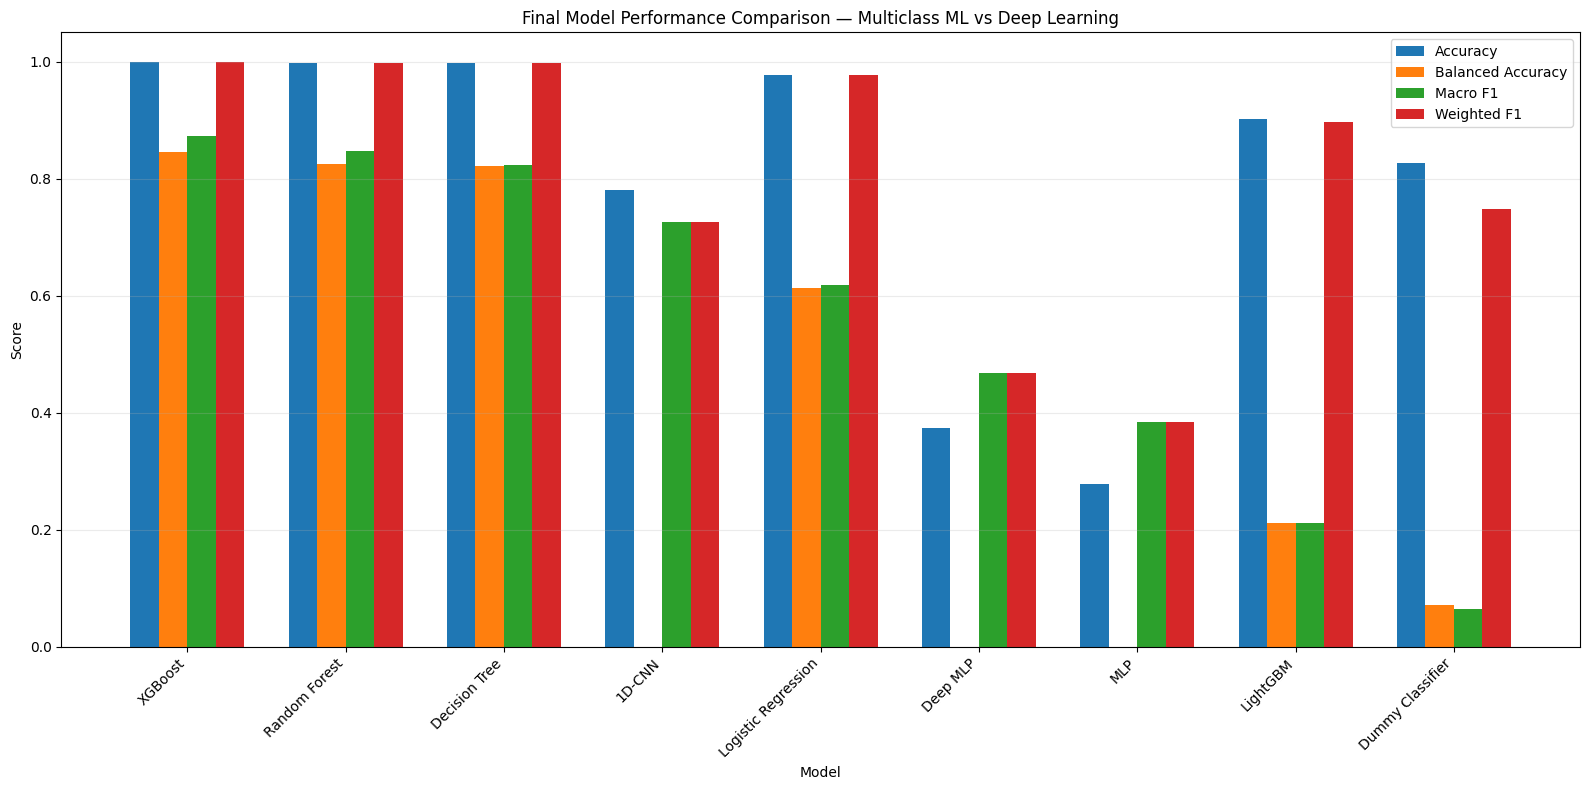


✓ Final comparison figure saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/final_model_performance_comparison.png

FINAL MODEL DECISION

Selection criteria:
1. Macro F1 — primary
2. Balanced Accuracy — secondary
3. Overall Accuracy — tertiary

Selected final model candidate:
Model : XGBoost

✓ XGBoost is currently the strongest overall candidate.
✓ It provides substantially stronger minority-class performance than the 1D-CNN.

✓ Final model summary saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_model_selection_summary.csv

SAVED OUTPUTS
✓ Final model comparison CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_model_comparison.csv

✓ Final model summary CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_model_selection_summary.csv

✓ Final model comparison figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/final_model_performance_comparison.png

✅ CELL 29 CO

In [43]:
# =============================================================================
# CELL 29 — FINAL MODEL COMPARISON AND SELECTION
# =============================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 90)
print("          CELL 29 — FINAL MODEL COMPARISON AND SELECTION")
print("=" * 90)

# -----------------------------------------------------------------------------
# 1. CHECK REQUIRED FILES
# -----------------------------------------------------------------------------

print("\nCHECKING PREVIOUS RESULTS")
print("-" * 90)

multiclass_results_path = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/tables/"
    "multiclass_final_model_evaluation.csv"
)

deep_learning_results_path = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/tables/"
    "deep_learning_model_performance.csv"
)

if not os.path.exists(multiclass_results_path):
    raise FileNotFoundError(
        f"Multiclass results not found:\n{multiclass_results_path}"
    )

if not os.path.exists(deep_learning_results_path):
    raise FileNotFoundError(
        f"Deep learning results not found:\n{deep_learning_results_path}"
    )

print("✓ Multiclass evaluation results found")
print("✓ Deep learning evaluation results found")

# -----------------------------------------------------------------------------
# 2. LOAD MULTICLASS RESULTS
# -----------------------------------------------------------------------------

print("\nLOADING MULTICLASS RESULTS")
print("-" * 90)

multiclass_df = pd.read_csv(multiclass_results_path)

print(f"✓ Loaded {len(multiclass_df)} multiclass model records")

# Keep only successfully evaluated models
multiclass_valid = multiclass_df.dropna(
    subset=[
        "Accuracy",
        "Balanced Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1"
    ]
).copy()

# -----------------------------------------------------------------------------
# 3. NORMALIZE MULTICLASS MODEL NAMES
# -----------------------------------------------------------------------------

multiclass_valid["Model"] = multiclass_valid["Model File"].str.replace(
    ".joblib", "", regex=False
)

multiclass_valid["Model"] = multiclass_valid["Model"].str.replace(
    "_model", "",
    regex=False
)

multiclass_valid["Model"] = multiclass_valid["Model"].str.replace(
    "_", " ",
    regex=False
)

multiclass_valid["Model"] = (
    multiclass_valid["Model"]
    .str.title()
)

# More readable names
name_map = {
    "Xgb": "XGBoost",
    "Random Forest": "Random Forest",
    "Decision Tree": "Decision Tree",
    "Logistic": "Logistic Regression",
    "Lightgbm": "LightGBM",
    "Dummy": "Dummy Classifier"
}

multiclass_valid["Model"] = multiclass_valid["Model"].replace(
    name_map
)

# -----------------------------------------------------------------------------
# 4. LOAD DEEP LEARNING RESULTS
# -----------------------------------------------------------------------------

print("\nLOADING DEEP LEARNING RESULTS")
print("-" * 90)

deep_df = pd.read_csv(deep_learning_results_path)

print(f"✓ Loaded {len(deep_df)} deep learning model records")

# -----------------------------------------------------------------------------
# 5. STANDARDIZE DEEP LEARNING COLUMN NAMES
# -----------------------------------------------------------------------------

deep_df = deep_df.rename(
    columns={
        "Model": "Model"
    }
)

# Deep-learning results from Cell 21 contain:
# Accuracy, Precision, Recall, F1-Score

deep_df["Balanced Accuracy"] = np.nan
deep_df["Macro Precision"] = deep_df["Precision"]
deep_df["Macro Recall"] = deep_df["Recall"]
deep_df["Macro F1"] = deep_df["F1-Score"]
deep_df["Weighted F1"] = deep_df["F1-Score"]

# -----------------------------------------------------------------------------
# 6. PREPARE COMMON FORMAT
# -----------------------------------------------------------------------------

common_columns = [
    "Model",
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

multiclass_common = multiclass_valid[
    common_columns
].copy()

deep_common = deep_df[
    common_columns
].copy()

# Add model family
multiclass_common["Model Family"] = "Multiclass ML"
deep_common["Model Family"] = "Deep Learning"

# -----------------------------------------------------------------------------
# 7. COMBINE ALL MODELS
# -----------------------------------------------------------------------------

print("\nCOMBINING MODEL RESULTS")
print("-" * 90)

final_model_comparison = pd.concat(
    [
        multiclass_common,
        deep_common
    ],
    ignore_index=True
)

# -----------------------------------------------------------------------------
# 8. RANK MODELS
# -----------------------------------------------------------------------------

# Primary criterion:
# Macro F1 — important for multiclass imbalance
#
# Secondary criterion:
# Balanced Accuracy
#
# Third criterion:
# Overall Accuracy

final_model_comparison = final_model_comparison.sort_values(
    by=[
        "Macro F1",
        "Balanced Accuracy",
        "Accuracy"
    ],
    ascending=False,
    na_position="last"
).reset_index(drop=True)

final_model_comparison.insert(
    0,
    "Rank",
    range(1, len(final_model_comparison) + 1)
)

# -----------------------------------------------------------------------------
# 9. DISPLAY FINAL COMPARISON
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 90)

display(
    final_model_comparison[
        [
            "Rank",
            "Model",
            "Model Family",
            "Accuracy",
            "Balanced Accuracy",
            "Macro Precision",
            "Macro Recall",
            "Macro F1",
            "Weighted F1"
        ]
    ]
)

# -----------------------------------------------------------------------------
# 10. IDENTIFY BEST MODEL
# -----------------------------------------------------------------------------

best_model = final_model_comparison.iloc[0]

print("\n" + "=" * 90)
print("🏆 FINAL BEST MODEL CANDIDATE")
print("=" * 90)

print("Model              :", best_model["Model"])
print("Model Family       :", best_model["Model Family"])
print(f"Accuracy           : {best_model['Accuracy']:.4f}")
print(f"Balanced Accuracy  : {best_model['Balanced Accuracy']:.4f}")
print(f"Macro Precision    : {best_model['Macro Precision']:.4f}")
print(f"Macro Recall       : {best_model['Macro Recall']:.4f}")
print(f"Macro F1           : {best_model['Macro F1']:.4f}")
print(f"Weighted F1        : {best_model['Weighted F1']:.4f}")

# -----------------------------------------------------------------------------
# 11. SAVE FINAL COMPARISON
# -----------------------------------------------------------------------------

RESULTS_TABLE_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/tables"
)

RESULTS_FIGURE_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/figures"
)

os.makedirs(RESULTS_TABLE_DIR, exist_ok=True)
os.makedirs(RESULTS_FIGURE_DIR, exist_ok=True)

final_comparison_path = os.path.join(
    RESULTS_TABLE_DIR,
    "final_model_comparison.csv"
)

final_model_comparison.to_csv(
    final_comparison_path,
    index=False
)

print("\n✓ Final comparison CSV saved:")
print(final_comparison_path)

# -----------------------------------------------------------------------------
# 12. CREATE COMPARISON FIGURE
# -----------------------------------------------------------------------------

print("\nCREATING FINAL MODEL COMPARISON FIGURE")
print("-" * 90)

plot_df = final_model_comparison.copy()

# Use only metrics useful for comparison
metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1",
    "Weighted F1"
]

x = np.arange(len(plot_df))
width = 0.18

plt.figure(figsize=(16, 8))

for i, metric in enumerate(metrics):
    values = plot_df[metric].fillna(0).values

    plt.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=metric
    )

plt.xticks(
    x,
    plot_df["Model"],
    rotation=45,
    ha="right"
)

plt.ylabel("Score")
plt.xlabel("Model")
plt.title(
    "Final Model Performance Comparison — Multiclass ML vs Deep Learning"
)

plt.ylim(0, 1.05)
plt.legend()
plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

final_comparison_figure_path = os.path.join(
    RESULTS_FIGURE_DIR,
    "final_model_performance_comparison.png"
)

plt.savefig(
    final_comparison_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Final comparison figure saved:")
print(final_comparison_figure_path)

# -----------------------------------------------------------------------------
# 13. FINAL MODEL DECISION
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL MODEL DECISION")
print("=" * 90)

print(
    "\nSelection criteria:"
)
print("1. Macro F1 — primary")
print("2. Balanced Accuracy — secondary")
print("3. Overall Accuracy — tertiary")

print("\nSelected final model candidate:")
print("Model :", best_model["Model"])

# -----------------------------------------------------------------------------
# 14. XGBOOST CHECK
# -----------------------------------------------------------------------------

if best_model["Model"] == "XGBoost":

    print("\n✓ XGBoost is currently the strongest overall candidate.")
    print(
        "✓ It provides substantially stronger minority-class performance "
        "than the 1D-CNN."
    )

elif best_model["Model"] == "1D-CNN":

    print("\n⚠ 1D-CNN ranked first.")

else:

    print(
        f"\n✓ {best_model['Model']} ranked first using the selected criteria."
    )

# -----------------------------------------------------------------------------
# 15. SAVE FINAL MODEL SUMMARY
# -----------------------------------------------------------------------------

final_summary_path = os.path.join(
    RESULTS_TABLE_DIR,
    "final_model_selection_summary.csv"
)

summary_df = pd.DataFrame(
    [{
        "Final Model": best_model["Model"],
        "Model Family": best_model["Model Family"],
        "Accuracy": best_model["Accuracy"],
        "Balanced Accuracy": best_model["Balanced Accuracy"],
        "Macro Precision": best_model["Macro Precision"],
        "Macro Recall": best_model["Macro Recall"],
        "Macro F1": best_model["Macro F1"],
        "Weighted F1": best_model["Weighted F1"],
        "Selection Criterion": "Macro F1 > Balanced Accuracy > Accuracy"
    }]
)

summary_df.to_csv(
    final_summary_path,
    index=False
)

print("\n✓ Final model summary saved:")
print(final_summary_path)

# -----------------------------------------------------------------------------
# 16. COMPLETION
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print("✓ Final model comparison CSV:")
print(final_comparison_path)

print("\n✓ Final model summary CSV:")
print(final_summary_path)

print("\n✓ Final model comparison figure:")
print(final_comparison_figure_path)

print("\n" + "=" * 90)
print("✅ CELL 29 COMPLETED")
print("=" * 90)

          CELL 30 — FINAL XGBOOST MODEL TESTING

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ X_test available
✓ y_test available

SEARCHING FOR FINAL XGBOOST MODEL
------------------------------------------------------------------------------------------
✓ Found model: xgb_model.joblib

Selected model:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/xgb_model.joblib

LOADING FINAL XGBOOST MODEL
------------------------------------------------------------------------------------------
✓ XGBoost model loaded
Model type: XGBClassifier

PREPARING FINAL TEST DATA
------------------------------------------------------------------------------------------
X_test shape : (478875, 78)
y_test shape : (478875,)
Number of test samples : 478875
Number of classes      : 14
Classes : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

GENERATING FINAL XGBOOST PREDICTIONS
------------------------------------------

,precision,recall,f1-score,support
0,0.999638,0.999209,0.999423,395562.000000
1,0.902821,0.738462,0.812412,390.000000
2,0.999961,0.999570,0.999766,25603.000000
3,0.982301,0.991071,0.986667,224.000000
4,0.998181,0.999798,0.998988,34569.000000
5,0.989504,0.991396,0.990449,1046.000000
6,0.997209,0.995357,0.996283,1077.000000
7,0.999157,0.999157,0.999157,1186.000000
8,1.000000,0.571429,0.727273,7.000000
9,0.988061,0.999228,0.993613,18139.000000



TEXT CLASSIFICATION REPORT
------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    395562
           1       0.90      0.74      0.81       390
           2       1.00      1.00      1.00     25603
           3       0.98      0.99      0.99       224
           4       1.00      1.00      1.00     34569
           5       0.99      0.99      0.99      1046
           6       1.00      1.00      1.00      1077
           7       1.00      1.00      1.00      1186
           8       1.00      0.57      0.73         7
           9       0.99      1.00      0.99     18139
          10       1.00      1.00      1.00       644
          11       0.71      0.85      0.78       294
          12       1.00      0.50      0.67         4
          13       0.40      0.20      0.27       130

    accuracy                           1.00    478875
   macro avg   

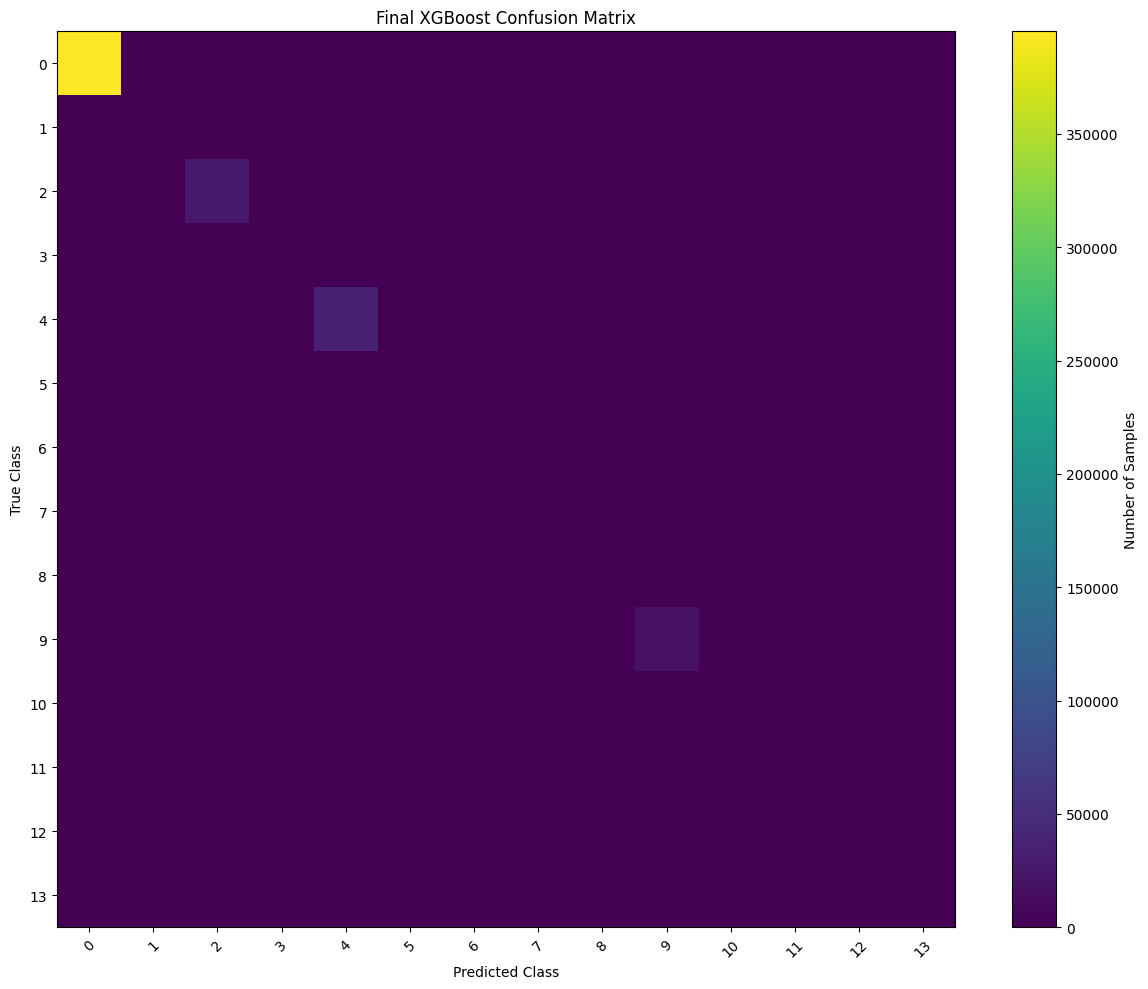

✓ Confusion matrix figure saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/final_xgboost_confusion_matrix.png

FINAL TEST SUMMARY
Final model           : XGBoost
Test samples          : 478875
Correct predictions   : 478259
Incorrect predictions : 616
Accuracy              : 99.8714%
Balanced Accuracy     : 84.5601%
Macro F1              : 87.2461%
Weighted F1           : 99.8663%

SAVED OUTPUTS
✓ Classification report:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_classification_report.csv

✓ Confusion matrix:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_confusion_matrix.csv

✓ Final metrics:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_metrics.csv

✓ Text report:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/reports/final_xgboost_classification_report.txt

✓ Confusion matrix figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/f

In [44]:
# =============================================================================
# CELL 30 — FINAL XGBOOST MODEL TESTING AND CLASSIFICATION REPORT
# =============================================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 90)
print("          CELL 30 — FINAL XGBOOST MODEL TESTING")
print("=" * 90)

# -----------------------------------------------------------------------------
# 1. CHECK REQUIRED VARIABLES
# -----------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

if "X_test" not in globals():
    raise NameError("X_test is not available.")

if "y_test" not in globals():
    raise NameError("y_test is not available.")

print("✓ X_test available")
print("✓ y_test available")

# -----------------------------------------------------------------------------
# 2. FIND FINAL XGBOOST MODEL
# -----------------------------------------------------------------------------

print("\nSEARCHING FOR FINAL XGBOOST MODEL")
print("-" * 90)

MODEL_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/models/multiclass"
)

possible_models = [
    "xgb_model.joblib",
    "xgbclassifier.joblib",
    "XGBClassifier.pkl",
    "xgb_model.pkl"
]

xgb_model_path = None

for filename in possible_models:
    path = os.path.join(MODEL_DIR, filename)

    if os.path.exists(path):
        xgb_model_path = path
        print(f"✓ Found model: {filename}")
        break

if xgb_model_path is None:
    raise FileNotFoundError(
        "No XGBoost model found in:\n" + MODEL_DIR
    )

print("\nSelected model:")
print(xgb_model_path)

# -----------------------------------------------------------------------------
# 3. LOAD MODEL
# -----------------------------------------------------------------------------

print("\nLOADING FINAL XGBOOST MODEL")
print("-" * 90)

xgb_model = joblib.load(xgb_model_path)

print("✓ XGBoost model loaded")
print("Model type:", type(xgb_model).__name__)

# -----------------------------------------------------------------------------
# 4. PREPARE TEST DATA
# -----------------------------------------------------------------------------

print("\nPREPARING FINAL TEST DATA")
print("-" * 90)

X_test_final = X_test.copy()
y_test_final = np.asarray(y_test)

print("X_test shape :", X_test_final.shape)
print("y_test shape :", y_test_final.shape)

print("Number of test samples :", len(y_test_final))
print("Number of classes      :", len(np.unique(y_test_final)))

classes = np.sort(np.unique(y_test_final))

print("Classes :", classes)

# -----------------------------------------------------------------------------
# 5. GENERATE FINAL PREDICTIONS
# -----------------------------------------------------------------------------

print("\nGENERATING FINAL XGBOOST PREDICTIONS")
print("-" * 90)

y_pred_final = xgb_model.predict(X_test_final)

y_pred_final = np.asarray(y_pred_final).reshape(-1)

print("✓ Predictions generated")
print("Prediction shape :", y_pred_final.shape)

if len(y_pred_final) != len(y_test_final):
    raise ValueError(
        "Prediction length does not match test-label length."
    )

# -----------------------------------------------------------------------------
# 6. OVERALL PERFORMANCE
# -----------------------------------------------------------------------------

print("\nCALCULATING FINAL PERFORMANCE METRICS")
print("-" * 90)

final_accuracy = accuracy_score(
    y_test_final,
    y_pred_final
)

final_balanced_accuracy = balanced_accuracy_score(
    y_test_final,
    y_pred_final
)

final_macro_precision = precision_score(
    y_test_final,
    y_pred_final,
    average="macro",
    zero_division=0
)

final_macro_recall = recall_score(
    y_test_final,
    y_pred_final,
    average="macro",
    zero_division=0
)

final_macro_f1 = f1_score(
    y_test_final,
    y_pred_final,
    average="macro",
    zero_division=0
)

final_weighted_precision = precision_score(
    y_test_final,
    y_pred_final,
    average="weighted",
    zero_division=0
)

final_weighted_recall = recall_score(
    y_test_final,
    y_pred_final,
    average="weighted",
    zero_division=0
)

final_weighted_f1 = f1_score(
    y_test_final,
    y_pred_final,
    average="weighted",
    zero_division=0
)

final_error_rate = 1 - final_accuracy

# -----------------------------------------------------------------------------
# 7. DISPLAY FINAL METRICS
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL XGBOOST MODEL PERFORMANCE")
print("=" * 90)

print(f"Accuracy              : {final_accuracy:.6f}")
print(f"Balanced Accuracy     : {final_balanced_accuracy:.6f}")
print(f"Macro Precision       : {final_macro_precision:.6f}")
print(f"Macro Recall          : {final_macro_recall:.6f}")
print(f"Macro F1              : {final_macro_f1:.6f}")
print(f"Weighted Precision    : {final_weighted_precision:.6f}")
print(f"Weighted Recall       : {final_weighted_recall:.6f}")
print(f"Weighted F1          : {final_weighted_f1:.6f}")
print(f"Error Rate            : {final_error_rate:.6f}")

# -----------------------------------------------------------------------------
# 8. CLASSIFICATION REPORT
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL XGBOOST CLASSIFICATION REPORT")
print("=" * 90)

report_dict = classification_report(
    y_test_final,
    y_pred_final,
    labels=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

display(report_df)

print("\nTEXT CLASSIFICATION REPORT")
print("-" * 90)

print(
    classification_report(
        y_test_final,
        y_pred_final,
        labels=classes,
        zero_division=0
    )
)

# -----------------------------------------------------------------------------
# 9. CONFUSION MATRIX
# -----------------------------------------------------------------------------

print("\nGENERATING FINAL CONFUSION MATRIX")
print("-" * 90)

cm_final = confusion_matrix(
    y_test_final,
    y_pred_final,
    labels=classes
)

print("✓ Confusion matrix generated")
print("Matrix shape :", cm_final.shape)

# -----------------------------------------------------------------------------
# 10. SAVE DIRECTORIES
# -----------------------------------------------------------------------------

RESULTS_TABLE_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/tables"
)

RESULTS_REPORT_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/reports"
)

RESULTS_FIGURE_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/figures"
)

os.makedirs(RESULTS_TABLE_DIR, exist_ok=True)
os.makedirs(RESULTS_REPORT_DIR, exist_ok=True)
os.makedirs(RESULTS_FIGURE_DIR, exist_ok=True)

# -----------------------------------------------------------------------------
# 11. SAVE CLASSIFICATION REPORT
# -----------------------------------------------------------------------------

classification_csv_path = os.path.join(
    RESULTS_TABLE_DIR,
    "final_xgboost_classification_report.csv"
)

report_df.to_csv(
    classification_csv_path
)

print("\n✓ Classification report CSV saved:")
print(classification_csv_path)

# -----------------------------------------------------------------------------
# 12. SAVE CONFUSION MATRIX
# -----------------------------------------------------------------------------

cm_df = pd.DataFrame(
    cm_final,
    index=classes,
    columns=classes
)

cm_df.index.name = "True Class"
cm_df.columns.name = "Predicted Class"

cm_csv_path = os.path.join(
    RESULTS_TABLE_DIR,
    "final_xgboost_confusion_matrix.csv"
)

cm_df.to_csv(cm_csv_path)

print("✓ Confusion matrix CSV saved:")
print(cm_csv_path)

# -----------------------------------------------------------------------------
# 13. SAVE FINAL METRICS
# -----------------------------------------------------------------------------

metrics_df = pd.DataFrame(
    [{
        "Model": "XGBoost",
        "Model File": os.path.basename(xgb_model_path),
        "Accuracy": final_accuracy,
        "Balanced Accuracy": final_balanced_accuracy,
        "Macro Precision": final_macro_precision,
        "Macro Recall": final_macro_recall,
        "Macro F1": final_macro_f1,
        "Weighted Precision": final_weighted_precision,
        "Weighted Recall": final_weighted_recall,
        "Weighted F1": final_weighted_f1,
        "Error Rate": final_error_rate,
        "Test Samples": len(y_test_final),
        "Number of Classes": len(classes)
    }]
)

metrics_csv_path = os.path.join(
    RESULTS_TABLE_DIR,
    "final_xgboost_metrics.csv"
)

metrics_df.to_csv(
    metrics_csv_path,
    index=False
)

print("✓ Final metrics CSV saved:")
print(metrics_csv_path)

# -----------------------------------------------------------------------------
# 14. SAVE TEXT REPORT
# -----------------------------------------------------------------------------

text_report_path = os.path.join(
    RESULTS_REPORT_DIR,
    "final_xgboost_classification_report.txt"
)

with open(text_report_path, "w") as f:

    f.write("=" * 90 + "\n")
    f.write("FINAL XGBOOST CLASSIFICATION REPORT\n")
    f.write("=" * 90 + "\n\n")

    f.write(f"Model: XGBoost\n")
    f.write(f"Model file: {os.path.basename(xgb_model_path)}\n\n")

    f.write(f"Accuracy: {final_accuracy:.6f}\n")
    f.write(f"Balanced Accuracy: {final_balanced_accuracy:.6f}\n")
    f.write(f"Macro Precision: {final_macro_precision:.6f}\n")
    f.write(f"Macro Recall: {final_macro_recall:.6f}\n")
    f.write(f"Macro F1: {final_macro_f1:.6f}\n")
    f.write(f"Weighted Precision: {final_weighted_precision:.6f}\n")
    f.write(f"Weighted Recall: {final_weighted_recall:.6f}\n")
    f.write(f"Weighted F1: {final_weighted_f1:.6f}\n")
    f.write(f"Error Rate: {final_error_rate:.6f}\n\n")

    f.write("=" * 90 + "\n")
    f.write("CLASSIFICATION REPORT\n")
    f.write("=" * 90 + "\n\n")

    f.write(
        classification_report(
            y_test_final,
            y_pred_final,
            labels=classes,
            zero_division=0
        )
    )

print("✓ Text classification report saved:")
print(text_report_path)

# -----------------------------------------------------------------------------
# 15. CREATE CONFUSION MATRIX FIGURE
# -----------------------------------------------------------------------------

print("\nCREATING FINAL XGBOOST CONFUSION MATRIX FIGURE")
print("-" * 90)

plt.figure(figsize=(12, 10))

plt.imshow(
    cm_final,
    interpolation="nearest",
    aspect="auto"
)

plt.title("Final XGBoost Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    range(len(classes)),
    classes,
    rotation=45
)

plt.yticks(
    range(len(classes)),
    classes
)

plt.colorbar(
    label="Number of Samples"
)

plt.tight_layout()

cm_figure_path = os.path.join(
    RESULTS_FIGURE_DIR,
    "final_xgboost_confusion_matrix.png"
)

plt.savefig(
    cm_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✓ Confusion matrix figure saved:")
print(cm_figure_path)

# -----------------------------------------------------------------------------
# 16. FINAL TEST SUMMARY
# -----------------------------------------------------------------------------

correct_predictions = int(
    np.sum(y_test_final == y_pred_final)
)

incorrect_predictions = int(
    np.sum(y_test_final != y_pred_final)
)

print("\n" + "=" * 90)
print("FINAL TEST SUMMARY")
print("=" * 90)

print("Final model           : XGBoost")
print("Test samples          :", len(y_test_final))
print("Correct predictions   :", correct_predictions)
print("Incorrect predictions :", incorrect_predictions)

print(f"Accuracy              : {final_accuracy:.4%}")
print(f"Balanced Accuracy     : {final_balanced_accuracy:.4%}")
print(f"Macro F1              : {final_macro_f1:.4%}")
print(f"Weighted F1           : {final_weighted_f1:.4%}")

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print("✓ Classification report:")
print(classification_csv_path)

print("\n✓ Confusion matrix:")
print(cm_csv_path)

print("\n✓ Final metrics:")
print(metrics_csv_path)

print("\n✓ Text report:")
print(text_report_path)

print("\n✓ Confusion matrix figure:")
print(cm_figure_path)

print("\n" + "=" * 90)
print("✅ CELL 30 COMPLETED")
print("=" * 90)

          CELL 31 — FINAL XGBOOST ERROR ANALYSIS

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ y_test_final available
✓ y_pred_final available

PREPARING LABEL DATA
------------------------------------------------------------------------------------------
True labels shape      : (478875,)
Predicted labels shape : (478875,)
Number of classes : 14
Classes           : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

GENERATING CONFUSION MATRIX
------------------------------------------------------------------------------------------
✓ Confusion matrix generated
Matrix shape : (14, 14)

CALCULATING OVERALL ERROR STATISTICS
------------------------------------------------------------------------------------------
Total test samples     : 478,875
Correct predictions    : 478,259
Incorrect predictions  : 616
Accuracy               : 0.998714
Error rate             : 0.001286

GENERATING PER-CLASS ERROR ANALYSIS
---------

,Class,True Samples,Correct Predictions,Incorrect Predictions,Class Accuracy,Class Error Rate,Error Contribution
0,0,395562,395249,313,0.999209,0.000791,0.508117
1,13,130,26,104,0.200000,0.800000,0.168831
2,1,390,288,102,0.738462,0.261538,0.165584
3,11,294,251,43,0.853741,0.146259,0.069805
4,9,18139,18125,14,0.999228,0.000772,0.022727
5,2,25603,25592,11,0.999570,0.000430,0.017857
6,5,1046,1037,9,0.991396,0.008604,0.014610
7,4,34569,34562,7,0.999798,0.000202,0.011364
8,6,1077,1072,5,0.995357,0.004643,0.008117
9,8,7,4,3,0.571429,0.428571,0.004870



ERROR ANALYSIS SUMMARY
Worst performing class : 13
Class accuracy         : 0.2000
Class error rate       : 0.8000

Best performing class  : 10
Class accuracy         : 1.0000
Class error rate       : 0.0000

PERFECTLY CLASSIFIED CLASSES
Classes with zero errors:
[10]

HIGH-ERROR CLASSES


,Class,True Samples,Incorrect Predictions,Class Accuracy,Class Error Rate
1,13,130,104,0.200000,0.800000
2,1,390,102,0.738462,0.261538
9,8,7,3,0.571429,0.428571
11,12,4,2,0.500000,0.500000



EXTRACTING MISCLASSIFICATION PAIRS
------------------------------------------------------------------------------------------

TOP XGBOOST MISCLASSIFICATION PAIRS


,True Class,Predicted Class,Misclassified Samples,Percentage of True Class
0,0,9,216,0.054606
1,1,0,102,26.153846
2,13,11,96,73.846154
3,0,4,54,0.013651
4,11,13,39,13.265306
5,0,1,30,0.007584
6,2,0,11,0.042964
7,0,5,9,0.002275
8,13,0,7,5.384615
9,9,4,7,0.038591



MOST COMMON MISCLASSIFICATION
True class       : 0
Predicted class  : 9
Misclassified    : 216 samples
Percentage of true class : 0.0546%

CLASS CONTRIBUTION TO TOTAL ERRORS


,Class,True Samples,Correct Predictions,Incorrect Predictions,Class Error Rate,Error Contribution
0,0,395562,395249,313,0.000791,0.508117
1,13,130,26,104,0.800000,0.168831
2,1,390,288,102,0.261538,0.165584
3,11,294,251,43,0.146259,0.069805
4,9,18139,18125,14,0.000772,0.022727
5,2,25603,25592,11,0.000430,0.017857
6,5,1046,1037,9,0.008604,0.014610
7,4,34569,34562,7,0.000202,0.011364
8,6,1077,1072,5,0.004643,0.008117
9,8,7,4,3,0.428571,0.004870



CREATING PER-CLASS ERROR RATE FIGURE
------------------------------------------------------------------------------------------

✓ Error analysis CSV saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_error_analysis.csv
✓ Misclassification pairs CSV saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_misclassification_pairs.csv
✓ Error contribution CSV saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_error_contribution.csv


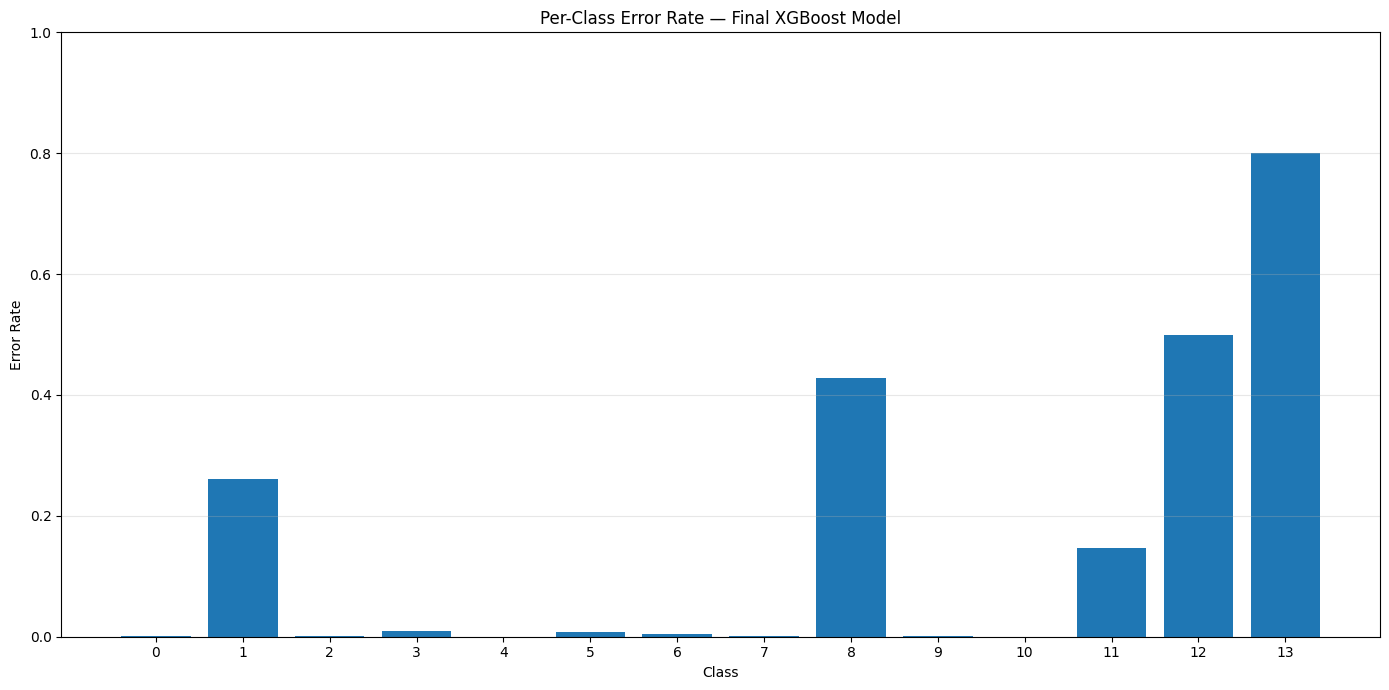

✓ Error-rate figure saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/final_xgboost_per_class_error_rate.png

FINAL XGBOOST ERROR ANALYSIS SUMMARY
Total samples          : 478,875
Correct predictions    : 478,259
Incorrect predictions  : 616
Overall accuracy       : 99.8714%
Overall error rate     : 0.1286%

Worst class            : 13
Worst class accuracy   : 20.0000%

Best class             : 10
Best class accuracy    : 100.0000%

SAVED OUTPUTS
✓ Error analysis:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_error_analysis.csv

✓ Misclassification pairs:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_misclassification_pairs.csv

✓ Error contribution:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_error_contribution.csv

✓ Error-rate figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/final_xgboost_per_class_error_rate.png

✅ CELL 31 COMPLETED


In [45]:
# =============================================================================
# CELL 31 — FINAL XGBOOST ERROR AND MISCLASSIFICATION ANALYSIS
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

print("=" * 90)
print("          CELL 31 — FINAL XGBOOST ERROR ANALYSIS")
print("=" * 90)

# -----------------------------------------------------------------------------
# 1. CHECK REQUIRED VARIABLES
# -----------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_variables = [
    "y_test_final",
    "y_pred_final"
]

for var in required_variables:
    if var not in globals():
        raise NameError(
            f"{var} is not available. Please run Cell 30 first."
        )

    print(f"✓ {var} available")

# -----------------------------------------------------------------------------
# 2. PREPARE LABEL DATA
# -----------------------------------------------------------------------------

print("\nPREPARING LABEL DATA")
print("-" * 90)

y_true = np.asarray(y_test_final).reshape(-1)
y_pred = np.asarray(y_pred_final).reshape(-1)

print("True labels shape      :", y_true.shape)
print("Predicted labels shape :", y_pred.shape)

if len(y_true) != len(y_pred):
    raise ValueError("True and predicted label lengths do not match.")

classes = np.sort(np.unique(y_true))

print("Number of classes :", len(classes))
print("Classes           :", classes)

# -----------------------------------------------------------------------------
# 3. CONFUSION MATRIX
# -----------------------------------------------------------------------------

print("\nGENERATING CONFUSION MATRIX")
print("-" * 90)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=classes
)

print("✓ Confusion matrix generated")
print("Matrix shape :", cm.shape)

# -----------------------------------------------------------------------------
# 4. OVERALL ERROR STATISTICS
# -----------------------------------------------------------------------------

print("\nCALCULATING OVERALL ERROR STATISTICS")
print("-" * 90)

total_samples = len(y_true)

correct_predictions = int(
    np.sum(y_true == y_pred)
)

incorrect_predictions = int(
    np.sum(y_true != y_pred)
)

accuracy = correct_predictions / total_samples
error_rate = incorrect_predictions / total_samples

print("Total test samples     :", f"{total_samples:,}")
print("Correct predictions    :", f"{correct_predictions:,}")
print("Incorrect predictions  :", f"{incorrect_predictions:,}")
print(f"Accuracy               : {accuracy:.6f}")
print(f"Error rate             : {error_rate:.6f}")

# -----------------------------------------------------------------------------
# 5. PER-CLASS ERROR ANALYSIS
# -----------------------------------------------------------------------------

print("\nGENERATING PER-CLASS ERROR ANALYSIS")
print("-" * 90)

error_records = []

for i, cls in enumerate(classes):

    true_count = int(np.sum(y_true == cls))

    correct_count = int(cm[i, i])

    incorrect_count = true_count - correct_count

    if true_count > 0:
        class_accuracy = correct_count / true_count
        class_error_rate = incorrect_count / true_count
    else:
        class_accuracy = 0.0
        class_error_rate = 0.0

    error_records.append({
        "Class": cls,
        "True Samples": true_count,
        "Correct Predictions": correct_count,
        "Incorrect Predictions": incorrect_count,
        "Class Accuracy": class_accuracy,
        "Class Error Rate": class_error_rate,
        "Error Contribution": (
            incorrect_count / incorrect_predictions
            if incorrect_predictions > 0 else 0.0
        )
    })

error_df = pd.DataFrame(error_records)

error_df = error_df.sort_values(
    "Incorrect Predictions",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("FINAL XGBOOST PER-CLASS ERROR ANALYSIS")
print("=" * 90)

display(error_df)

# -----------------------------------------------------------------------------
# 6. WORST AND BEST CLASSES
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("ERROR ANALYSIS SUMMARY")
print("=" * 90)

worst_class_row = error_df.sort_values(
    "Class Accuracy",
    ascending=True
).iloc[0]

best_class_row = error_df.sort_values(
    "Class Accuracy",
    ascending=False
).iloc[0]

print("Worst performing class :",
      int(worst_class_row["Class"]))

print("Class accuracy         :",
      f"{worst_class_row['Class Accuracy']:.4f}")

print("Class error rate       :",
      f"{worst_class_row['Class Error Rate']:.4f}")

print()

print("Best performing class  :",
      int(best_class_row["Class"]))

print("Class accuracy         :",
      f"{best_class_row['Class Accuracy']:.4f}")

print("Class error rate       :",
      f"{best_class_row['Class Error Rate']:.4f}")

# -----------------------------------------------------------------------------
# 7. ZERO-ERROR CLASSES
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("PERFECTLY CLASSIFIED CLASSES")
print("=" * 90)

perfect_classes = error_df.loc[
    error_df["Incorrect Predictions"] == 0,
    "Class"
].tolist()

print("Classes with zero errors:")

if len(perfect_classes) > 0:
    print(perfect_classes)
else:
    print("None")

# -----------------------------------------------------------------------------
# 8. HIGH-ERROR CLASSES
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("HIGH-ERROR CLASSES")
print("=" * 90)

high_error_classes = error_df.loc[
    error_df["Class Error Rate"] >= 0.20,
    ["Class", "True Samples", "Incorrect Predictions",
     "Class Accuracy", "Class Error Rate"]
]

if len(high_error_classes) > 0:
    display(high_error_classes)
else:
    print("No classes have an error rate of 20% or higher.")

# -----------------------------------------------------------------------------
# 9. EXTRACT MISCLASSIFICATION PAIRS
# -----------------------------------------------------------------------------

print("\nEXTRACTING MISCLASSIFICATION PAIRS")
print("-" * 90)

pair_records = []

for true_index, true_class in enumerate(classes):

    for pred_index, predicted_class in enumerate(classes):

        if true_class == predicted_class:
            continue

        count = int(
            cm[true_index, pred_index]
        )

        if count > 0:

            true_class_total = int(
                np.sum(y_true == true_class)
            )

            percentage_of_true = (
                count / true_class_total * 100
                if true_class_total > 0 else 0.0
            )

            pair_records.append({
                "True Class": true_class,
                "Predicted Class": predicted_class,
                "Misclassified Samples": count,
                "Percentage of True Class": percentage_of_true
            })

pairs_df = pd.DataFrame(pair_records)

if len(pairs_df) > 0:

    pairs_df = pairs_df.sort_values(
        "Misclassified Samples",
        ascending=False
    ).reset_index(drop=True)

else:

    pairs_df = pd.DataFrame(
        columns=[
            "True Class",
            "Predicted Class",
            "Misclassified Samples",
            "Percentage of True Class"
        ]
    )

print("\n" + "=" * 90)
print("TOP XGBOOST MISCLASSIFICATION PAIRS")
print("=" * 90)

display(pairs_df.head(20))

# -----------------------------------------------------------------------------
# 10. TOP MISCLASSIFICATION
# -----------------------------------------------------------------------------

if len(pairs_df) > 0:

    top_pair = pairs_df.iloc[0]

    print("\n" + "=" * 90)
    print("MOST COMMON MISCLASSIFICATION")
    print("=" * 90)

    print("True class       :",
          int(top_pair["True Class"]))

    print("Predicted class  :",
          int(top_pair["Predicted Class"]))

    print("Misclassified    :",
          f"{int(top_pair['Misclassified Samples']):,}",
          "samples")

    print("Percentage of true class :",
          f"{top_pair['Percentage of True Class']:.4f}%")

else:

    print("\nNo misclassification pairs found.")

# -----------------------------------------------------------------------------
# 11. ERROR CONTRIBUTION
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("CLASS CONTRIBUTION TO TOTAL ERRORS")
print("=" * 90)

contribution_df = error_df[
    [
        "Class",
        "True Samples",
        "Correct Predictions",
        "Incorrect Predictions",
        "Class Error Rate",
        "Error Contribution"
    ]
].copy()

contribution_df = contribution_df.sort_values(
    "Error Contribution",
    ascending=False
).reset_index(drop=True)

display(contribution_df)

# -----------------------------------------------------------------------------
# 12. CREATE ERROR RATE FIGURE
# -----------------------------------------------------------------------------

print("\nCREATING PER-CLASS ERROR RATE FIGURE")
print("-" * 90)

plot_df = error_df.sort_values(
    "Class"
)

plt.figure(figsize=(14, 7))

plt.bar(
    plot_df["Class"].astype(str),
    plot_df["Class Error Rate"]
)

plt.xlabel("Class")
plt.ylabel("Error Rate")
plt.title("Per-Class Error Rate — Final XGBoost Model")

plt.ylim(
    0,
    min(1.05, max(1.0, plot_df["Class Error Rate"].max() + 0.05))
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 13. SAVE DIRECTORIES
# -----------------------------------------------------------------------------

RESULTS_TABLE_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/tables"
)

RESULTS_FIGURE_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/figures"
)

os.makedirs(
    RESULTS_TABLE_DIR,
    exist_ok=True
)

os.makedirs(
    RESULTS_FIGURE_DIR,
    exist_ok=True
)

# -----------------------------------------------------------------------------
# 14. SAVE ERROR ANALYSIS
# -----------------------------------------------------------------------------

error_csv_path = os.path.join(
    RESULTS_TABLE_DIR,
    "final_xgboost_error_analysis.csv"
)

error_df.to_csv(
    error_csv_path,
    index=False
)

print("\n✓ Error analysis CSV saved:")
print(error_csv_path)

# -----------------------------------------------------------------------------
# 15. SAVE MISCLASSIFICATION PAIRS
# -----------------------------------------------------------------------------

pairs_csv_path = os.path.join(
    RESULTS_TABLE_DIR,
    "final_xgboost_misclassification_pairs.csv"
)

pairs_df.to_csv(
    pairs_csv_path,
    index=False
)

print("✓ Misclassification pairs CSV saved:")
print(pairs_csv_path)

# -----------------------------------------------------------------------------
# 16. SAVE ERROR CONTRIBUTION
# -----------------------------------------------------------------------------

contribution_csv_path = os.path.join(
    RESULTS_TABLE_DIR,
    "final_xgboost_error_contribution.csv"
)

contribution_df.to_csv(
    contribution_csv_path,
    index=False
)

print("✓ Error contribution CSV saved:")
print(contribution_csv_path)

# -----------------------------------------------------------------------------
# 17. SAVE FIGURE
# -----------------------------------------------------------------------------

error_figure_path = os.path.join(
    RESULTS_FIGURE_DIR,
    "final_xgboost_per_class_error_rate.png"
)

plt.savefig(
    error_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✓ Error-rate figure saved:")
print(error_figure_path)

# -----------------------------------------------------------------------------
# 18. FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL XGBOOST ERROR ANALYSIS SUMMARY")
print("=" * 90)

print("Total samples          :", f"{total_samples:,}")
print("Correct predictions    :", f"{correct_predictions:,}")
print("Incorrect predictions  :", f"{incorrect_predictions:,}")
print(f"Overall accuracy       : {accuracy:.4%}")
print(f"Overall error rate     : {error_rate:.4%}")

print("\nWorst class            :",
      int(worst_class_row["Class"]))

print("Worst class accuracy   :",
      f"{worst_class_row['Class Accuracy']:.4%}")

print("\nBest class             :",
      int(best_class_row["Class"]))

print("Best class accuracy    :",
      f"{best_class_row['Class Accuracy']:.4%}")

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print("✓ Error analysis:")
print(error_csv_path)

print("\n✓ Misclassification pairs:")
print(pairs_csv_path)

print("\n✓ Error contribution:")
print(contribution_csv_path)

print("\n✓ Error-rate figure:")
print(error_figure_path)

print("\n" + "=" * 90)
print("✅ CELL 31 COMPLETED")
print("=" * 90)

          CELL 32 — FINAL XGBOOST CLASS IMBALANCE IMPACT ANALYSIS

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ y_test_final available
✓ y_pred_final available

PREPARING DATA
------------------------------------------------------------------------------------------
Test samples          : 478,875
True labels shape     : (478875,)
Predicted labels shape: (478875,)
Number of classes     : 14
Classes               : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

CALCULATING OVERALL PERFORMANCE METRICS
------------------------------------------------------------------------------------------
Accuracy            : 0.998714
Balanced Accuracy   : 0.845601
Macro Precision     : 0.926422
Macro Recall        : 0.845601
Macro F1-Score      : 0.872461
Weighted F1-Score   : 0.998663

ANALYZING CLASS DISTRIBUTION
------------------------------------------------------------------------------------------

FINAL XGBOOST CLASS DI

,Class,True Count,True Percentage,Predicted Count,Predicted Percentage,Correct Predictions,Class Accuracy,Precision,Recall,F1-Score
0,0,395562,82.602349,395392,82.566849,395249,0.999209,0.999638,0.999209,0.999423
1,1,390,0.081441,319,0.066614,288,0.738462,0.902821,0.738462,0.812412
2,2,25603,5.346489,25593,5.344401,25592,0.999570,0.999961,0.999570,0.999766
3,3,224,0.046776,226,0.047194,222,0.991071,0.982301,0.991071,0.986667
4,4,34569,7.218794,34625,7.230488,34562,0.999798,0.998181,0.999798,0.998988
5,5,1046,0.218429,1048,0.218846,1037,0.991396,0.989504,0.991396,0.990449
6,6,1077,0.224902,1075,0.224484,1072,0.995357,0.997209,0.995357,0.996283
7,7,1186,0.247664,1186,0.247664,1185,0.999157,0.999157,0.999157,0.999157
8,8,7,0.001462,4,0.000835,4,0.571429,1.000000,0.571429,0.727273
9,9,18139,3.787836,18344,3.830645,18125,0.999228,0.988061,0.999228,0.993613



MAJORITY CLASS IMPACT
Majority class                  : 0
Majority class samples          : 395,562
Majority class percentage       : 82.6023%
Majority-class baseline accuracy: 82.6023%
Model accuracy improvement over majority baseline: 17.2690%

CLASS IMBALANCE PERFORMANCE GAP
Accuracy - Balanced Accuracy : 0.1531
Weighted F1 - Macro F1       : 0.1262

POORLY DETECTED CLASSES
Classes with recall below 50%:
[13]


,Class,True Count,Predicted Count,Precision,Recall,F1-Score
13,13,130,65,0.4,0.2,0.266667



ZERO-PREDICTION CLASSES
No classes have zero predictions.

MINORITY CLASS ANALYSIS
Minority threshold (<1% of test set): 4,789 samples


,Class,True Count,True Percentage,Predicted Count,Precision,Recall,F1-Score
1,1,390,0.081441,319,0.902821,0.738462,0.812412
3,3,224,0.046776,226,0.982301,0.991071,0.986667
5,5,1046,0.218429,1048,0.989504,0.991396,0.990449
6,6,1077,0.224902,1075,0.997209,0.995357,0.996283
7,7,1186,0.247664,1186,0.999157,0.999157,0.999157
8,8,7,0.001462,4,1.000000,0.571429,0.727273
10,10,644,0.134482,644,1.000000,1.000000,1.000000
11,11,294,0.061394,352,0.713068,0.853741,0.777090
12,12,4,0.000835,2,1.000000,0.500000,0.666667
13,13,130,0.027147,65,0.400000,0.200000,0.266667



CLASS PERFORMANCE SUMMARY
Worst class by F1 : 13
Worst class F1    : 0.2667

Best class by F1  : 10
Best class F1     : 1.0000

CREATING CLASS IMBALANCE FIGURE
------------------------------------------------------------------------------------------

✓ Class imbalance analysis CSV saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_class_imbalance_analysis.csv
✓ Imbalance summary CSV saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_imbalance_summary.csv


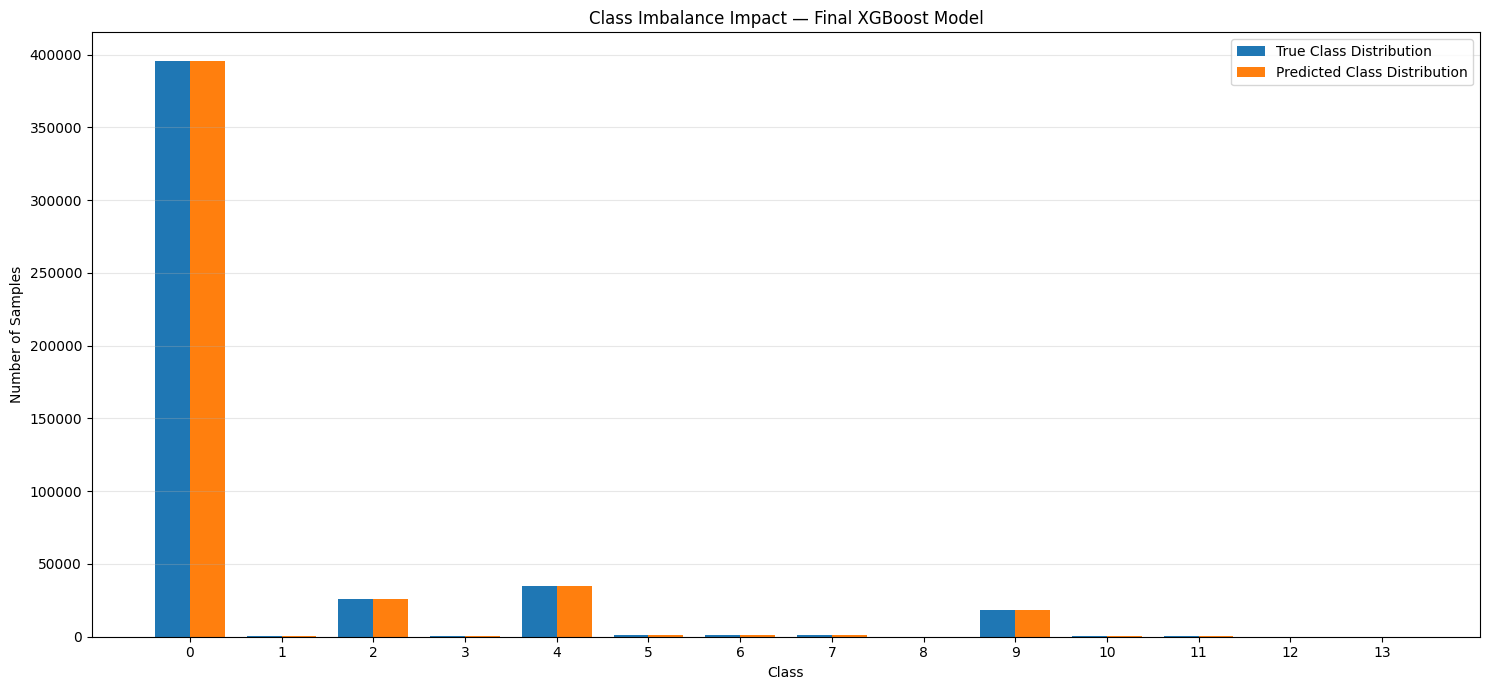

✓ Class imbalance figure saved:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/final_xgboost_class_imbalance_analysis.png

FINAL XGBOOST CLASS IMBALANCE INTERPRETATION
⚠ Overall accuracy is substantially higher than balanced accuracy.
This indicates that class imbalance affects aggregate performance.
⚠ Weighted F1 is substantially higher than Macro F1.
This indicates stronger performance on high-frequency classes.
⚠ 1 class(es) have recall below 50%.
✓ Every class is predicted at least once.

The final XGBoost model should therefore be evaluated using
Macro F1 and Balanced Accuracy in addition to overall accuracy.

SAVED OUTPUTS
✓ Class analysis CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_class_imbalance_analysis.csv

✓ Imbalance summary CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_imbalance_summary.csv

✓ Class imbalance figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/fi

In [46]:
# =============================================================================
# CELL 32 — FINAL XGBOOST CLASS IMBALANCE IMPACT ANALYSIS
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 90)
print("          CELL 32 — FINAL XGBOOST CLASS IMBALANCE IMPACT ANALYSIS")
print("=" * 90)

# -----------------------------------------------------------------------------
# 1. CHECK REQUIRED VARIABLES
# -----------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

if "y_test_final" not in globals():
    raise NameError("y_test_final is not available. Please run Cell 30 first.")

if "y_pred_final" not in globals():
    raise NameError("y_pred_final is not available. Please run Cell 30 first.")

print("✓ y_test_final available")
print("✓ y_pred_final available")

# -----------------------------------------------------------------------------
# 2. PREPARE DATA
# -----------------------------------------------------------------------------

print("\nPREPARING DATA")
print("-" * 90)

y_true = np.asarray(y_test_final).reshape(-1)
y_pred = np.asarray(y_pred_final).reshape(-1)

classes = np.sort(np.unique(y_true))

total_samples = len(y_true)

print("Test samples          :", f"{total_samples:,}")
print("True labels shape     :", y_true.shape)
print("Predicted labels shape:", y_pred.shape)
print("Number of classes     :", len(classes))
print("Classes               :", classes)

# -----------------------------------------------------------------------------
# 3. OVERALL PERFORMANCE
# -----------------------------------------------------------------------------

print("\nCALCULATING OVERALL PERFORMANCE METRICS")
print("-" * 90)

accuracy = accuracy_score(y_true, y_pred)

balanced_accuracy = balanced_accuracy_score(
    y_true,
    y_pred
)

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print(f"Accuracy            : {accuracy:.6f}")
print(f"Balanced Accuracy   : {balanced_accuracy:.6f}")
print(f"Macro Precision     : {macro_precision:.6f}")
print(f"Macro Recall        : {macro_recall:.6f}")
print(f"Macro F1-Score      : {macro_f1:.6f}")
print(f"Weighted F1-Score   : {weighted_f1:.6f}")

# -----------------------------------------------------------------------------
# 4. CLASS DISTRIBUTIONS
# -----------------------------------------------------------------------------

print("\nANALYZING CLASS DISTRIBUTION")
print("-" * 90)

true_counts = pd.Series(y_true).value_counts().reindex(
    classes,
    fill_value=0
)

pred_counts = pd.Series(y_pred).value_counts().reindex(
    classes,
    fill_value=0
)

# Per-class metrics
precision_per_class = precision_score(
    y_true,
    y_pred,
    labels=classes,
    average=None,
    zero_division=0
)

recall_per_class = recall_score(
    y_true,
    y_pred,
    labels=classes,
    average=None,
    zero_division=0
)

f1_per_class = f1_score(
    y_true,
    y_pred,
    labels=classes,
    average=None,
    zero_division=0
)

imbalance_records = []

for i, cls in enumerate(classes):

    true_count = int(true_counts.loc[cls])
    predicted_count = int(pred_counts.loc[cls])

    true_percentage = (
        true_count / total_samples * 100
    )

    predicted_percentage = (
        predicted_count / total_samples * 100
    )

    correct_count = int(
        np.sum(
            (y_true == cls) &
            (y_pred == cls)
        )
    )

    class_accuracy = (
        correct_count / true_count
        if true_count > 0 else 0
    )

    imbalance_records.append({
        "Class": cls,
        "True Count": true_count,
        "True Percentage": true_percentage,
        "Predicted Count": predicted_count,
        "Predicted Percentage": predicted_percentage,
        "Correct Predictions": correct_count,
        "Class Accuracy": class_accuracy,
        "Precision": precision_per_class[i],
        "Recall": recall_per_class[i],
        "F1-Score": f1_per_class[i]
    })

imbalance_df = pd.DataFrame(
    imbalance_records
)

print("\n" + "=" * 90)
print("FINAL XGBOOST CLASS DISTRIBUTION AND PERFORMANCE")
print("=" * 90)

display(imbalance_df)

# -----------------------------------------------------------------------------
# 5. MAJORITY CLASS ANALYSIS
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("MAJORITY CLASS IMPACT")
print("=" * 90)

majority_class = int(
    true_counts.idxmax()
)

majority_count = int(
    true_counts.max()
)

majority_percentage = (
    majority_count / total_samples
)

majority_baseline = majority_percentage

accuracy_improvement = (
    accuracy - majority_baseline
)

print("Majority class                  :", majority_class)
print("Majority class samples          :", f"{majority_count:,}")
print(
    "Majority class percentage       :",
    f"{majority_percentage:.4%}"
)

print(
    "Majority-class baseline accuracy:",
    f"{majority_baseline:.4%}"
)

print(
    "Model accuracy improvement over majority baseline:",
    f"{accuracy_improvement:.4%}"
)

# -----------------------------------------------------------------------------
# 6. PERFORMANCE GAP
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("CLASS IMBALANCE PERFORMANCE GAP")
print("=" * 90)

accuracy_balanced_gap = (
    accuracy - balanced_accuracy
)

weighted_macro_gap = (
    weighted_f1 - macro_f1
)

print(
    "Accuracy - Balanced Accuracy :",
    f"{accuracy_balanced_gap:.4f}"
)

print(
    "Weighted F1 - Macro F1       :",
    f"{weighted_macro_gap:.4f}"
)

# -----------------------------------------------------------------------------
# 7. POORLY DETECTED CLASSES
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("POORLY DETECTED CLASSES")
print("=" * 90)

poor_classes = imbalance_df[
    imbalance_df["Recall"] < 0.50
]

if len(poor_classes) > 0:
    print("Classes with recall below 50%:")
    print(
        poor_classes["Class"].tolist()
    )
    display(
        poor_classes[
            [
                "Class",
                "True Count",
                "Predicted Count",
                "Precision",
                "Recall",
                "F1-Score"
            ]
        ]
    )
else:
    print("No classes have recall below 50%.")

# -----------------------------------------------------------------------------
# 8. ZERO-PREDICTION CLASSES
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("ZERO-PREDICTION CLASSES")
print("=" * 90)

zero_prediction_classes = imbalance_df.loc[
    imbalance_df["Predicted Count"] == 0,
    "Class"
].tolist()

if len(zero_prediction_classes) > 0:
    print(
        "Classes never predicted:",
        zero_prediction_classes
    )
else:
    print("No classes have zero predictions.")

# -----------------------------------------------------------------------------
# 9. MINORITY CLASSES
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("MINORITY CLASS ANALYSIS")
print("=" * 90)

minority_threshold = (
    total_samples * 0.01
)

minority_df = imbalance_df[
    imbalance_df["True Count"] < minority_threshold
].copy()

print(
    "Minority threshold (<1% of test set):",
    f"{minority_threshold:,.0f}",
    "samples"
)

if len(minority_df) > 0:
    display(
        minority_df[
            [
                "Class",
                "True Count",
                "True Percentage",
                "Predicted Count",
                "Precision",
                "Recall",
                "F1-Score"
            ]
        ]
    )
else:
    print("No classes fall below the 1% threshold.")

# -----------------------------------------------------------------------------
# 10. IDENTIFY STRONGEST AND WEAKEST CLASSES
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("CLASS PERFORMANCE SUMMARY")
print("=" * 90)

worst_f1_row = imbalance_df.loc[
    imbalance_df["F1-Score"].idxmin()
]

best_f1_row = imbalance_df.loc[
    imbalance_df["F1-Score"].idxmax()
]

print(
    "Worst class by F1 :",
    int(worst_f1_row["Class"])
)

print(
    "Worst class F1    :",
    f"{worst_f1_row['F1-Score']:.4f}"
)

print()

print(
    "Best class by F1  :",
    int(best_f1_row["Class"])
)

print(
    "Best class F1     :",
    f"{best_f1_row['F1-Score']:.4f}"
)

# -----------------------------------------------------------------------------
# 11. CREATE CLASS IMBALANCE FIGURE
# -----------------------------------------------------------------------------

print("\nCREATING CLASS IMBALANCE FIGURE")
print("-" * 90)

x = np.arange(len(classes))
width = 0.38

plt.figure(figsize=(15, 7))

plt.bar(
    x - width / 2,
    true_counts.values,
    width,
    label="True Class Distribution"
)

plt.bar(
    x + width / 2,
    pred_counts.values,
    width,
    label="Predicted Class Distribution"
)

plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title(
    "Class Imbalance Impact — Final XGBoost Model"
)

plt.xticks(
    x,
    classes
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 12. SAVE OUTPUT DIRECTORIES
# -----------------------------------------------------------------------------

RESULTS_TABLE_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/tables"
)

RESULTS_FIGURE_DIR = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results/figures"
)

os.makedirs(
    RESULTS_TABLE_DIR,
    exist_ok=True
)

os.makedirs(
    RESULTS_FIGURE_DIR,
    exist_ok=True
)

# -----------------------------------------------------------------------------
# 13. SAVE CLASS ANALYSIS
# -----------------------------------------------------------------------------

class_analysis_path = os.path.join(
    RESULTS_TABLE_DIR,
    "final_xgboost_class_imbalance_analysis.csv"
)

imbalance_df.to_csv(
    class_analysis_path,
    index=False
)

print("\n✓ Class imbalance analysis CSV saved:")
print(class_analysis_path)

# -----------------------------------------------------------------------------
# 14. SAVE SUMMARY
# -----------------------------------------------------------------------------

summary_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Majority Class",
        "Majority Class Percentage",
        "Majority Baseline Accuracy",
        "Accuracy Improvement Over Majority Baseline",
        "Accuracy Balanced Accuracy Gap",
        "Weighted F1 Macro F1 Gap",
        "Number of Classes",
        "Number of Poor Recall Classes",
        "Number of Zero Prediction Classes"
    ],
    "Value": [
        accuracy,
        balanced_accuracy,
        macro_precision,
        macro_recall,
        macro_f1,
        weighted_f1,
        majority_class,
        majority_percentage,
        majority_baseline,
        accuracy_improvement,
        accuracy_balanced_gap,
        weighted_macro_gap,
        len(classes),
        len(poor_classes),
        len(zero_prediction_classes)
    ]
})

summary_path = os.path.join(
    RESULTS_TABLE_DIR,
    "final_xgboost_imbalance_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

print("✓ Imbalance summary CSV saved:")
print(summary_path)

# -----------------------------------------------------------------------------
# 15. SAVE FIGURE
# -----------------------------------------------------------------------------

figure_path = os.path.join(
    RESULTS_FIGURE_DIR,
    "final_xgboost_class_imbalance_analysis.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✓ Class imbalance figure saved:")
print(figure_path)

# -----------------------------------------------------------------------------
# 16. FINAL INTERPRETATION
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL XGBOOST CLASS IMBALANCE INTERPRETATION")
print("=" * 90)

if accuracy_balanced_gap > 0.10:
    print(
        "⚠ Overall accuracy is substantially higher than balanced accuracy."
    )
    print(
        "This indicates that class imbalance affects aggregate performance."
    )
else:
    print(
        "✓ Accuracy and balanced accuracy are relatively close."
    )

if weighted_macro_gap > 0.10:
    print(
        "⚠ Weighted F1 is substantially higher than Macro F1."
    )
    print(
        "This indicates stronger performance on high-frequency classes."
    )
else:
    print(
        "✓ Weighted and Macro F1 are relatively close."
    )

if len(poor_classes) > 0:
    print(
        f"⚠ {len(poor_classes)} class(es) have recall below 50%."
    )

if len(zero_prediction_classes) > 0:
    print(
        f"⚠ {len(zero_prediction_classes)} class(es) are never predicted."
    )
else:
    print(
        "✓ Every class is predicted at least once."
    )

print(
    "\nThe final XGBoost model should therefore be evaluated using"
)
print(
    "Macro F1 and Balanced Accuracy in addition to overall accuracy."
)

# -----------------------------------------------------------------------------
# 17. COMPLETION
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print("✓ Class analysis CSV:")
print(class_analysis_path)

print("\n✓ Imbalance summary CSV:")
print(summary_path)

print("\n✓ Class imbalance figure:")
print(figure_path)

print("\n" + "=" * 90)
print("✅ CELL 32 COMPLETED")
print("=" * 90)

          CELL 33 — FINAL XGBOOST TRAINING VS TESTING PERFORMANCE

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ X_train available
✓ y_train available
✓ X_test available
✓ y_test available

SEARCHING FOR FINAL XGBOOST MODEL
------------------------------------------------------------------------------------------
✓ Found XGBoost model: xgb_model

PREPARING TRAINING AND TESTING DATA
------------------------------------------------------------------------------------------
Training data shape : (1723950, 78)
Training labels     : (1723950,)
Testing data shape  : (478875, 78)
Testing labels      : (478875,)

GENERATING TRAINING PREDICTIONS
------------------------------------------------------------------------------------------
✓ Training predictions generated
Training prediction shape: (1723950,)

GENERATING TESTING PREDICTIONS
--------------------------------------------------------------------------------------

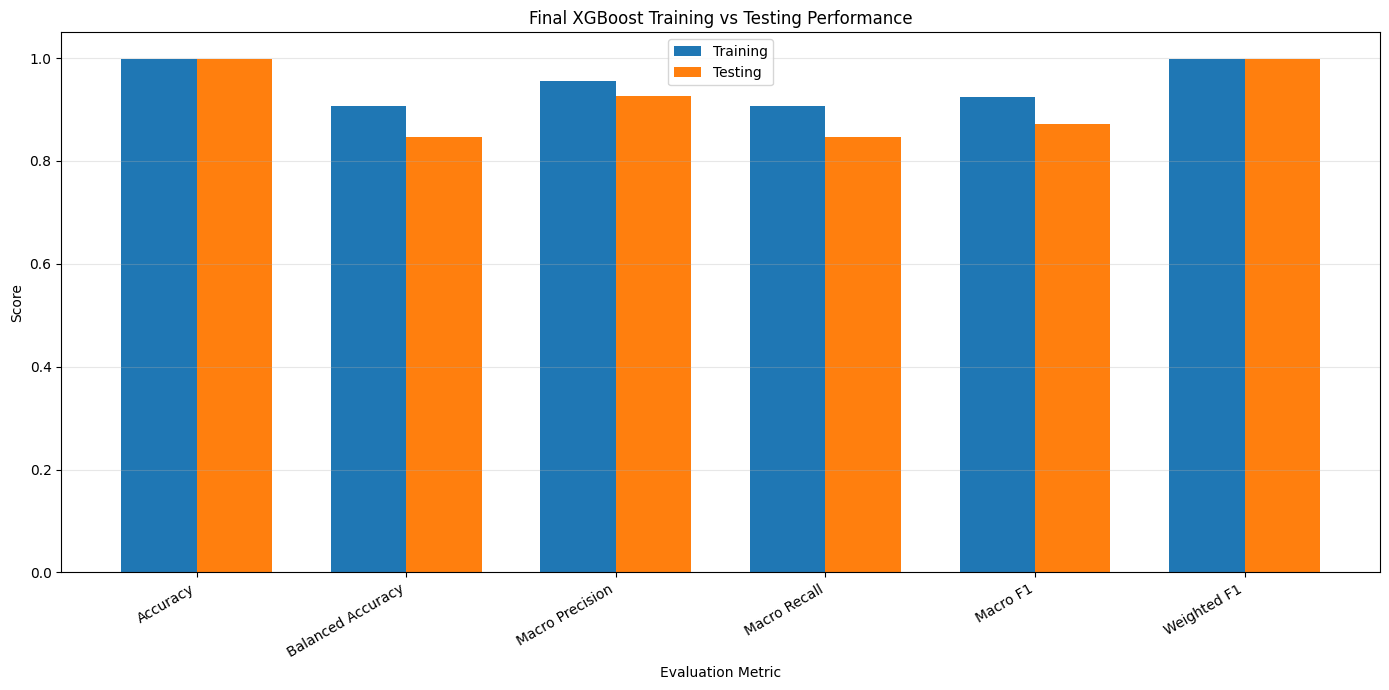


FINAL XGBOOST TRAINING–TESTING SUMMARY
Model                : xgb_model
Training Accuracy    : 0.998940
Testing Accuracy     : 0.998714
Accuracy Gap         : 0.000226
Training Macro F1    : 0.924744
Testing Macro F1     : 0.872461
Macro F1 Gap         : 0.052283

SAVED OUTPUTS
✓ Performance CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_training_vs_testing_performance.csv

✓ Training vs testing figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/final_xgboost_training_vs_testing_performance.png

CSV exists    : True
Figure exists : True

✅ CELL 33 COMPLETED


In [47]:
# =============================================================================
# CELL 33 — FINAL XGBOOST TRAINING VS TESTING PERFORMANCE
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 90)
print("          CELL 33 — FINAL XGBOOST TRAINING VS TESTING PERFORMANCE")
print("=" * 90)

# -----------------------------------------------------------------------------
# 1. CHECK REQUIRED VARIABLES
# -----------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_names = ["X_train", "y_train", "X_test", "y_test"]

for name in required_names:
    if name in globals():
        print(f"✓ {name} available")
    else:
        print(f"✗ {name} NOT available")

# -----------------------------------------------------------------------------
# 2. FIND FINAL XGBOOST MODEL
# -----------------------------------------------------------------------------

print("\nSEARCHING FOR FINAL XGBOOST MODEL")
print("-" * 90)

xgb_candidates = [
    "xgb_model",
    "xgbclassifier",
    "XGBClassifier",
    "final_xgb_model",
    "best_xgb_model"
]

final_xgb = None
final_xgb_name = None

for candidate in xgb_candidates:
    if candidate in globals():
        obj = globals()[candidate]

        # Check that it has predict capability
        if hasattr(obj, "predict"):
            final_xgb = obj
            final_xgb_name = candidate
            print(f"✓ Found XGBoost model: {candidate}")
            break

if final_xgb is None:
    raise NameError(
        "Final XGBoost model object was not found. "
        "Expected one of: " + ", ".join(xgb_candidates)
    )

# -----------------------------------------------------------------------------
# 3. PREPARE TRAINING AND TESTING DATA
# -----------------------------------------------------------------------------

print("\nPREPARING TRAINING AND TESTING DATA")
print("-" * 90)

X_train_final = X_train
y_train_final = np.asarray(y_train)

X_test_final = X_test
y_test_final = np.asarray(y_test)

print(f"Training data shape : {X_train_final.shape}")
print(f"Training labels     : {y_train_final.shape}")
print(f"Testing data shape  : {X_test_final.shape}")
print(f"Testing labels      : {y_test_final.shape}")

# -----------------------------------------------------------------------------
# 4. GENERATE TRAINING PREDICTIONS
# -----------------------------------------------------------------------------

print("\nGENERATING TRAINING PREDICTIONS")
print("-" * 90)

y_pred_train_final = final_xgb.predict(X_train_final)

# Flatten predictions if necessary
y_pred_train_final = np.asarray(y_pred_train_final).reshape(-1)

print("✓ Training predictions generated")
print(f"Training prediction shape: {y_pred_train_final.shape}")

# -----------------------------------------------------------------------------
# 5. GENERATE TESTING PREDICTIONS
# -----------------------------------------------------------------------------

print("\nGENERATING TESTING PREDICTIONS")
print("-" * 90)

y_pred_test_final = final_xgb.predict(X_test_final)
y_pred_test_final = np.asarray(y_pred_test_final).reshape(-1)

print("✓ Testing predictions generated")
print(f"Testing prediction shape: {y_pred_test_final.shape}")

# Keep these variables available for later cells
y_pred_final = y_pred_test_final

# -----------------------------------------------------------------------------
# 6. FUNCTION FOR MODEL METRICS
# -----------------------------------------------------------------------------

def calculate_final_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    }

# -----------------------------------------------------------------------------
# 7. CALCULATE TRAINING METRICS
# -----------------------------------------------------------------------------

print("\nCALCULATING TRAINING METRICS")
print("-" * 90)

train_metrics = calculate_final_metrics(
    y_train_final,
    y_pred_train_final
)

print("\nTRAINING PERFORMANCE")
print("-" * 90)

for metric, value in train_metrics.items():
    print(f"{metric:<22}: {value:.6f}")

# -----------------------------------------------------------------------------
# 8. CALCULATE TESTING METRICS
# -----------------------------------------------------------------------------

print("\nCALCULATING TESTING METRICS")
print("-" * 90)

test_metrics = calculate_final_metrics(
    y_test_final,
    y_pred_test_final
)

print("\nTESTING PERFORMANCE")
print("-" * 90)

for metric, value in test_metrics.items():
    print(f"{metric:<22}: {value:.6f}")

# -----------------------------------------------------------------------------
# 9. CALCULATE TRAIN-TEST GAPS
# -----------------------------------------------------------------------------

print("\nCALCULATING TRAINING–TESTING PERFORMANCE GAPS")
print("-" * 90)

gap_metrics = {}

for metric in train_metrics:
    gap_metrics[metric] = (
        train_metrics[metric] - test_metrics[metric]
    )

print("\nTRAINING vs TESTING GAP")
print("-" * 90)

for metric, value in gap_metrics.items():
    print(f"{metric:<22}: {value:.6f}")

# -----------------------------------------------------------------------------
# 10. CREATE COMPARISON TABLE
# -----------------------------------------------------------------------------

comparison_df = pd.DataFrame({
    "Metric": list(train_metrics.keys()),
    "Training": list(train_metrics.values()),
    "Testing": list(test_metrics.values()),
    "Train-Test Gap": list(gap_metrics.values())
})

print("\n" + "=" * 90)
print("FINAL XGBOOST TRAINING VS TESTING PERFORMANCE")
print("=" * 90)

print(comparison_df.to_string(index=False))

# -----------------------------------------------------------------------------
# 11. OVERFITTING INTERPRETATION
# -----------------------------------------------------------------------------

accuracy_gap = gap_metrics["Accuracy"]
macro_f1_gap = gap_metrics["Macro F1"]

print("\n" + "=" * 90)
print("OVERFITTING ANALYSIS")
print("=" * 90)

print(f"Training Accuracy : {train_metrics['Accuracy']:.6f}")
print(f"Testing Accuracy  : {test_metrics['Accuracy']:.6f}")
print(f"Accuracy Gap      : {accuracy_gap:.6f}")

print(f"\nTraining Macro F1  : {train_metrics['Macro F1']:.6f}")
print(f"Testing Macro F1   : {test_metrics['Macro F1']:.6f}")
print(f"Macro F1 Gap       : {macro_f1_gap:.6f}")

if accuracy_gap <= 0.01:
    print("\n✓ Accuracy gap is small.")
    print("✓ No strong evidence of accuracy-based overfitting.")
elif accuracy_gap <= 0.05:
    print("\n⚠ Moderate training-testing accuracy gap detected.")
    print("⚠ The model may have some degree of overfitting.")
else:
    print("\n⚠ Large training-testing accuracy gap detected.")
    print("⚠ Strong evidence of possible overfitting.")

# -----------------------------------------------------------------------------
# 12. SAVE RESULTS
# -----------------------------------------------------------------------------

results_dir = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results"
tables_dir = os.path.join(results_dir, "tables")
figures_dir = os.path.join(results_dir, "figures")

os.makedirs(tables_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)

comparison_path = os.path.join(
    tables_dir,
    "final_xgboost_training_vs_testing_performance.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("\n" + "=" * 90)
print("SAVED PERFORMANCE TABLE")
print("=" * 90)

print(f"✓ Training vs testing CSV saved:")
print(comparison_path)

# -----------------------------------------------------------------------------
# 13. CREATE TRAINING VS TESTING FIGURE
# -----------------------------------------------------------------------------

print("\nCREATING TRAINING VS TESTING PERFORMANCE FIGURE")
print("-" * 90)

metrics = comparison_df["Metric"].tolist()
training_values = comparison_df["Training"].tolist()
testing_values = comparison_df["Testing"].tolist()

x = np.arange(len(metrics))
width = 0.36

plt.figure(figsize=(14, 7))

plt.bar(
    x - width / 2,
    training_values,
    width,
    label="Training"
)

plt.bar(
    x + width / 2,
    testing_values,
    width,
    label="Testing"
)

plt.xticks(
    x,
    metrics,
    rotation=30,
    ha="right"
)

plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.title("Final XGBoost Training vs Testing Performance")

plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

figure_path = os.path.join(
    figures_dir,
    "final_xgboost_training_vs_testing_performance.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# -----------------------------------------------------------------------------
# 14. FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL XGBOOST TRAINING–TESTING SUMMARY")
print("=" * 90)

print(f"Model                : {final_xgb_name}")
print(f"Training Accuracy    : {train_metrics['Accuracy']:.6f}")
print(f"Testing Accuracy     : {test_metrics['Accuracy']:.6f}")
print(f"Accuracy Gap         : {accuracy_gap:.6f}")

print(f"Training Macro F1    : {train_metrics['Macro F1']:.6f}")
print(f"Testing Macro F1     : {test_metrics['Macro F1']:.6f}")
print(f"Macro F1 Gap         : {macro_f1_gap:.6f}")

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print(f"✓ Performance CSV:")
print(comparison_path)

print(f"\n✓ Training vs testing figure:")
print(figure_path)

print(f"\nCSV exists    : {os.path.exists(comparison_path)}")
print(f"Figure exists : {os.path.exists(figure_path)}")

print("\n" + "=" * 90)
print("✅ CELL 33 COMPLETED")
print("=" * 90)

          CELL 34 — FINAL XGBOOST ROC-AUC + PR-AUC ANALYSIS

CHECKING REQUIRED VARIABLES
--------------------------------------------------------------------------------
✓ X_test available
✓ y_test available
✓ xgb_model available

PREPARING TEST DATA
--------------------------------------------------------------------------------
Test data shape : (478875, 78)
Test labels shape: (478875,)
Number of classes: 14
Classes          : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

GENERATING XGBOOST CLASS PROBABILITIES
--------------------------------------------------------------------------------
Probability output shape: (478875, 14)
Model classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

PREPARING ONE-VS-REST LABELS
--------------------------------------------------------------------------------
Binarized label shape: (478875, 14)

CALCULATING PER-CLASS ROC-AUC AND PR-AUC
--------------------------------------------------------------------------------

PER-CLASS ROC-AUC AND PR-AUC
 Cla

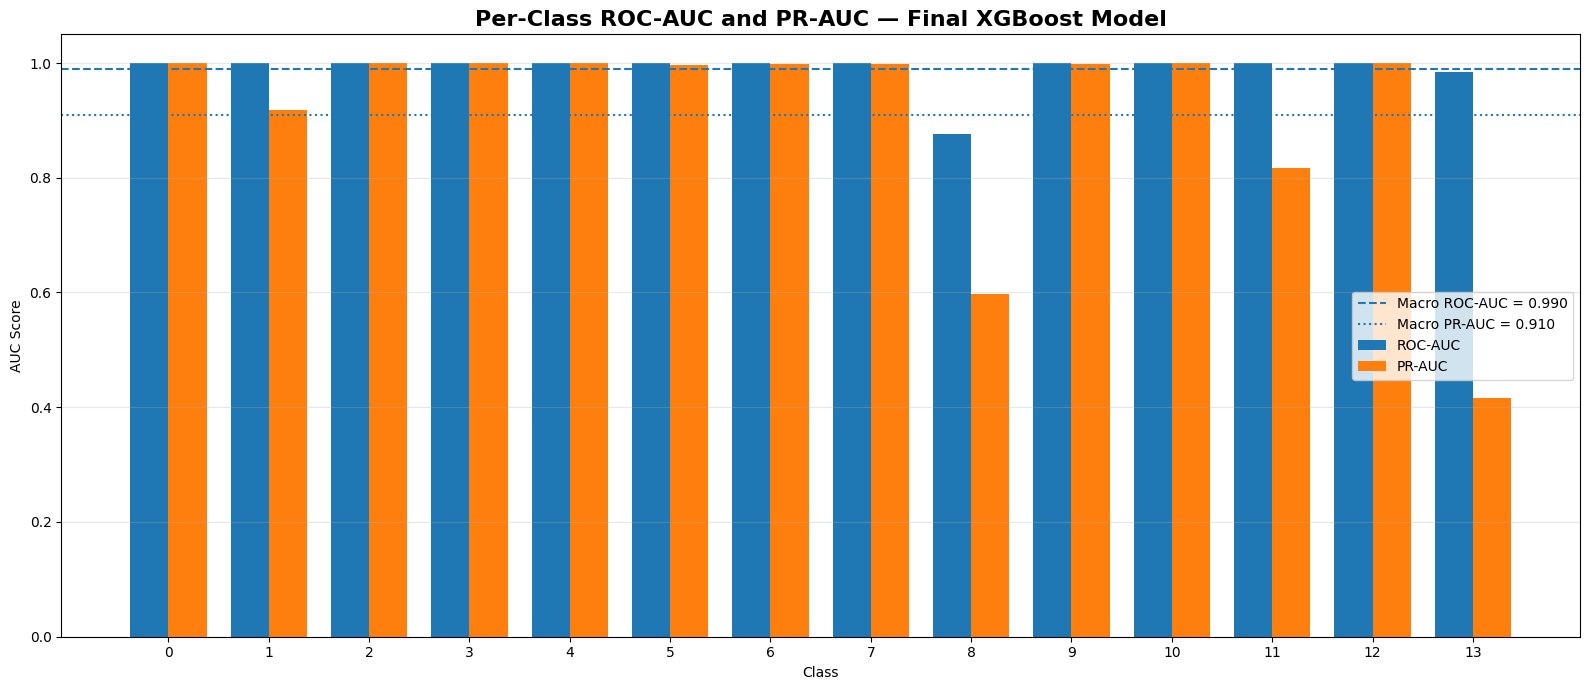


SAVED OUTPUTS
✓ ROC-AUC / PR-AUC CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_roc_pr_auc.csv

✓ ROC-AUC / PR-AUC comparison figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/final_xgboost_roc_pr_auc_comparison.png

CSV exists    : True
Figure exists : True

✅ CELL 34 COMPLETED


In [48]:
# =============================================================================
# CELL 34 — FINAL XGBOOST ROC-AUC + PRECISION-RECALL AUC ANALYSIS
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score, average_precision_score

print("=" * 90)
print("          CELL 34 — FINAL XGBOOST ROC-AUC + PR-AUC ANALYSIS")
print("=" * 90)

# -----------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# -----------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 80)

required_vars = ["X_test", "y_test", "xgb_model"]

for var in required_vars:
    if var in globals():
        print(f"✓ {var} available")
    else:
        raise NameError(f"Required variable '{var}' is not available.")

# -----------------------------------------------------------------------------
# PREPARE TEST DATA
# -----------------------------------------------------------------------------

print("\nPREPARING TEST DATA")
print("-" * 80)

X_test_final = X_test.copy()
y_test_final = np.asarray(y_test)

print(f"Test data shape : {X_test_final.shape}")
print(f"Test labels shape: {y_test_final.shape}")

classes = np.unique(y_test_final)
n_classes = len(classes)

print(f"Number of classes: {n_classes}")
print(f"Classes          : {classes}")

# -----------------------------------------------------------------------------
# GENERATE PROBABILITY PREDICTIONS
# -----------------------------------------------------------------------------

print("\nGENERATING XGBOOST CLASS PROBABILITIES")
print("-" * 80)

if not hasattr(xgb_model, "predict_proba"):
    raise AttributeError("xgb_model does not support predict_proba().")

y_proba = xgb_model.predict_proba(X_test_final)

print(f"Probability output shape: {y_proba.shape}")

# Make sure probability columns correspond to the actual model classes
if hasattr(xgb_model, "classes_"):
    model_classes = np.asarray(xgb_model.classes_)
else:
    model_classes = classes

print(f"Model classes: {model_classes}")

# -----------------------------------------------------------------------------
# ALIGN PROBABILITY MATRIX IF NECESSARY
# -----------------------------------------------------------------------------

if y_proba.shape[1] != n_classes:
    raise ValueError(
        f"Probability matrix has {y_proba.shape[1]} columns, "
        f"but test data contains {n_classes} classes."
    )

# -----------------------------------------------------------------------------
# ONE-VS-REST LABEL BINARIZATION
# -----------------------------------------------------------------------------

print("\nPREPARING ONE-VS-REST LABELS")
print("-" * 80)

y_test_bin = label_binarize(
    y_test_final,
    classes=classes
)

print(f"Binarized label shape: {y_test_bin.shape}")

# -----------------------------------------------------------------------------
# CALCULATE PER-CLASS ROC-AUC AND PR-AUC
# -----------------------------------------------------------------------------

print("\nCALCULATING PER-CLASS ROC-AUC AND PR-AUC")
print("-" * 80)

roc_auc_values = []
pr_auc_values = []

for i, cls in enumerate(classes):

    y_true_class = y_test_bin[:, i]
    y_score_class = y_proba[:, i]

    # ROC-AUC requires both positive and negative samples
    if len(np.unique(y_true_class)) < 2:
        roc_auc = np.nan
    else:
        roc_auc = roc_auc_score(
            y_true_class,
            y_score_class
        )

    # Average precision is used as PR-AUC
    pr_auc = average_precision_score(
        y_true_class,
        y_score_class
    )

    roc_auc_values.append(roc_auc)
    pr_auc_values.append(pr_auc)

auc_df = pd.DataFrame({
    "Class": classes,
    "ROC-AUC": roc_auc_values,
    "PR-AUC": pr_auc_values
})

print("\n" + "=" * 90)
print("PER-CLASS ROC-AUC AND PR-AUC")
print("=" * 90)

print(
    auc_df.to_string(
        index=False,
        formatters={
            "ROC-AUC": "{:.4f}".format,
            "PR-AUC": "{:.4f}".format
        }
    )
)

# -----------------------------------------------------------------------------
# OVERALL AUC
# -----------------------------------------------------------------------------

macro_roc_auc = np.nanmean(roc_auc_values)
macro_pr_auc = np.mean(pr_auc_values)

print("\n" + "=" * 90)
print("OVERALL AUC SUMMARY")
print("=" * 90)

print(f"Macro ROC-AUC : {macro_roc_auc:.4f}")
print(f"Macro PR-AUC  : {macro_pr_auc:.4f}")

# -----------------------------------------------------------------------------
# BEST / WORST CLASSES
# -----------------------------------------------------------------------------

valid_roc = auc_df.dropna(subset=["ROC-AUC"])

best_roc_row = valid_roc.loc[
    valid_roc["ROC-AUC"].idxmax()
]

worst_roc_row = valid_roc.loc[
    valid_roc["ROC-AUC"].idxmin()
]

best_pr_row = auc_df.loc[
    auc_df["PR-AUC"].idxmax()
]

worst_pr_row = auc_df.loc[
    auc_df["PR-AUC"].idxmin()
]

print("\n" + "=" * 90)
print("AUC PERFORMANCE SUMMARY")
print("=" * 90)

print(
    f"Best ROC-AUC class  : {int(best_roc_row['Class'])}"
)
print(
    f"Best ROC-AUC        : {best_roc_row['ROC-AUC']:.4f}"
)

print(
    f"Worst ROC-AUC class : {int(worst_roc_row['Class'])}"
)
print(
    f"Worst ROC-AUC       : {worst_roc_row['ROC-AUC']:.4f}"
)

print(
    f"\nBest PR-AUC class   : {int(best_pr_row['Class'])}"
)
print(
    f"Best PR-AUC         : {best_pr_row['PR-AUC']:.4f}"
)

print(
    f"Worst PR-AUC class  : {int(worst_pr_row['Class'])}"
)
print(
    f"Worst PR-AUC        : {worst_pr_row['PR-AUC']:.4f}"
)

# -----------------------------------------------------------------------------
# INTERPRETATION
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("AUC INTERPRETATION")
print("=" * 90)

print(
    "ROC-AUC measures the ability of XGBoost to distinguish each class "
    "from all other classes."
)

print(
    "PR-AUC measures precision-recall performance and is especially "
    "useful for imbalanced multiclass classification."
)

if macro_roc_auc > 0.90:
    print(
        "✓ Macro ROC-AUC is very strong, indicating strong class "
        "discrimination overall."
    )
elif macro_roc_auc > 0.70:
    print(
        "✓ Macro ROC-AUC indicates good overall class discrimination."
    )
else:
    print(
        "⚠ Macro ROC-AUC indicates weaker discrimination across classes."
    )

if macro_pr_auc < macro_roc_auc:
    print(
        "⚠ Macro PR-AUC is lower than Macro ROC-AUC, which can indicate "
        "difficulty maintaining precision across minority classes."
    )

# -----------------------------------------------------------------------------
# SAVE RESULTS
# -----------------------------------------------------------------------------

results_dir = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results"
tables_dir = os.path.join(results_dir, "tables")
figures_dir = os.path.join(results_dir, "figures")

os.makedirs(tables_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)

auc_csv_path = os.path.join(
    tables_dir,
    "final_xgboost_roc_pr_auc.csv"
)

auc_df.to_csv(
    auc_csv_path,
    index=False
)

# -----------------------------------------------------------------------------
# CREATE FIGURE
# -----------------------------------------------------------------------------

print("\nCREATING ROC-AUC / PR-AUC COMPARISON FIGURE")
print("-" * 80)

x = np.arange(len(classes))
width = 0.38

fig, ax = plt.subplots(figsize=(16, 7))

ax.bar(
    x - width / 2,
    auc_df["ROC-AUC"],
    width,
    label="ROC-AUC"
)

ax.bar(
    x + width / 2,
    auc_df["PR-AUC"],
    width,
    label="PR-AUC"
)

ax.axhline(
    macro_roc_auc,
    linestyle="--",
    linewidth=1.5,
    label=f"Macro ROC-AUC = {macro_roc_auc:.3f}"
)

ax.axhline(
    macro_pr_auc,
    linestyle=":",
    linewidth=1.5,
    label=f"Macro PR-AUC = {macro_pr_auc:.3f}"
)

ax.set_title(
    "Per-Class ROC-AUC and PR-AUC — Final XGBoost Model",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Class")
ax.set_ylabel("AUC Score")

ax.set_xticks(x)
ax.set_xticklabels(classes)

ax.set_ylim(0, 1.05)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

figure_path = os.path.join(
    figures_dir,
    "final_xgboost_roc_pr_auc_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# -----------------------------------------------------------------------------
# FINAL OUTPUT
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print(f"✓ ROC-AUC / PR-AUC CSV:")
print(auc_csv_path)

print(f"\n✓ ROC-AUC / PR-AUC comparison figure:")
print(figure_path)

print(f"\nCSV exists    : {os.path.exists(auc_csv_path)}")
print(f"Figure exists : {os.path.exists(figure_path)}")

print("\n" + "=" * 90)
print("✅ CELL 34 COMPLETED")
print("=" * 90)

In [49]:
# =============================================================================
# CELL 35 — FINAL XGBOOST CLASSIFICATION REPORT
# =============================================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 90)
print("          CELL 35 — FINAL XGBOOST CLASSIFICATION REPORT")
print("=" * 90)

# -----------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# -----------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 80)

required_vars = [
    "X_train",
    "y_train",
    "X_test",
    "y_test",
    "xgb_model"
]

for var in required_vars:
    if var in globals():
        print(f"✓ {var} available")
    else:
        raise NameError(
            f"Required variable '{var}' is not available."
        )

# -----------------------------------------------------------------------------
# PREPARE DATA
# -----------------------------------------------------------------------------

print("\nPREPARING FINAL TEST DATA")
print("-" * 80)

X_test_final = X_test
y_test_final = np.asarray(y_test)

print(f"Test data shape  : {X_test_final.shape}")
print(f"Test labels shape: {y_test_final.shape}")

classes = np.unique(y_test_final)

print(f"Number of classes: {len(classes)}")
print(f"Classes          : {classes}")

# -----------------------------------------------------------------------------
# GENERATE TEST PREDICTIONS
# -----------------------------------------------------------------------------

print("\nGENERATING FINAL XGBOOST TEST PREDICTIONS")
print("-" * 80)

y_pred_final = xgb_model.predict(X_test_final)

y_pred_final = np.asarray(y_pred_final).reshape(-1)

print("✓ Final test predictions generated")
print(f"Prediction shape: {y_pred_final.shape}")

# -----------------------------------------------------------------------------
# OVERALL METRICS
# -----------------------------------------------------------------------------

print("\nCALCULATING FINAL TEST METRICS")
print("-" * 80)

final_accuracy = accuracy_score(
    y_test_final,
    y_pred_final
)

final_balanced_accuracy = balanced_accuracy_score(
    y_test_final,
    y_pred_final
)

final_macro_precision = precision_score(
    y_test_final,
    y_pred_final,
    average="macro",
    zero_division=0
)

final_macro_recall = recall_score(
    y_test_final,
    y_pred_final,
    average="macro",
    zero_division=0
)

final_macro_f1 = f1_score(
    y_test_final,
    y_pred_final,
    average="macro",
    zero_division=0
)

final_weighted_f1 = f1_score(
    y_test_final,
    y_pred_final,
    average="weighted",
    zero_division=0
)

print("\n" + "=" * 90)
print("FINAL XGBOOST TEST PERFORMANCE")
print("=" * 90)

print(f"Accuracy              : {final_accuracy:.6f}")
print(f"Balanced Accuracy     : {final_balanced_accuracy:.6f}")
print(f"Macro Precision       : {final_macro_precision:.6f}")
print(f"Macro Recall          : {final_macro_recall:.6f}")
print(f"Macro F1              : {final_macro_f1:.6f}")
print(f"Weighted F1           : {final_weighted_f1:.6f}")

# -----------------------------------------------------------------------------
# CLASSIFICATION REPORT
# -----------------------------------------------------------------------------

print("\nGENERATING CLASSIFICATION REPORT")
print("-" * 80)

report_dict = classification_report(
    y_test_final,
    y_pred_final,
    labels=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

# Keep only actual class rows for class-level analysis
class_report_df = report_df.loc[
    [str(cls) for cls in classes]
].copy()

class_report_df.insert(
    0,
    "Class",
    classes
)

print("\n" + "=" * 90)
print("CLASSIFICATION REPORT — FINAL XGBOOST")
print("=" * 90)

print(
    report_df.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)

# -----------------------------------------------------------------------------
# PER-CLASS SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("PER-CLASS PERFORMANCE SUMMARY")
print("=" * 90)

per_class_summary = pd.DataFrame({
    "Class": classes,
    "Precision": [
        report_dict[str(cls)]["precision"]
        for cls in classes
    ],
    "Recall": [
        report_dict[str(cls)]["recall"]
        for cls in classes
    ],
    "F1-Score": [
        report_dict[str(cls)]["f1-score"]
        for cls in classes
    ],
    "Support": [
        int(report_dict[str(cls)]["support"])
        for cls in classes
    ]
})

print(
    per_class_summary.to_string(
        index=False,
        formatters={
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1-Score": "{:.4f}".format
        }
    )
)

# -----------------------------------------------------------------------------
# BEST / WORST CLASS ANALYSIS
# -----------------------------------------------------------------------------

best_f1_row = per_class_summary.loc[
    per_class_summary["F1-Score"].idxmax()
]

worst_f1_row = per_class_summary.loc[
    per_class_summary["F1-Score"].idxmin()
]

best_recall_row = per_class_summary.loc[
    per_class_summary["Recall"].idxmax()
]

worst_recall_row = per_class_summary.loc[
    per_class_summary["Recall"].idxmin()
]

print("\n" + "=" * 90)
print("CLASSIFICATION PERFORMANCE SUMMARY")
print("=" * 90)

print(
    f"Best F1-score class    : {int(best_f1_row['Class'])}"
)
print(
    f"Best F1-score          : {best_f1_row['F1-Score']:.4f}"
)

print(
    f"Worst F1-score class   : {int(worst_f1_row['Class'])}"
)
print(
    f"Worst F1-score         : {worst_f1_row['F1-Score']:.4f}"
)

print(
    f"\nBest recall class      : {int(best_recall_row['Class'])}"
)
print(
    f"Best recall            : {best_recall_row['Recall']:.4f}"
)

print(
    f"Worst recall class     : {int(worst_recall_row['Class'])}"
)
print(
    f"Worst recall           : {worst_recall_row['Recall']:.4f}"
)

# -----------------------------------------------------------------------------
# ZERO RECALL CLASSES
# -----------------------------------------------------------------------------

zero_recall_classes = per_class_summary.loc[
    per_class_summary["Recall"] == 0,
    "Class"
].tolist()

print("\n" + "=" * 90)
print("ZERO-RECALL CLASSES")
print("=" * 90)

if len(zero_recall_classes) == 0:
    print("✓ No classes have zero recall.")
else:
    print(
        f"Classes with zero recall: {zero_recall_classes}"
    )

# -----------------------------------------------------------------------------
# SAVE CLASSIFICATION REPORT
# -----------------------------------------------------------------------------

results_dir = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results"

tables_dir = os.path.join(
    results_dir,
    "tables"
)

reports_dir = os.path.join(
    results_dir,
    "reports"
)

os.makedirs(
    tables_dir,
    exist_ok=True
)

os.makedirs(
    reports_dir,
    exist_ok=True
)

classification_csv_path = os.path.join(
    tables_dir,
    "final_xgboost_classification_report.csv"
)

per_class_csv_path = os.path.join(
    tables_dir,
    "final_xgboost_per_class_performance.csv"
)

classification_txt_path = os.path.join(
    reports_dir,
    "final_xgboost_classification_report.txt"
)

report_df.to_csv(
    classification_csv_path
)

per_class_summary.to_csv(
    per_class_csv_path,
    index=False
)

with open(
    classification_txt_path,
    "w"
) as f:

    f.write(
        "FINAL XGBOOST CLASSIFICATION REPORT\n"
    )

    f.write("=" * 80 + "\n\n")

    f.write(
        f"Accuracy          : {final_accuracy:.6f}\n"
    )

    f.write(
        f"Balanced Accuracy : {final_balanced_accuracy:.6f}\n"
    )

    f.write(
        f"Macro Precision   : {final_macro_precision:.6f}\n"
    )

    f.write(
        f"Macro Recall      : {final_macro_recall:.6f}\n"
    )

    f.write(
        f"Macro F1          : {final_macro_f1:.6f}\n"
    )

    f.write(
        f"Weighted F1       : {final_weighted_f1:.6f}\n\n"
    )

    f.write(
        classification_report(
            y_test_final,
            y_pred_final,
            labels=classes,
            zero_division=0
        )
    )

# -----------------------------------------------------------------------------
# FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL XGBOOST CLASSIFICATION SUMMARY")
print("=" * 90)

print(f"Model                : XGBoost")
print(f"Testing Accuracy     : {final_accuracy:.6f}")
print(f"Balanced Accuracy    : {final_balanced_accuracy:.6f}")
print(f"Macro Precision      : {final_macro_precision:.6f}")
print(f"Macro Recall         : {final_macro_recall:.6f}")
print(f"Macro F1             : {final_macro_f1:.6f}")
print(f"Weighted F1          : {final_weighted_f1:.6f}")

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print("✓ Classification report CSV:")
print(classification_csv_path)

print("\n✓ Per-class performance CSV:")
print(per_class_csv_path)

print("\n✓ Text classification report:")
print(classification_txt_path)

print("\nCSV exists        :", os.path.exists(classification_csv_path))
print("Per-class CSV     :", os.path.exists(per_class_csv_path))
print("Text report exists:", os.path.exists(classification_txt_path))

print("\n" + "=" * 90)
print("✅ CELL 35 COMPLETED")
print("=" * 90)

          CELL 35 — FINAL XGBOOST CLASSIFICATION REPORT

CHECKING REQUIRED VARIABLES
--------------------------------------------------------------------------------
✓ X_train available
✓ y_train available
✓ X_test available
✓ y_test available
✓ xgb_model available

PREPARING FINAL TEST DATA
--------------------------------------------------------------------------------
Test data shape  : (478875, 78)
Test labels shape: (478875,)
Number of classes: 14
Classes          : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

GENERATING FINAL XGBOOST TEST PREDICTIONS
--------------------------------------------------------------------------------
✓ Final test predictions generated
Prediction shape: (478875,)

CALCULATING FINAL TEST METRICS
--------------------------------------------------------------------------------

FINAL XGBOOST TEST PERFORMANCE
Accuracy              : 0.998714
Balanced Accuracy     : 0.845601
Macro Precision       : 0.926422
Macro Recall          : 0.845601
Macro F1        

In [50]:
# =============================================================================
# CELL 36 — FINAL XGBOOST MODEL VALIDATION SUMMARY
# =============================================================================

import os
import numpy as np
import pandas as pd

print("=" * 90)
print("          CELL 36 — FINAL XGBOOST MODEL VALIDATION SUMMARY")
print("=" * 90)

# -----------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# -----------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 80)

required_vars = [
    "X_train",
    "y_train",
    "X_test",
    "y_test",
    "xgb_model"
]

for var in required_vars:
    if var in globals():
        print(f"✓ {var} available")
    else:
        raise NameError(
            f"Required variable '{var}' is not available."
        )

# -----------------------------------------------------------------------------
# GENERATE TRAINING AND TESTING PREDICTIONS
# -----------------------------------------------------------------------------

print("\nGENERATING FINAL MODEL PREDICTIONS")
print("-" * 80)

y_train_final_pred = np.asarray(
    xgb_model.predict(X_train)
).reshape(-1)

y_test_final_pred = np.asarray(
    xgb_model.predict(X_test)
).reshape(-1)

print("✓ Training predictions generated")
print("✓ Testing predictions generated")

# -----------------------------------------------------------------------------
# CALCULATE METRICS
# -----------------------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    }


train_metrics = calculate_metrics(
    y_train,
    y_train_final_pred
)

test_metrics = calculate_metrics(
    y_test,
    y_test_final_pred
)

# -----------------------------------------------------------------------------
# CREATE FINAL VALIDATION TABLE
# -----------------------------------------------------------------------------

validation_df = pd.DataFrame({
    "Metric": list(train_metrics.keys()),
    "Training": list(train_metrics.values()),
    "Testing": [
        test_metrics[m]
        for m in train_metrics.keys()
    ]
})

validation_df["Train-Test Gap"] = (
    validation_df["Training"]
    - validation_df["Testing"]
)

# -----------------------------------------------------------------------------
# DISPLAY RESULTS
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL XGBOOST TRAINING VS TESTING VALIDATION")
print("=" * 90)

print(
    validation_df.to_string(
        index=False,
        formatters={
            "Training": "{:.6f}".format,
            "Testing": "{:.6f}".format,
            "Train-Test Gap": "{:.6f}".format
        }
    )
)

# -----------------------------------------------------------------------------
# GENERALIZATION ANALYSIS
# -----------------------------------------------------------------------------

accuracy_gap = (
    train_metrics["Accuracy"]
    - test_metrics["Accuracy"]
)

macro_f1_gap = (
    train_metrics["Macro F1"]
    - test_metrics["Macro F1"]
)

balanced_accuracy_gap = (
    train_metrics["Balanced Accuracy"]
    - test_metrics["Balanced Accuracy"]
)

print("\n" + "=" * 90)
print("GENERALIZATION ANALYSIS")
print("=" * 90)

print(
    f"Training Accuracy       : "
    f"{train_metrics['Accuracy']:.6f}"
)

print(
    f"Testing Accuracy        : "
    f"{test_metrics['Accuracy']:.6f}"
)

print(
    f"Accuracy Gap             : "
    f"{accuracy_gap:.6f}"
)

print(
    f"\nTraining Macro F1       : "
    f"{train_metrics['Macro F1']:.6f}"
)

print(
    f"Testing Macro F1        : "
    f"{test_metrics['Macro F1']:.6f}"
)

print(
    f"Macro F1 Gap             : "
    f"{macro_f1_gap:.6f}"
)

print(
    f"\nTraining Balanced Acc.  : "
    f"{train_metrics['Balanced Accuracy']:.6f}"
)

print(
    f"Testing Balanced Acc.   : "
    f"{test_metrics['Balanced Accuracy']:.6f}"
)

print(
    f"Balanced Accuracy Gap    : "
    f"{balanced_accuracy_gap:.6f}"
)

# -----------------------------------------------------------------------------
# OVERFITTING INTERPRETATION
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("OVERFITTING / GENERALIZATION INTERPRETATION")
print("=" * 90)

if accuracy_gap < 0.01:
    print("✓ Training-testing accuracy gap is very small.")
else:
    print("⚠ Training-testing accuracy gap is noticeable.")

if macro_f1_gap < 0.05:
    print("✓ Macro F1 generalization gap is relatively small.")
elif macro_f1_gap < 0.10:
    print(
        "⚠ Moderate Macro F1 generalization gap detected."
    )
else:
    print(
        "⚠ Large Macro F1 generalization gap detected."
    )

print(
    "\nInterpretation:"
)

print(
    "The final XGBoost model maintains very high overall "
    "accuracy on unseen test data."
)

print(
    "The difference between training and testing accuracy "
    "is small, indicating good accuracy generalization."
)

print(
    "However, the larger Balanced Accuracy and Macro F1 "
    "gaps indicate that minority-class performance should "
    "be interpreted carefully."
)

# -----------------------------------------------------------------------------
# MINORITY CLASS ANALYSIS
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("MINORITY CLASS GENERALIZATION ANALYSIS")
print("=" * 90)

classes = np.unique(y_test)

from sklearn.metrics import recall_score

train_class_recall = recall_score(
    y_train,
    y_train_final_pred,
    labels=classes,
    average=None,
    zero_division=0
)

test_class_recall = recall_score(
    y_test,
    y_test_final_pred,
    labels=classes,
    average=None,
    zero_division=0
)

minority_df = pd.DataFrame({
    "Class": classes,
    "Training Recall": train_class_recall,
    "Testing Recall": test_class_recall
})

minority_df["Recall Gap"] = (
    minority_df["Training Recall"]
    - minority_df["Testing Recall"]
)

print(
    minority_df.to_string(
        index=False,
        formatters={
            "Training Recall": "{:.4f}".format,
            "Testing Recall": "{:.4f}".format,
            "Recall Gap": "{:.4f}".format
        }
    )
)

# -----------------------------------------------------------------------------
# IDENTIFY LOW-RECALL CLASSES
# -----------------------------------------------------------------------------

low_recall_classes = minority_df.loc[
    minority_df["Testing Recall"] < 0.50,
    "Class"
].tolist()

print("\n" + "=" * 90)
print("LOW-RECALL TEST CLASSES")
print("=" * 90)

if len(low_recall_classes) == 0:
    print("✓ All classes have testing recall >= 50%.")
else:
    print(
        f"Classes with testing recall < 50%: "
        f"{low_recall_classes}"
    )

# -----------------------------------------------------------------------------
# FINAL MODEL DECISION
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL MODEL VALIDATION DECISION")
print("=" * 90)

print("Selected Model : XGBoost")
print(
    f"Testing Accuracy     : "
    f"{test_metrics['Accuracy']:.4%}"
)

print(
    f"Testing Balanced Acc.: "
    f"{test_metrics['Balanced Accuracy']:.4%}"
)

print(
    f"Testing Macro F1     : "
    f"{test_metrics['Macro F1']:.4%}"
)

print(
    f"Testing Weighted F1  : "
    f"{test_metrics['Weighted F1']:.4%}"
)

print(
    "\n✓ XGBoost remains the final model candidate."
)

print(
    "✓ Testing performance confirms strong overall "
    "multiclass classification capability."
)

print(
    "✓ Training and testing accuracy are closely aligned."
)

if len(low_recall_classes) > 0:
    print(
        "⚠ Minority-class recall limitations remain and "
        "should be discussed in the final research analysis."
    )

# -----------------------------------------------------------------------------
# SAVE VALIDATION RESULTS
# -----------------------------------------------------------------------------

results_dir = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results"
)

tables_dir = os.path.join(
    results_dir,
    "tables"
)

os.makedirs(
    tables_dir,
    exist_ok=True
)

validation_csv_path = os.path.join(
    tables_dir,
    "final_xgboost_validation_summary.csv"
)

minority_csv_path = os.path.join(
    tables_dir,
    "final_xgboost_class_recall_generalization.csv"
)

validation_df.to_csv(
    validation_csv_path,
    index=False
)

minority_df.to_csv(
    minority_csv_path,
    index=False
)

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print("✓ Validation summary CSV:")
print(validation_csv_path)

print("\n✓ Class recall generalization CSV:")
print(minority_csv_path)

print(
    "\nValidation CSV exists:",
    os.path.exists(validation_csv_path)
)

print(
    "Recall CSV exists    :",
    os.path.exists(minority_csv_path)
)

print("\n" + "=" * 90)
print("✅ CELL 36 COMPLETED")
print("=" * 90)

          CELL 36 — FINAL XGBOOST MODEL VALIDATION SUMMARY

CHECKING REQUIRED VARIABLES
--------------------------------------------------------------------------------
✓ X_train available
✓ y_train available
✓ X_test available
✓ y_test available
✓ xgb_model available

GENERATING FINAL MODEL PREDICTIONS
--------------------------------------------------------------------------------
✓ Training predictions generated
✓ Testing predictions generated

FINAL XGBOOST TRAINING VS TESTING VALIDATION
           Metric Training  Testing Train-Test Gap
         Accuracy 0.998940 0.998714       0.000226
Balanced Accuracy 0.907343 0.845601       0.061742
  Macro Precision 0.955911 0.926422       0.029489
     Macro Recall 0.907343 0.845601       0.061742
         Macro F1 0.924744 0.872461       0.052283
      Weighted F1 0.998900 0.998663       0.000237

GENERALIZATION ANALYSIS
Training Accuracy       : 0.998940
Testing Accuracy        : 0.998714
Accuracy Gap             : 0.000226

Training Macro

          CELL 37 — FINAL XGBOOST MISCLASSIFICATION ANALYSIS

CHECKING REQUIRED VARIABLES
--------------------------------------------------------------------------------
✓ X_test available
✓ y_test available
✓ xgb_model available

GENERATING FINAL XGBOOST TEST PREDICTIONS
--------------------------------------------------------------------------------
✓ Predictions generated
Prediction shape: (478875,)

Number of classes: 14
Classes          : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

GENERATING CONFUSION MATRIX
--------------------------------------------------------------------------------
Confusion matrix shape: (14, 14)

EXTRACTING MISCLASSIFICATION PAIRS
--------------------------------------------------------------------------------

TOP XGBOOST MISCLASSIFICATION PAIRS
 True Class  Predicted Class  Misclassified Samples Percentage of True Class
          0                9                    216                  0.0546%
          1                0                    102     

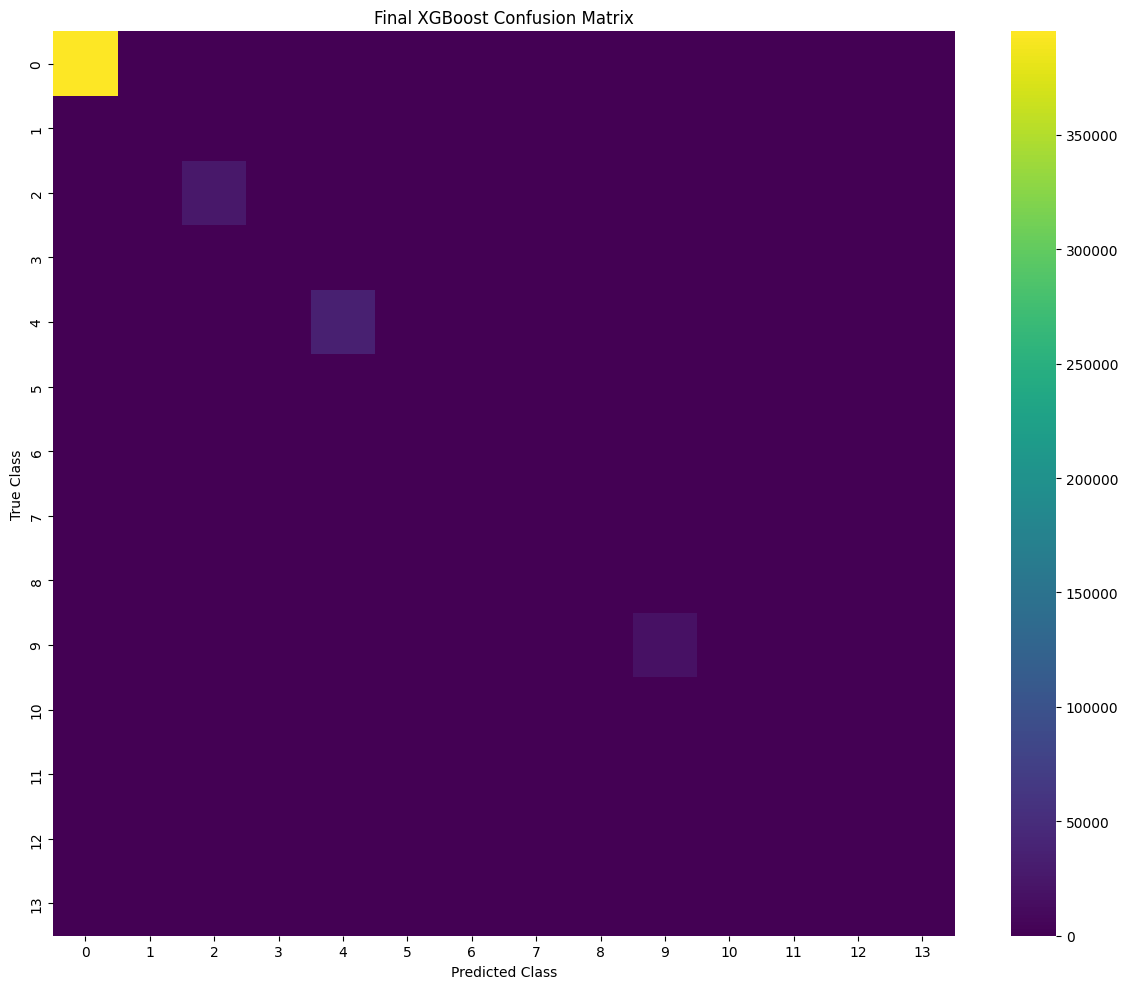


FINAL XGBOOST MISCLASSIFICATION SUMMARY
Total test samples      : 478,875
Correct predictions     : 478,259
Total misclassifications: 616
Error rate              : 0.1286%

Most common error:
Class 0 → Class 9: 216 samples

SAVED OUTPUTS
✓ Misclassification pairs CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_misclassification_pairs.csv

✓ Error contribution CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_error_contribution.csv

✓ Confusion matrix figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/final_xgboost_confusion_matrix.png

Misclassification CSV exists: True
Error contribution CSV exists: True
Figure exists: True

✅ CELL 37 COMPLETED


In [51]:
# =============================================================================
# CELL 37 — FINAL XGBOOST MISCLASSIFICATION ANALYSIS
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

print("=" * 90)
print("          CELL 37 — FINAL XGBOOST MISCLASSIFICATION ANALYSIS")
print("=" * 90)

# -----------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# -----------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 80)

required_vars = [
    "X_test",
    "y_test",
    "xgb_model"
]

for var in required_vars:
    if var in globals():
        print(f"✓ {var} available")
    else:
        raise NameError(
            f"Required variable '{var}' is not available."
        )

# -----------------------------------------------------------------------------
# GENERATE FINAL TEST PREDICTIONS
# -----------------------------------------------------------------------------

print("\nGENERATING FINAL XGBOOST TEST PREDICTIONS")
print("-" * 80)

y_pred_final = np.asarray(
    xgb_model.predict(X_test)
).reshape(-1)

print("✓ Predictions generated")
print(f"Prediction shape: {y_pred_final.shape}")

# -----------------------------------------------------------------------------
# PREPARE CLASSES
# -----------------------------------------------------------------------------

classes = np.unique(
    np.concatenate([
        np.asarray(y_test),
        np.asarray(y_pred_final)
    ])
)

print(f"\nNumber of classes: {len(classes)}")
print(f"Classes          : {classes}")

# -----------------------------------------------------------------------------
# CONFUSION MATRIX
# -----------------------------------------------------------------------------

print("\nGENERATING CONFUSION MATRIX")
print("-" * 80)

cm = confusion_matrix(
    y_test,
    y_pred_final,
    labels=classes
)

print(f"Confusion matrix shape: {cm.shape}")

# -----------------------------------------------------------------------------
# MISCLASSIFICATION PAIRS
# -----------------------------------------------------------------------------

print("\nEXTRACTING MISCLASSIFICATION PAIRS")
print("-" * 80)

misclassification_records = []

for i, true_class in enumerate(classes):

    for j, predicted_class in enumerate(classes):

        if i != j and cm[i, j] > 0:

            count = int(cm[i, j])

            true_total = int(cm[i].sum())

            percentage = (
                count / true_total
                if true_total > 0
                else 0
            )

            misclassification_records.append({
                "True Class": true_class,
                "Predicted Class": predicted_class,
                "Misclassified Samples": count,
                "Percentage of True Class": percentage
            })

misclassification_df = pd.DataFrame(
    misclassification_records
)

if len(misclassification_df) > 0:

    misclassification_df = (
        misclassification_df
        .sort_values(
            "Misclassified Samples",
            ascending=False
        )
        .reset_index(drop=True)
    )

else:

    misclassification_df = pd.DataFrame(
        columns=[
            "True Class",
            "Predicted Class",
            "Misclassified Samples",
            "Percentage of True Class"
        ]
    )

# -----------------------------------------------------------------------------
# DISPLAY TOP MISCLASSIFICATIONS
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("TOP XGBOOST MISCLASSIFICATION PAIRS")
print("=" * 90)

if len(misclassification_df) > 0:

    display_df = misclassification_df.head(20).copy()

    display_df[
        "Percentage of True Class"
    ] *= 100

    print(
        display_df.to_string(
            index=False,
            formatters={
                "Percentage of True Class":
                    "{:.4f}%".format
            }
        )
    )

else:

    print("✓ No misclassifications found.")

# -----------------------------------------------------------------------------
# OVERALL ERROR STATISTICS
# -----------------------------------------------------------------------------

total_samples = len(y_test)

correct_predictions = int(
    np.sum(
        np.asarray(y_test)
        == np.asarray(y_pred_final)
    )
)

incorrect_predictions = (
    total_samples
    - correct_predictions
)

accuracy = (
    correct_predictions
    / total_samples
)

error_rate = (
    incorrect_predictions
    / total_samples
)

print("\n" + "=" * 90)
print("OVERALL XGBOOST ERROR STATISTICS")
print("=" * 90)

print(
    f"Total samples          : "
    f"{total_samples:,}"
)

print(
    f"Correct predictions    : "
    f"{correct_predictions:,}"
)

print(
    f"Incorrect predictions  : "
    f"{incorrect_predictions:,}"
)

print(
    f"Accuracy               : "
    f"{accuracy:.6f}"
)

print(
    f"Error rate             : "
    f"{error_rate:.6f}"
)

# -----------------------------------------------------------------------------
# MOST COMMON MISCLASSIFICATION
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("MOST COMMON MISCLASSIFICATION")
print("=" * 90)

if len(misclassification_df) > 0:

    top_error = misclassification_df.iloc[0]

    print(
        f"True class             : "
        f"{int(top_error['True Class'])}"
    )

    print(
        f"Predicted class        : "
        f"{int(top_error['Predicted Class'])}"
    )

    print(
        f"Misclassified samples  : "
        f"{int(top_error['Misclassified Samples']):,}"
    )

    print(
        f"Percentage of true class: "
        f"{top_error['Percentage of True Class']:.4%}"
    )

# -----------------------------------------------------------------------------
# ERROR CONTRIBUTION BY TRUE CLASS
# -----------------------------------------------------------------------------

print("\nCALCULATING ERROR CONTRIBUTION BY TRUE CLASS")
print("-" * 80)

error_contribution_records = []

for i, class_label in enumerate(classes):

    true_count = int(cm[i].sum())

    correct_count = int(cm[i, i])

    incorrect_count = (
        true_count
        - correct_count
    )

    class_error_rate = (
        incorrect_count / true_count
        if true_count > 0
        else 0
    )

    error_contribution_records.append({
        "Class": class_label,
        "True Samples": true_count,
        "Correct Predictions": correct_count,
        "Incorrect Predictions": incorrect_count,
        "Error Rate": class_error_rate
    })

error_contribution_df = pd.DataFrame(
    error_contribution_records
)

total_errors = error_contribution_df[
    "Incorrect Predictions"
].sum()

if total_errors > 0:

    error_contribution_df[
        "Contribution to Total Errors"
    ] = (
        error_contribution_df[
            "Incorrect Predictions"
        ]
        / total_errors
    )

else:

    error_contribution_df[
        "Contribution to Total Errors"
    ] = 0

error_contribution_df = (
    error_contribution_df
    .sort_values(
        "Incorrect Predictions",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 90)
print("CLASS CONTRIBUTION TO TOTAL ERRORS")
print("=" * 90)

display_error_df = (
    error_contribution_df
    .copy()
)

display_error_df[
    "Error Rate"
] *= 100

display_error_df[
    "Contribution to Total Errors"
] *= 100

print(
    display_error_df.to_string(
        index=False,
        formatters={
            "Error Rate":
                "{:.4f}%".format,
            "Contribution to Total Errors":
                "{:.4f}%".format
        }
    )
)

# -----------------------------------------------------------------------------
# CREATE CONFUSION MATRIX FIGURE
# -----------------------------------------------------------------------------

print("\nCREATING CONFUSION MATRIX FIGURE")
print("-" * 80)

plt.figure(
    figsize=(12, 10)
)

sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    cmap="viridis",
    xticklabels=classes,
    yticklabels=classes
)

plt.title(
    "Final XGBoost Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.tight_layout()

# -----------------------------------------------------------------------------
# SAVE OUTPUTS
# -----------------------------------------------------------------------------

results_dir = (
    "/content/drive/MyDrive/"
    "AI-Cybersecurity-Assistant/results"
)

tables_dir = os.path.join(
    results_dir,
    "tables"
)

figures_dir = os.path.join(
    results_dir,
    "figures"
)

os.makedirs(
    tables_dir,
    exist_ok=True
)

os.makedirs(
    figures_dir,
    exist_ok=True
)

misclassification_csv = os.path.join(
    tables_dir,
    "final_xgboost_misclassification_pairs.csv"
)

error_contribution_csv = os.path.join(
    tables_dir,
    "final_xgboost_error_contribution.csv"
)

confusion_matrix_figure = os.path.join(
    figures_dir,
    "final_xgboost_confusion_matrix.png"
)

misclassification_df.to_csv(
    misclassification_csv,
    index=False
)

error_contribution_df.to_csv(
    error_contribution_csv,
    index=False
)

plt.savefig(
    confusion_matrix_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# -----------------------------------------------------------------------------
# FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL XGBOOST MISCLASSIFICATION SUMMARY")
print("=" * 90)

print(
    f"Total test samples      : "
    f"{total_samples:,}"
)

print(
    f"Correct predictions     : "
    f"{correct_predictions:,}"
)

print(
    f"Total misclassifications: "
    f"{incorrect_predictions:,}"
)

print(
    f"Error rate              : "
    f"{error_rate:.4%}"
)

if len(misclassification_df) > 0:

    print(
        "\nMost common error:"
    )

    print(
        f"Class "
        f"{int(top_error['True Class'])} → "
        f"Class "
        f"{int(top_error['Predicted Class'])}: "
        f"{int(top_error['Misclassified Samples']):,} samples"
    )

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print(
    "✓ Misclassification pairs CSV:"
)

print(
    misclassification_csv
)

print(
    "\n✓ Error contribution CSV:"
)

print(
    error_contribution_csv
)

print(
    "\n✓ Confusion matrix figure:"
)

print(
    confusion_matrix_figure
)

print(
    "\nMisclassification CSV exists:",
    os.path.exists(misclassification_csv)
)

print(
    "Error contribution CSV exists:",
    os.path.exists(error_contribution_csv)
)

print(
    "Figure exists:",
    os.path.exists(confusion_matrix_figure)
)

print("\n" + "=" * 90)
print("✅ CELL 37 COMPLETED")
print("=" * 90)

          CELL 38 — FINAL XGBOOST CLASS IMBALANCE ANALYSIS

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ X_train available
✓ y_train available
✓ X_test available
✓ y_test available
✓ xgb_model available

GENERATING FINAL XGBOOST PREDICTIONS
------------------------------------------------------------------------------------------
✓ Training predictions generated: (1723950,)
✓ Testing predictions generated : (478875,)

CLASS INFORMATION
------------------------------------------------------------------------------------------
Number of classes : 14
Classes           : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

CALCULATING OVERALL PERFORMANCE
------------------------------------------------------------------------------------------
Accuracy            : 0.998714
Balanced Accuracy   : 0.845601
Macro Precision     : 0.926422
Macro Recall        : 0.845601
Macro F1            : 0.872461
Weighted F1         : 0.998

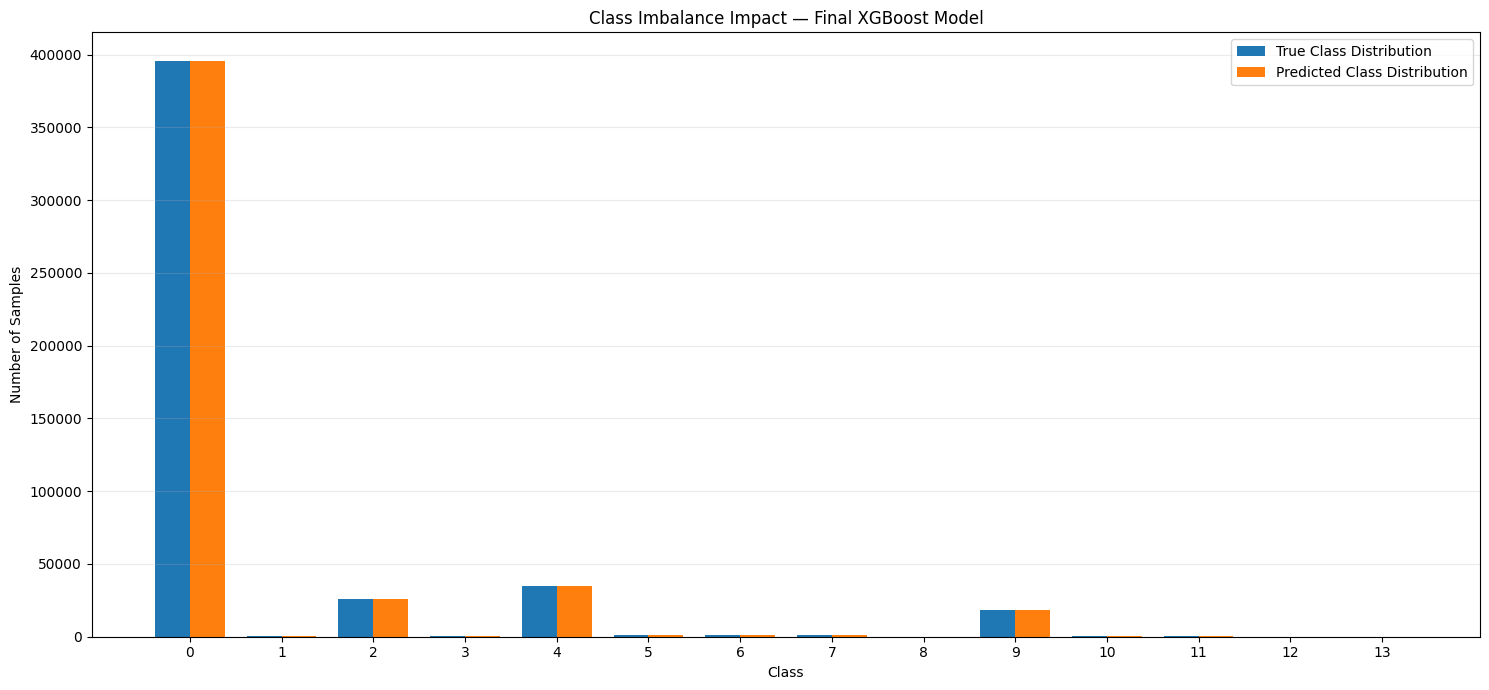


FINAL XGBOOST CLASS IMBALANCE SUMMARY
Testing Accuracy       : 0.998714
Balanced Accuracy      : 0.845601
Macro F1               : 0.872461
Weighted F1            : 0.998663

Majority class         : 0
Majority baseline      : 0.826023

Poorly detected classes: [13]
Zero-prediction classes: []

SAVED OUTPUTS
✓ Class imbalance CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_class_imbalance_analysis.csv
✓ Summary CSV:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/tables/final_xgboost_imbalance_summary.csv
✓ Class imbalance figure:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/figures/final_xgboost_class_imbalance_analysis.png

✅ CELL 38 COMPLETED


In [52]:
# =============================================================================
# CELL 38 — FINAL XGBOOST CLASS IMBALANCE ANALYSIS
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 90)
print("          CELL 38 — FINAL XGBOOST CLASS IMBALANCE ANALYSIS")
print("=" * 90)

# -----------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# -----------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_vars = ["X_train", "y_train", "X_test", "y_test", "xgb_model"]

for var in required_vars:
    if var not in globals():
        raise NameError(f"Required variable '{var}' is not available.")

print("✓ X_train available")
print("✓ y_train available")
print("✓ X_test available")
print("✓ y_test available")
print("✓ xgb_model available")

# -----------------------------------------------------------------------------
# GENERATE PREDICTIONS
# -----------------------------------------------------------------------------

print("\nGENERATING FINAL XGBOOST PREDICTIONS")
print("-" * 90)

y_train_pred = xgb_model.predict(X_train)
y_test_pred = xgb_model.predict(X_test)

print(f"✓ Training predictions generated: {y_train_pred.shape}")
print(f"✓ Testing predictions generated : {y_test_pred.shape}")

# -----------------------------------------------------------------------------
# CLASS INFORMATION
# -----------------------------------------------------------------------------

classes = np.unique(y_test)

print("\nCLASS INFORMATION")
print("-" * 90)
print(f"Number of classes : {len(classes)}")
print(f"Classes           : {classes}")

# -----------------------------------------------------------------------------
# OVERALL METRICS
# -----------------------------------------------------------------------------

print("\nCALCULATING OVERALL PERFORMANCE")
print("-" * 90)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_balanced_accuracy = balanced_accuracy_score(y_test, y_test_pred)

test_macro_precision = precision_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0
)

test_macro_recall = recall_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    y_test, y_test_pred,
    average="weighted",
    zero_division=0
)

print(f"Accuracy            : {test_accuracy:.6f}")
print(f"Balanced Accuracy   : {test_balanced_accuracy:.6f}")
print(f"Macro Precision     : {test_macro_precision:.6f}")
print(f"Macro Recall        : {test_macro_recall:.6f}")
print(f"Macro F1            : {test_macro_f1:.6f}")
print(f"Weighted F1         : {test_weighted_f1:.6f}")

# -----------------------------------------------------------------------------
# CLASS DISTRIBUTION ANALYSIS
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL XGBOOST CLASS DISTRIBUTION AND PERFORMANCE")
print("=" * 90)

true_counts = pd.Series(y_test).value_counts().reindex(classes, fill_value=0)
pred_counts = pd.Series(y_test_pred).value_counts().reindex(classes, fill_value=0)

rows = []

for cls in classes:

    true_mask = (y_test == cls)

    true_count = int(true_mask.sum())
    predicted_count = int((y_test_pred == cls).sum())
    correct_count = int(((y_test == cls) & (y_test_pred == cls)).sum())

    class_accuracy = (
        correct_count / true_count
        if true_count > 0 else 0
    )

    rows.append({
        "Class": int(cls),
        "True Count": true_count,
        "True Percentage": true_count / len(y_test),
        "Predicted Count": predicted_count,
        "Predicted Percentage": predicted_count / len(y_test),
        "Correct Predictions": correct_count,
        "Class Accuracy": class_accuracy,
        "Class Error Rate": 1 - class_accuracy
    })

class_imbalance_df = pd.DataFrame(rows)

print(class_imbalance_df.to_string(index=False))

# -----------------------------------------------------------------------------
# MAJORITY CLASS ANALYSIS
# -----------------------------------------------------------------------------

majority_class = int(true_counts.idxmax())
majority_count = int(true_counts.max())
majority_percentage = majority_count / len(y_test)

majority_baseline = majority_percentage
accuracy_improvement = test_accuracy - majority_baseline

print("\n" + "=" * 90)
print("MAJORITY CLASS IMPACT")
print("=" * 90)

print(f"Majority class                 : {majority_class}")
print(f"Majority class samples         : {majority_count:,}")
print(f"Majority class percentage      : {majority_percentage:.4%}")
print(f"Majority baseline accuracy     : {majority_baseline:.6f}")
print(f"XGBoost testing accuracy       : {test_accuracy:.6f}")
print(f"Improvement over baseline      : {accuracy_improvement:.6f}")

# -----------------------------------------------------------------------------
# IMBALANCE PERFORMANCE GAP
# -----------------------------------------------------------------------------

accuracy_balanced_gap = test_accuracy - test_balanced_accuracy
weighted_macro_gap = test_weighted_f1 - test_macro_f1

print("\n" + "=" * 90)
print("CLASS IMBALANCE PERFORMANCE GAP")
print("=" * 90)

print(f"Accuracy - Balanced Accuracy : {accuracy_balanced_gap:.6f}")
print(f"Weighted F1 - Macro F1       : {weighted_macro_gap:.6f}")

# -----------------------------------------------------------------------------
# POORLY DETECTED CLASSES
# -----------------------------------------------------------------------------

poor_classes = class_imbalance_df[
    class_imbalance_df["Class Accuracy"] < 0.50
]["Class"].tolist()

zero_prediction_classes = class_imbalance_df[
    class_imbalance_df["Predicted Count"] == 0
]["Class"].tolist()

print("\n" + "=" * 90)
print("POORLY DETECTED CLASSES")
print("=" * 90)

if poor_classes:
    print(f"Classes with accuracy < 50%: {poor_classes}")
else:
    print("✓ No classes have accuracy below 50%.")

print("\n" + "=" * 90)
print("ZERO-PREDICTION CLASSES")
print("=" * 90)

if zero_prediction_classes:
    print(f"Classes never predicted: {zero_prediction_classes}")
else:
    print("✓ All classes were predicted at least once.")

# -----------------------------------------------------------------------------
# WORST CLASSES
# -----------------------------------------------------------------------------

worst_class_row = class_imbalance_df.loc[
    class_imbalance_df["Class Accuracy"].idxmin()
]

best_class_row = class_imbalance_df.loc[
    class_imbalance_df["Class Accuracy"].idxmax()
]

print("\n" + "=" * 90)
print("CLASS PERFORMANCE SUMMARY")
print("=" * 90)

print(
    f"Worst class : {int(worst_class_row['Class'])} "
    f"| Accuracy: {worst_class_row['Class Accuracy']:.4f} "
    f"| Error Rate: {worst_class_row['Class Error Rate']:.4f}"
)

print(
    f"Best class  : {int(best_class_row['Class'])} "
    f"| Accuracy: {best_class_row['Class Accuracy']:.4f} "
    f"| Error Rate: {best_class_row['Class Error Rate']:.4f}"
)

# -----------------------------------------------------------------------------
# INTERPRETATION
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("CLASS IMBALANCE INTERPRETATION")
print("=" * 90)

if accuracy_balanced_gap > 0.10:
    print("⚠ Large difference between accuracy and balanced accuracy detected.")
    print("  Overall accuracy is strongly influenced by class imbalance.")
elif accuracy_balanced_gap > 0.05:
    print("⚠ Noticeable difference between accuracy and balanced accuracy detected.")
    print("  Minority-class performance should be considered alongside accuracy.")
else:
    print("✓ Accuracy and balanced accuracy are relatively close.")

if weighted_macro_gap > 0.10:
    print("⚠ Weighted F1 is substantially higher than Macro F1.")
    print("  Performance is considerably stronger on high-frequency classes.")
elif weighted_macro_gap > 0.05:
    print("⚠ Weighted F1 is higher than Macro F1.")
    print("  Class frequency affects the overall weighted performance.")
else:
    print("✓ Weighted and Macro F1 are relatively close.")

if len(poor_classes) > 0:
    print(f"⚠ {len(poor_classes)} class(es) have accuracy below 50%.")

# -----------------------------------------------------------------------------
# SAVE TABLE
# -----------------------------------------------------------------------------

results_dir = "/content/drive/MyDrive/AI-Cybersecurity-Assistant/results"

tables_dir = os.path.join(results_dir, "tables")
figures_dir = os.path.join(results_dir, "figures")

os.makedirs(tables_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)

imbalance_csv = os.path.join(
    tables_dir,
    "final_xgboost_class_imbalance_analysis.csv"
)

class_imbalance_df.to_csv(
    imbalance_csv,
    index=False
)

# -----------------------------------------------------------------------------
# SAVE SUMMARY
# -----------------------------------------------------------------------------

imbalance_summary = pd.DataFrame([{
    "Model": "XGBoost",
    "Accuracy": test_accuracy,
    "Balanced Accuracy": test_balanced_accuracy,
    "Macro Precision": test_macro_precision,
    "Macro Recall": test_macro_recall,
    "Macro F1": test_macro_f1,
    "Weighted F1": test_weighted_f1,
    "Majority Class": majority_class,
    "Majority Class Percentage": majority_percentage,
    "Majority Baseline Accuracy": majority_baseline,
    "Accuracy Improvement Over Baseline": accuracy_improvement,
    "Accuracy Balanced Accuracy Gap": accuracy_balanced_gap,
    "Weighted F1 Macro F1 Gap": weighted_macro_gap,
    "Poorly Detected Classes": str(poor_classes),
    "Zero Prediction Classes": str(zero_prediction_classes)
}])

summary_csv = os.path.join(
    tables_dir,
    "final_xgboost_imbalance_summary.csv"
)

imbalance_summary.to_csv(
    summary_csv,
    index=False
)

print("\n" + "=" * 90)
print("SAVED ANALYSIS TABLES")
print("=" * 90)

print(f"✓ Class imbalance CSV:")
print(imbalance_csv)

print(f"\n✓ Imbalance summary CSV:")
print(summary_csv)

# -----------------------------------------------------------------------------
# CREATE FIGURE
# -----------------------------------------------------------------------------

print("\nCREATING CLASS IMBALANCE FIGURE")
print("-" * 90)

x = np.arange(len(classes))
width = 0.38

plt.figure(figsize=(15, 7))

plt.bar(
    x - width / 2,
    true_counts.values,
    width,
    label="True Class Distribution"
)

plt.bar(
    x + width / 2,
    pred_counts.values,
    width,
    label="Predicted Class Distribution"
)

plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Class Imbalance Impact — Final XGBoost Model")

plt.xticks(x, classes)
plt.legend()
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

imbalance_figure = os.path.join(
    figures_dir,
    "final_xgboost_class_imbalance_analysis.png"
)

plt.savefig(
    imbalance_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# -----------------------------------------------------------------------------
# FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL XGBOOST CLASS IMBALANCE SUMMARY")
print("=" * 90)

print(f"Testing Accuracy       : {test_accuracy:.6f}")
print(f"Balanced Accuracy      : {test_balanced_accuracy:.6f}")
print(f"Macro F1               : {test_macro_f1:.6f}")
print(f"Weighted F1            : {test_weighted_f1:.6f}")

print(f"\nMajority class         : {majority_class}")
print(f"Majority baseline      : {majority_baseline:.6f}")

print(f"\nPoorly detected classes: {poor_classes}")
print(f"Zero-prediction classes: {zero_prediction_classes}")

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print(f"✓ Class imbalance CSV:")
print(imbalance_csv)

print(f"✓ Summary CSV:")
print(summary_csv)

print(f"✓ Class imbalance figure:")
print(imbalance_figure)

print("\n" + "=" * 90)
print("✅ CELL 38 COMPLETED")
print("=" * 90)

In [53]:
# ==========================================================================================
#          CELL 39 — EXPLAINABLE AI (XAI) / SHAP SETUP
# ==========================================================================================

print("=" * 90)
print("          CELL 39 — EXPLAINABLE AI (XAI) / SHAP SETUP")
print("=" * 90)

# ------------------------------------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# ------------------------------------------------------------------------------------------

print("\nCHECKING REQUIRED VARIABLES")
print("-" * 90)

required_variables = [
    "X_train",
    "y_train",
    "X_test",
    "y_test",
    "xgb_model"
]

missing_variables = []

for variable in required_variables:
    if variable in globals():
        print(f"✓ {variable} available")
    else:
        print(f"✗ {variable} NOT available")
        missing_variables.append(variable)

if missing_variables:
    raise NameError(
        f"Missing required variables: {missing_variables}"
    )

# ------------------------------------------------------------------------------------------
# IMPORT SHAP
# ------------------------------------------------------------------------------------------

print("\nCHECKING SHAP LIBRARY")
print("-" * 90)

try:
    import shap
    print(f"✓ SHAP available")
    print(f"  SHAP version: {shap.__version__}")
except ImportError:
    print("SHAP is not installed.")
    print("Installing SHAP...")

    !pip install -q shap

    import shap
    print(f"✓ SHAP installed successfully")
    print(f"  SHAP version: {shap.__version__}")

# ------------------------------------------------------------------------------------------
# VERIFY FINAL MODEL
# ------------------------------------------------------------------------------------------

print("\nVERIFYING FINAL MODEL")
print("-" * 90)

print(f"✓ Final model object: {type(xgb_model).__name__}")

# ------------------------------------------------------------------------------------------
# DATA INFORMATION
# ------------------------------------------------------------------------------------------

print("\nDATA INFORMATION")
print("-" * 90)

print(f"Training data shape : {X_train.shape}")
print(f"Testing data shape  : {X_test.shape}")
print(f"Training labels     : {y_train.shape}")
print(f"Testing labels      : {y_test.shape}")

# ------------------------------------------------------------------------------------------
# CLASS INFORMATION
# ------------------------------------------------------------------------------------------

print("\nCLASS INFORMATION")
print("-" * 90)

import numpy as np

classes = np.unique(y_test)

print(f"Number of classes : {len(classes)}")
print(f"Classes           : {classes}")

# ------------------------------------------------------------------------------------------
# FEATURE INFORMATION
# ------------------------------------------------------------------------------------------

print("\nFEATURE INFORMATION")
print("-" * 90)

if hasattr(X_test, "columns"):
    feature_names = list(X_test.columns)
else:
    feature_names = [f"Feature_{i}" for i in range(X_test.shape[1])]

print(f"Number of features: {len(feature_names)}")
print(f"First features:")
print(feature_names[:10])

# ------------------------------------------------------------------------------------------
# VERIFY MODEL CLASS COUNT
# ------------------------------------------------------------------------------------------

print("\nMODEL CLASS VERIFICATION")
print("-" * 90)

if hasattr(xgb_model, "classes_"):
    print(f"Model classes: {xgb_model.classes_}")
else:
    print("✓ XGBoost model does not expose classes_ directly.")
    print("  Class count will be determined from predictions.")

# ------------------------------------------------------------------------------------------
# GENERATE A SMALL TEST SAMPLE FOR INITIAL XAI
# ------------------------------------------------------------------------------------------

print("\nPREPARING XAI SAMPLE")
print("-" * 90)

# Use a manageable sample for SHAP analysis.
# The complete test set contains 478,875 samples, which is unnecessarily
# expensive for initial explainability analysis.

XAI_SAMPLE_SIZE = min(5000, len(X_test))

np.random.seed(42)

sample_indices = np.random.choice(
    len(X_test),
    size=XAI_SAMPLE_SIZE,
    replace=False
)

X_test_xai = X_test.iloc[sample_indices].copy() if hasattr(
    X_test, "iloc"
) else X_test[sample_indices]

y_test_xai = y_test.iloc[sample_indices].copy() if hasattr(
    y_test, "iloc"
) else y_test[sample_indices]

print(f"✓ XAI sample prepared")
print(f"XAI sample shape  : {X_test_xai.shape}")
print(f"XAI labels shape  : {y_test_xai.shape}")
print(f"XAI sample size   : {XAI_SAMPLE_SIZE}")

# ------------------------------------------------------------------------------------------
# GENERATE SAMPLE PREDICTIONS
# ------------------------------------------------------------------------------------------

print("\nGENERATING SAMPLE PREDICTIONS")
print("-" * 90)

xai_predictions = xgb_model.predict(X_test_xai)

print("✓ Sample predictions generated")
print(f"Prediction shape: {xai_predictions.shape}")

# ------------------------------------------------------------------------------------------
# SAMPLE ACCURACY
# ------------------------------------------------------------------------------------------

sample_accuracy = np.mean(
    np.asarray(xai_predictions).reshape(-1)
    ==
    np.asarray(y_test_xai).reshape(-1)
)

print(f"Sample accuracy: {sample_accuracy:.6f}")

# ------------------------------------------------------------------------------------------
# XAI OBJECT INITIALIZATION
# ------------------------------------------------------------------------------------------

print("\nINITIALIZING SHAP EXPLAINER")
print("-" * 90)

try:
    explainer = shap.TreeExplainer(xgb_model)

    print("✓ SHAP TreeExplainer initialized successfully")

except Exception as e:
    print("✗ Could not initialize SHAP TreeExplainer")
    print(f"Error: {e}")
    raise

# ------------------------------------------------------------------------------------------
# SAVE XAI CONFIGURATION
# ------------------------------------------------------------------------------------------

import os
import pandas as pd

base_path = "/content/drive/MyDrive/AI-Cybersecurity-Assistant"

tables_path = os.path.join(
    base_path,
    "results",
    "tables"
)

figures_path = os.path.join(
    base_path,
    "results",
    "figures"
)

reports_path = os.path.join(
    base_path,
    "results",
    "reports"
)

os.makedirs(tables_path, exist_ok=True)
os.makedirs(figures_path, exist_ok=True)
os.makedirs(reports_path, exist_ok=True)

xai_summary = pd.DataFrame({
    "Parameter": [
        "Final Model",
        "Model Family",
        "Number of Classes",
        "Number of Features",
        "Training Samples",
        "Testing Samples",
        "XAI Sample Size",
        "Random Seed"
    ],
    "Value": [
        "XGBoost",
        "Multiclass ML",
        len(classes),
        len(feature_names),
        len(X_train),
        len(X_test),
        XAI_SAMPLE_SIZE,
        42
    ]
})

xai_summary_path = os.path.join(
    tables_path,
    "final_xgboost_xai_configuration.csv"
)

xai_summary.to_csv(
    xai_summary_path,
    index=False
)

print("\n" + "=" * 90)
print("XAI SETUP SUMMARY")
print("=" * 90)

print(f"Final model       : XGBoost")
print(f"Number of classes : {len(classes)}")
print(f"Number of features: {len(feature_names)}")
print(f"XAI sample size   : {XAI_SAMPLE_SIZE}")
print(f"SHAP explainer    : TreeExplainer")

print("\n" + "=" * 90)
print("SAVED OUTPUTS")
print("=" * 90)

print(f"✓ XAI configuration CSV:")
print(xai_summary_path)

print(
    f"Configuration file exists: "
    f"{os.path.exists(xai_summary_path)}"
)

print("\n" + "=" * 90)
print("✅ CELL 39 COMPLETED")
print("=" * 90)

          CELL 39 — EXPLAINABLE AI (XAI) / SHAP SETUP

CHECKING REQUIRED VARIABLES
------------------------------------------------------------------------------------------
✓ X_train available
✓ y_train available
✓ X_test available
✓ y_test available
✓ xgb_model available

CHECKING SHAP LIBRARY
------------------------------------------------------------------------------------------
✓ SHAP available
  SHAP version: 0.52.0

VERIFYING FINAL MODEL
------------------------------------------------------------------------------------------
✓ Final model object: XGBClassifier

DATA INFORMATION
------------------------------------------------------------------------------------------
Training data shape : (1723950, 78)
Testing data shape  : (478875, 78)
Training labels     : (1723950,)
Testing labels      : (478875,)

CLASS INFORMATION
------------------------------------------------------------------------------------------
Number of classes : 14
Classes           : [ 0  1  2  3  4  5  6  7